# prepare dependents

### func & pkg

In [1]:
WORKER = NULL

library(GCrutils)

INPUTROOT = 'export_c3'
OUTPUTROOT = 'report_c3'

# source('[lib_path]/yutils.R')
# source('[lib_path]/yplot.R')
options(repr.plot.width=10
       # , repr.plot.height=8
        ,repr.matrix.max.cols=30
        ,repr.matrix.max.rows=6
       )
library(tidyverse)
# theme<-theme_get()
# #using the Chinese fonts you have, check it with font book.
# theme$text$family<-"WenQuanYi Zen Hei"
# theme_set(theme)
# par(family = "WenQuanYi Zen Hei")
library(ComplexHeatmap)

Loading required package: magrittr

Loading required package: dplyr


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Loading required package: ggplot2

Loading required package: stringr

Loading required package: tibble

Loading required package: ggfortify

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.0     ✔ readr     2.1.5
✔ lubridate 1.9.3     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ tidyr::extract()  

### set color

In [2]:
npg = ggsci::pal_npg()(10)
sps = ggsci::pal_simpsons()(16)
aaas = ggsci::pal_aaas()(10)

ANNO_LABEL_FONTSIZE = 6
ANNO_NAME_FONTSIZE = 6
LEGEND_TITLE_FONTSIZE = 6


COL_ANNO = list(
    NEPC = c(F='#00A087FF',T='#DC0000FF'),
    Cribriform = c(F='#00A087FF',T='#DC0000FF'),
    Group = c(C1='#F04923',C2='#3BA9DD',C3='#7CC242',pCR='#E18727'),
    # sps palette
#     RNA_Cluster = c(C1='#FED439FF',C2='#709AE1FF',C3='#8A9197FF',C4='#D2AF81FF',pCR='#4DBBD5FF'),
#     Protein_Cluster = c(C1='#FED439FF',C2='#709AE1FF',C3='#8A9197FF',C4='#D2AF81FF',pCR='#4DBBD5FF'),
    # Group = c(non.pCR='#E64B35FF',pCR='#4DBBD5FF'),
    
    # nejm palette
    MD = c("0"="gray10","1"="#8b8a75","2"="#ae8833",'3'='#c75e63','x'='gray10'),
#     MD=c('0'="#FFC300",'1'="#FF5733",'2'="#C70039",'3'="#581845", 'x'="gray"),
#     MD=c('0'="#86DD45",'1'="#57348B",'2'="#C70039",'3'="#581845", 'x'="gray"),
    
    Response = c(non.pCR='#6F99ADFF',pCR='#E18727FF'),
#     Protein_Cluster = c(C1='#BC3C29FF',C2='#0072B5FF',C3='#20854EFF',C4='#7876B1FF',pCR='#E18727FF'),
    Protein_Cluster = c(C1='#F04923',C2='#3BA9DD',C3='#7CC242',C4='#9080BA',pCR='#E18727'),
    Cluster_tsne = c(C1='#F04923',C2='#3BA9DD',C3='#7CC242',C4='#9080BA',pCR='#E18727',adj='#A3A500'),
    RNA_Cluster = c(C1='#F04923',C2='#3BA9DD',C3='#7CC242',C4='#9080BA',pCR='#E18727'),
#     sex = c(Female='#E64B35FF',Male='#4DBBD5FF'),
#     Response = c("0"='#00A087FF',I='#B09C85FF',II='#4DBBD5FF',III='#DC0000FF'),
    Cluster3 = c(C1='#F04923',C2='#3BA9DD',Co='#8A9197'),
    `Cluster3+1`= c(C1='#F04923',C2='#3BA9DD',Co='#8A9197',pCR='#E18727FF'),
    # used in t-SNE RNA
    Response2 = c(pCR='#E18727',adj='#A3A500',I='#00BF7D',II='#00B0F6',III='#E76BF3'),
    HM = c("HighMan"='black',"PauciMan"='red'),
    Fu=c("FUC" = 'black', "CoreFUC"='red'),
    SA=c("SIA"='black'),
    Bs=c("Bisect"='black'),
    set = c(Train='#198E5C',Valid='#EF7F29'),
    Clin_classification =  c(C1='#F04923',C2='#3BA9DD',C3='#7CC242',pCR='#E18727')
    
)

COL_HEATMAP_F = circlize::colorRamp2(c(-2,-1,0,1,2), colors=c('#0000FF','#7447F4','white','#F75839','#FF0000'),space='RGB')
COL_HEATMAP_2_F = circlize::colorRamp2(c(-2,0,2), colors=c('#0000FF','white','#FF0000'),space='RGB')
COL_HEATMAP_0_F = circlize::colorRamp2(c(0,5,10), colors=c('#FFF4EF','#D46547','#5C0810'),space='RGB') # 
COL_HEATMAP_1_F = circlize::colorRamp2(c(-1,0,1), colors=c('#0000FF','white','#FF0000'),space='RGB')
COL_HEATMAP_075_F = circlize::colorRamp2(c(-0.75,0,0.75), colors=c('#0000FF','white','#FF0000'),space='RGB')
COL_HEATMAP_05_F = circlize::colorRamp2(c(-0.5,0,0.5), colors=c('#0000FF','white','#FF0000'),space='RGB')
COL_CORELATION = c(Neu='gray', Pos=npg[1],Neg = npg[2])
COL_HEATMAP_04_F = circlize::colorRamp2(c(-0.4,0,0.4), colors=c('#0000FF','white','#FF0000'),space='RGB')

COL_ANNO_3G = list(Group=c(C1='#F04923',C2='#3BA9DD',C3='#7CC242'),
                   Cohort=c(Train='#198E5C',Valid='#EF7F29'))

COL_BCR = list(G2 = c('#ffaf00','#3c5486')
               , pT = c('#ffaf00','#3c5486','#E18727')
               , MDAnderson = c("0"="#E18727","1"="#8b8a75","2"="#ae8833",'3' = '#c75e63')
              )


# # 棒棒糖图颜色
COL_POINTS = c(`1st-Gen`=npg[1],`2nd-Gen`=npg[1])
ygen_set_color_scheme()
map_color_cnv2 = structure(c('CN<1','CN>4','CN<1.2','CN>3'), 
                           names=c('Frame_Shift_Del','Frame_Shift_Ins','In_Frame_Del','In_Frame_Ins'))

COL_SNV2 = c(
    `Frame_Shift_Del`='#DEB887',
    `Missense_Mutation`='#5CA7FF',
    `Frame_Shift_Ins`='#473C8B',
    `Splice_Site`='#C1CDC1',
    `Translation_Start_Site`='#FB9A99',
    `Nonsense_Mutation`='#EEDD82',
    `Nonstop_Mutation`='#F9A64B',
    `In_Frame_Del`='#80010A',
    `In_Frame_Ins`='#CAB2D6',
    `5'UTR`='#F15200',
    `Multi_Hit`='#FF425D',
    `Intron`= '#709AE1',
    `Inferred`= '#AAAAAA'
)
COL_CNV2 = COL_CNV[names(map_color_cnv2)] 
names(COL_CNV2) =  map_color_cnv2[names(COL_CNV2)]

COL_WES = c(COL_SNV,COL_CNV2)



theme_pc = function(){
    theme_void(base_size = 20) %+replace%    #replace elements we want to change
        theme(axis.text.x = element_text(angle = 0,hjust=0.5,vjust = 0.5)
            #           , axis.line.x.top = element_line()
            #           , axis.line.y.right = element_line()
            ,axis.ticks = element_line()
            ,axis.ticks.length = unit(0.15,'cm')
            #           ,plot.background = element_rect()
            ,legend.position="top"
            ,panel.border = element_rect(fill = NA, linewidth = unit(0.5,'pt'))
            ,legend.key.size = unit(0.3, 'cm'), #change legend key size
            legend.key.height = unit(0.3, 'cm'), #change legend key height
            legend.key.width = unit(0.3, 'cm'), #change legend key width
            legend.title = element_text(size=8), #change legend title font size
            legend.text = element_text(size=7),
            axis.text = element_text(color = 'black'),
        ) 
}

[1] "global var COL_SNV, COL_CNV, COL_TITV have been set."


# Fig1

## fig 1B 1C 1G 1H S1E S1F (retrospective train86), fig S3D S3E (all138) BCR RR

### load data

In [19]:
library(survival)
plot_bcr = function(data, ti){
    g1 =c()
    g2 = c()
    pval = c()
    msg = c()
    grps = data$Group %>% unique
    cat(ti, grps,'\n')
    for (g in combn(grps,2,simplify = FALSE)){
        diff_AB <- survival::survdiff(Surv(BCR_month, BCR_status) ~ Group, data = data, subset = Group %in% g,  rho = 0)
        g1 %<>% c(g[1])
        g2 %<>% c(g[2])
        pval %<>% c(diff_AB$pvalue)
        
        msg %<>% c(paste(g[1],'vs',g[2],'pval =',sprintf(paste0("%.", 4, "f"), diff_AB$pvalue),'\n'))
    }
    sum = data %>% group_by(Group) %>% summarise(n = n())
    for (i in 1:nrow(sum)){
        msg %<>% c(paste(sum[i, 'Group'],' = ',sum[i, 'n'],'\n', sep = ''))
    }
    stats = data.frame(g1=g1,g2=g2,pval=pval)
    msg = msg %>% str_flatten()
    
    fit = survfit(Surv(BCR_month, BCR_status) ~ Group, data = data)
    fig = survminer::ggsurvplot(fit, data = data
#                                   , palette =  COL_Group3
                         ,risk.table = TRUE # Add risk table
                         ,pval = TRUE # Add p-value
                         ,conf.int = FALSE # Add confidence interval
    #                      ,risk.table.col = "strata"
    #                      ,test.for.trend = TRUE
                         ,surv.median.line = 'hv'
                        ,color = 'Group'
    #                     , color = COL_ANNO_3G$Group3
                        ,break.x.by = 15
                         ,xlab = 'Time (Months)'
    #                      ,xlim=c(0,90)
                        ,title=paste(ti)
                        )
    
    fig$plot = fig$plot %+% annotate("text", x = Inf, y = Inf, label = msg, 
                  hjust = 1.1, vjust = 1.1, 
                  size = 3, color = "black", 
                  family = "sans", 
                  parse = FALSE)  %+%
        theme(text = element_text(size = 24)) 
    if (ti == 'Response'){
         fig$plot = fig$plot %+%
            scale_color_manual(name ='Group', values = c('#E18727','#3c5486'), breaks = c('pCR','non.pCR'))
    }else if(length(grps) == 2){
        fig$plot = fig$plot %+%
            scale_color_manual(name ='Group', values = COL_BCR$G2)
    }else if (ti == 'MD.Anderson.classification'){
         fig$plot = fig$plot %+%
            scale_color_manual(name ='Group', values = COL_BCR$MDAnderson, breaks = names(COL_BCR$MDAnderson))  
    } else if(length(grps)==3){
         fig$plot = fig$plot %+%
            scale_color_manual(name ='Group', values = COL_BCR$pT, breaks = names(COL_BCR$pT))
    }else if (length(grps) == 4){
        fig$plot = fig$plot %+%
            scale_color_manual(name ='Group', values = COL_ANNO$Group, breaks = names(COL_ANNO$Group))
    }
    fig
}
plot_rgr = function(data, ti){
    g1 =c()
    g2 = c()
    pval = c()
    msg = c()
    grps = data$Group %>% unique
    cat(ti, grps,'\n')
    for (g in combn(grps,2,simplify = FALSE)){
        diff_AB <- survival::survdiff(Surv(RGR_month, RGR_status) ~ Group, data = data, subset = Group %in% g,  rho = 0)
        g1 %<>% c(g[1])
        g2 %<>% c(g[2])
        pval %<>% c(diff_AB$pvalue)
        
        msg %<>% c(paste(g[1],'vs',g[2],'pval =',sprintf(paste0("%.", 4, "f"), diff_AB$pvalue),'\n'))
    }
    sum = data %>% group_by(Group) %>% summarise(n = n())
    for (i in 1:nrow(sum)){
        msg %<>% c(paste(sum[i, 'Group'],' = ',sum[i, 'n'],'\n', sep = ''))
    }
    stats = data.frame(g1=g1,g2=g2,pval=pval)
    msg = msg %>% str_flatten()
    
    fit = survfit(Surv(RGR_month, RGR_status) ~ Group, data = data)
    fig = survminer::ggsurvplot(fit, data = data
#                                   , palette =  COL_Group3
                         ,risk.table = TRUE # Add risk table
                         ,pval = TRUE # Add p-value
                         ,conf.int = FALSE # Add confidence interval
    #                      ,risk.table.col = "strata"
    #                      ,test.for.trend = TRUE
                         ,surv.median.line = 'hv'
                        ,color = 'Group'
    #                     , color = COL_ANNO_3G$Group3
                        ,break.x.by = 15
                         ,xlab = 'Time (Months)'
    #                      ,xlim=c(0,90)
                        ,title=paste(ti)
                        )
    
    fig$plot = fig$plot %+% annotate("text", x = Inf, y = Inf, label = msg, 
                  hjust = 1.1, vjust = 1.1, 
                  size = 3, color = "black", 
                  family = "sans", 
                  parse = FALSE)  %+%
        theme(text = element_text(size = 24)) 
    if (ti == 'Response'){
         fig$plot = fig$plot %+%
            scale_color_manual(name='Group', values = c('#E18727','#3c5486'), breaks = c('pCR','non.pCR'))
    }else if(length(grps) == 2){
        fig$plot = fig$plot %+%
            scale_color_manual(name='Group', values = COL_BCR$G2)
    }else if (ti == 'MD.Anderson.classification'){
         fig$plot = fig$plot %+%
            scale_color_manual(name='Group', values = COL_BCR$MDAnderson, breaks = names(COL_BCR$MDAnderson))  
    } else if(length(grps)==3){
         fig$plot = fig$plot %+%
            scale_color_manual(name='Group', values = COL_BCR$pT, breaks = names(COL_BCR$pT))
    }else if (length(grps) == 4){
        fig$plot = fig$plot %+%
            scale_color_manual(name='Group', values = COL_ANNO$Group, breaks = names(COL_ANNO$Group))
    }
    fig
}

load_os = function(){
#     glx = db.importing('export_c3/glx_86.dfx') %>% rename(Custom_Label = tsb )
    # NOTE: 该文件为上游产物(本项目代码中无生成 cell),需在生成处同时输出到 export_c3/ (供读取) 与 report_c3/ (结果副本)
    glx = db.importing('export_c3/fig1_subtype_predict_and_pca_data.xlsx') %>%
        rename(Custom_Label=X1)
       
#     glxv = db.importing('external_info/Proteomics52/washed/prt_glx.dfx') %>%mutate(Response = Group, Group = 'UC')
#     glxall = glx %>% 
#         select(Custom_Label, uid, Group, Response) %>%
#         mutate(source ='train86', .before = Group) %>%
#         mutate(Group = 'UC') %>%
#         rbind(glxv)
    clin2 = db.importing('external_data/Fig1_heatmap_clinical_pathological_information.txt')
    os = clin2 %>% select(Custom_Label
                        , BCR_status 
                        , BCR_month = `BCR-free.time`
                        , RGR_status = `Radiographic.recurrence`
                        , RGR_month = `Radiographic.recurrence-free.time`
                        ) %>%
        mutate(BCR_status = as.numeric(BCR_status)
               , BCR_month = as.numeric(BCR_month)
               , RGR_status = as.numeric(RGR_status)
               , RGR_month = as.numeric(RGR_month)
              ) %>% left_join(glx,by='Custom_Label')
    
    os %>% mutate(
        Set = ifelse(is.na(Set), ifelse(str_length(Custom_Label) == 3,'Train','Valid') ,Set)
#         , Group = ifelse(is.na(Group),'pCR', Group)
        , Cluster = ifelse(is.na(Cluster),'pCR', Cluster)
        , source = ifelse(Set=='Train','train86','valid52')
    ) %>% select(-x,-y)
}

gen_data_raw = function(os){
    clin = db.importing('external_data/Fig1_heatmap_clinical_pathological_information.txt') %>% rename(tsb = Custom_Label)

    data = os # %>% filter(Response == 'non.pCR', source =='train86')
    clin2 = clin %>% 
        select(tsb
               , Gleason.score
                , Clinical.T.stage
                , Clinical.N.stage
                , MD.Anderson.classification
                , `PSA.(≥20.ng/ml).(at.diagnosis.before.NAT)`
                , `PSA.(≥0.2.ng/ml).(before.RP).(after.NAT)`
                , `PSA.(≥0.2.ng/ml).(after.RP.6weeks)`
                , pT.stage 
                , `pN.lymph.node.metastasis.(at.RP)`
                , Surgical.margins
                , Perineural.invasion 
                , Capsule.invasion 
                , Semina.vesicle
               ) %>%
        mutate(Gleason.score = ifelse(Gleason.score >=9,'≥9','<9')
               , Clinical.T.stage = ifelse(Clinical.T.stage=='Tx', NA, ifelse(str_starts(Clinical.T.stage,fixed('T2')),'T2','T3,T4'))
               , Clinical.N.stage = ifelse(Clinical.N.stage=='Nx', NA, Clinical.N.stage)
               , pT.stage = ifelse(pT.stage=='pCR','pCR',ifelse(str_starts(pT.stage,fixed('T2')),'T2',"T3,T4"))
                ) %>%
        arrange(match(tsb, data$Custom_Label))
    colnames(clin2) = colnames(clin2) %>% make.names()
    clin2 = clin2 %>% column_to_rownames('tsb')
    clin2

    stopifnot((data$Custom_Label==rownames(clin2)) %>%all)
    data = os #%>% filter(Response == 'non.pCR', source =='train86')
    data = data %>% select(-sel_organ,-Set,-Group)%>% cbind(clin2) %>% select(-Custom_Label) %>% 
        mutate(Response = ifelse(Cluster=='pCR','pCR','non.pCR'),.before = Gleason.score)
    data_raw = data
    data
}


In [20]:
os = load_os() 
os

[1] "[ 2026-08-03 08:30:09 ]  read [ fig1_subtype_predict_and_pca_data.xlsx ] as ' fig1_subtype_predict_and_pca_data ' from >  export_c3"
[1] "[ 2026-08-03 08:30:09 ]  read [ Fig1_heatmap_clinical_pathological_information.txt ] as ' Fig1_heatmap_clinical_pathological_information ' from >  external_data"


Custom_Label,BCR_status,BCR_month,RGR_status,RGR_month,Set,Group,Cluster,sel_organ,source
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>
P01,0,35,0,35,Train,C3,C3,NA,train86
P02,0,22,0,22,Train,C3,C3,NA,train86
P03,0,27,0,27,Train,C3,C3,NA,train86
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
P136,0,16,0,16,Valid,NA,pCR,NA,valid52
P137,1,2,0,6,Valid,organ,C3,-48,valid52
P138,0,3,0,4,Valid,organ,C3,-49,valid52


In [21]:
data_raw = gen_data_raw(os)
data_raw

[1] "[ 2026-08-03 08:30:09 ]  read [ Fig1_heatmap_clinical_pathological_information.txt ] as ' Fig1_heatmap_clinical_pathological_information ' from >  external_data"


BCR_status,BCR_month,RGR_status,RGR_month,Cluster,source,Response,Gleason.score,Clinical.T.stage,Clinical.N.stage,MD.Anderson.classification,PSA...20.ng.ml...at.diagnosis.before.NAT.,PSA...0.2.ng.ml...before.RP...after.NAT.,PSA...0.2.ng.ml...after.RP.6weeks.,pT.stage,pN.lymph.node.metastasis..at.RP.,Surgical.margins,Perineural.invasion,Capsule.invasion,Semina.vesicle
<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<int>,<int>,<chr>,<chr>,<int>,<int>,<int>,<int>
0,35,0,35,C3,train86,non.pCR,<9,T2,N0,1,1,0,0,"T3,T4",N0,1,1,0,1
0,22,0,22,C3,train86,non.pCR,<9,T2,N0,1,0,0,0,T2,N0,0,0,0,0
0,27,0,27,C3,train86,non.pCR,<9,T2,N0,1,1,0,0,T2,N0,0,0,0,0
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
0,16,0,16,pCR,valid52,pCR,<9,"T3,T4",N0,0,1,1,0,pCR,N0,0,0,0,0
1,2,0,6,C3,valid52,non.pCR,<9,T2,N0,1,1,1,0,"T3,T4",N0,1,1,1,0
0,3,0,4,C3,valid52,non.pCR,<9,T2,N0,1,1,1,0,T2,N0,0,0,0,0


### calc p value

In [22]:
df =  data_raw %>% mutate(across(matches("^[^_]+$"),.fns = factor))
df

BCR_status,BCR_month,RGR_status,RGR_month,Cluster,source,Response,Gleason.score,Clinical.T.stage,Clinical.N.stage,MD.Anderson.classification,PSA...20.ng.ml...at.diagnosis.before.NAT.,PSA...0.2.ng.ml...before.RP...after.NAT.,PSA...0.2.ng.ml...after.RP.6weeks.,pT.stage,pN.lymph.node.metastasis..at.RP.,Surgical.margins,Perineural.invasion,Capsule.invasion,Semina.vesicle
<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>
0,35,0,35,C3,train86,non.pCR,<9,T2,N0,1,1,0,0,"T3,T4",N0,1,1,0,1
0,22,0,22,C3,train86,non.pCR,<9,T2,N0,1,0,0,0,T2,N0,0,0,0,0
0,27,0,27,C3,train86,non.pCR,<9,T2,N0,1,1,0,0,T2,N0,0,0,0,0
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
0,16,0,16,pCR,valid52,pCR,<9,"T3,T4",N0,0,1,1,0,pCR,N0,0,0,0,0
1,2,0,6,C3,valid52,non.pCR,<9,T2,N0,1,1,1,0,"T3,T4",N0,1,1,1,0
0,3,0,4,C3,valid52,non.pCR,<9,T2,N0,1,1,1,0,T2,N0,0,0,0,0


In [23]:
features = colnames(df)
features = features[!(str_starts(features, fixed('BCR_')) | str_starts(features, fixed('RGR_')) | features=='source')]
features
length(features)

[1] "Cluster"                                  
 [2] "Response"                                 
 [3] "Gleason.score"                            
 [4] "Clinical.T.stage"                         
 [5] "Clinical.N.stage"                         
 [6] "MD.Anderson.classification"               
 [7] "PSA...20.ng.ml...at.diagnosis.before.NAT."
 [8] "PSA...0.2.ng.ml...before.RP...after.NAT." 
 [9] "PSA...0.2.ng.ml...after.RP.6weeks."       
[10] "pT.stage"                                 
[11] "pN.lymph.node.metastasis..at.RP."         
[12] "Surgical.margins"                         
[13] "Perineural.invasion"                      
[14] "Capsule.invasion"                         
[15] "Semina.vesicle"

[1] 15

In [24]:
ypvalue_add_asterisks = function (pvalues) 
{
    pvalues %>% purrr::map_chr(function(p) {
        if (is.na(p)) return(NA)
        if (p < 1e-04) {
            return("****")
        }
        else if (p < 0.001) {
            return("***")
        }
        else if (p < 0.01) {
            return("**")
        }
        else if (p < 0.05) {
            return("*")
        }
        else {
            return("ns")
        }
    })
}

surv_obj = Surv(time = df$BCR_month, event = df$BCR_status)

cox_model = coxph(
  surv_obj ~ `Cluster`+`Gleason.score`+`Clinical.T.stage`+
    `Clinical.N.stage`+`MD.Anderson.classification`+
    `PSA...0.2.ng.ml...before.RP...after.NAT.`+
    `pT.stage`+`pN.lymph.node.metastasis..at.RP.`+`Surgical.margins`#+
    #`Perineural.invasion`+`Capsule.invasion`+`Semina.vesicle`
    
  ,data = df
)

# 提取模型摘要
summ <- summary(cox_model)

# 提取系数表和置信区间表
coef_df <- as.data.frame(summ$coefficients)
confint_df <- as.data.frame(summ$conf.int)

# 合并两个表（按行名匹配）
result_df <- cbind(
  coef_df,
  HR = confint_df[, "exp(coef)"],
  HR_lower = confint_df[, "lower .95"],
  HR_upper = confint_df[, "upper .95"]
)

# 保留关键列并重命名
result_df <- result_df %>%
  dplyr::select(
    Coef = coef,
    SE = `se(coef)`,
    Z = z,
    P = `Pr(>|z|)`,
    HR,
    HR_lower,
    HR_upper
  )

# 将行名（变量名）转换为列
df_bcr <- tibble::rownames_to_column(result_df, var = "Variable") %>%
    mutate(p.sig = ifelse(is.na(P),NA,ypvalue_add_asterisks(P)))


In [25]:
df_bcr %>%echo

Variable,Coef,SE,Z,P,HR,HR_lower,HR_upper,p.sig
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
ClusterC2,-0.59944515,0.4010845,-1.494560714,0.135029125,5.491162e-01,0.25018457,1.205225,ns
ClusterC3,-0.44440151,0.3500408,-1.269570601,0.204237627,6.412079e-01,0.32288183,1.273369,ns
ClusterpCR,-18.26252285,3438.2561905,-0.005311565,0.995762004,1.171351e-08,0.00000000,Inf,ns
Gleason.score≥9,0.06518854,0.2874145,0.226810226,0.820571312,1.067360e+00,0.60766383,1.874816,ns
"Clinical.T.stageT3,T4",0.25616071,0.3069684,0.834485553,0.404007425,1.291960e+00,0.70787601,2.357986,ns
Clinical.N.stageN1,0.11613589,0.3411112,0.340463462,0.733507534,1.123148e+00,0.57554970,2.191753,ns
MD.Anderson.classification1,-0.94775863,0.8469576,-1.119015403,0.263133568,3.876088e-01,0.07369907,2.038568,ns
MD.Anderson.classification2,-0.40315988,0.8140551,-0.495248913,0.620424428,6.682053e-01,0.13551425,3.294844,ns
MD.Anderson.classification3,NA,0.0000000,NA,NA,NA,NA,NA,NA


In [26]:
surv_obj = Surv(time = df$RGR_month, event = df$RGR_status)

cox_model = coxph(
  surv_obj ~ `Cluster`+`Gleason.score`+`Clinical.T.stage`+
    `Clinical.N.stage`+`MD.Anderson.classification`+
    `PSA...0.2.ng.ml...before.RP...after.NAT.`+
    `pT.stage`+`pN.lymph.node.metastasis..at.RP.`+`Surgical.margins`#+
    #`Perineural.invasion`+`Capsule.invasion`+`Semina.vesicle`
    
  ,data = df
)

# 提取模型摘要
summ <- summary(cox_model)

# 提取系数表和置信区间表
coef_df <- as.data.frame(summ$coefficients)
confint_df <- as.data.frame(summ$conf.int)

# 合并两个表（按行名匹配）
result_df <- cbind(
  coef_df,
  HR = confint_df[, "exp(coef)"],
  HR_lower = confint_df[, "lower .95"],
  HR_upper = confint_df[, "upper .95"]
)

# 保留关键列并重命名
result_df <- result_df %>%
  dplyr::select(
    Coef = coef,
    SE = `se(coef)`,
    Z = z,
    P = `Pr(>|z|)`,
    HR,
    HR_lower,
    HR_upper
  )

# 将行名（变量名）转换为列
df_rgr <- tibble::rownames_to_column(result_df, var = "Variable") %>%
    mutate(p.sig = ifelse(is.na(P),NA,ypvalue_add_asterisks(P)))


In [27]:
df_rgr %>%echo

Variable,Coef,SE,Z,P,HR,HR_lower,HR_upper,p.sig
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
ClusterC2,-1.91660586,0.7608793,-2.518935565,0.01177102,1.471054e-01,0.0331106,0.6535672,*
ClusterC3,-1.04259952,0.5227516,-1.994445484,0.04610339,3.525371e-01,0.1265429,0.9821362,*
ClusterpCR,-18.08706545,6028.3519492,-0.003000333,0.99760608,1.396006e-08,0.0000000,Inf,ns
Gleason.score≥9,0.36792120,0.4747450,0.774987038,0.43834732,1.444728e+00,0.5697476,3.6634460,ns
"Clinical.T.stageT3,T4",1.52220600,0.6192202,2.458262964,0.01396109,4.582323e+00,1.3614588,15.4229278,*
Clinical.N.stageN1,-0.08053628,0.5630895,-0.143025736,0.88626986,9.226214e-01,0.3059996,2.7818016,ns
MD.Anderson.classification1,0.65288149,1.2567997,0.519479341,0.60342652,1.921068e+00,0.1635886,22.5596674,ns
MD.Anderson.classification2,0.07755447,1.1581579,0.066963635,0.94661065,1.080641e+00,0.1116492,10.4594130,ns
MD.Anderson.classification3,NA,0.0000000,NA,NA,NA,NA,NA,NA


In [28]:
result_df %>% ysave('fig.1B.1C.S1E.S1F','cox_multivariate')

[1] "[ 2026-08-03 08:30:09 ]  write 1 xlsx at report_c3/fig.1B.1C.S1E.S1F_cox_multivariate.xlsx"


### fig 1B 1G S1E S1F BCR (train86); fig S3D BCR (all138)

In [29]:
# lab = db.importing('export_c3/fig1_subtype_predict_and_pca_data.xlsx') %>%rename(Custom_Label=X1)
# lab

In [30]:
features

[1] "Cluster"                                  
 [2] "Response"                                 
 [3] "Gleason.score"                            
 [4] "Clinical.T.stage"                         
 [5] "Clinical.N.stage"                         
 [6] "MD.Anderson.classification"               
 [7] "PSA...20.ng.ml...at.diagnosis.before.NAT."
 [8] "PSA...0.2.ng.ml...before.RP...after.NAT." 
 [9] "PSA...0.2.ng.ml...after.RP.6weeks."       
[10] "pT.stage"                                 
[11] "pN.lymph.node.metastasis..at.RP."         
[12] "Surgical.margins"                         
[13] "Perineural.invasion"                      
[14] "Capsule.invasion"                         
[15] "Semina.vesicle"

In [31]:
make.custom(4.2,4)
ggs_bcr = list()
ggs_bcr_data = list()
options(warn = -1)
for (grp in c('all138','train86','valid52')){
    if (grp != 'all138'){
        data = data_raw %>% filter(source==!!grp)
    }else{
        data = data_raw
    }
    collect = list()
    collect_d = list()
    for (f in features){
        
        data$Group = data[[f]]
        d = data %>% filter(Group %>% is.na %>% not, Group!='Nx') %>% select(BCR_status, BCR_month, Group) 
        if (nrow(d) != 0) {
            sur.gg = plot_bcr(d, ti = f)
            gg = sur.gg$plot + 
                    ylab('PSA recurrence-free\nSurvival probability')
            collect[[length(collect)+1]] = gg
            collect_d[[f]] = d
        }
    } 
    ggs_bcr[[grp]] = collect
    ggs_bcr_data[[grp]] = collect_d
}

options(warn = 0)

Cluster C3 C2 C1 pCR 
Response non.pCR pCR 
Gleason.score <9 ≥9 
Clinical.T.stage T2 T3,T4 
Clinical.N.stage N0 N1 
MD.Anderson.classification 1 2 0 3 
PSA...20.ng.ml...at.diagnosis.before.NAT. 1 0 
PSA...0.2.ng.ml...before.RP...after.NAT. 0 1 
PSA...0.2.ng.ml...after.RP.6weeks. 0 1 
pT.stage T3,T4 T2 pCR 
pN.lymph.node.metastasis..at.RP. N0 N1 
Surgical.margins 1 0 
Perineural.invasion 1 0 
Capsule.invasion 0 1 
Semina.vesicle 1 0 
Cluster C3 C2 C1 pCR 
Response non.pCR pCR 
Gleason.score <9 ≥9 
Clinical.T.stage T2 T3,T4 
Clinical.N.stage N0 N1 
MD.Anderson.classification 1 2 0 3 
PSA...20.ng.ml...at.diagnosis.before.NAT. 1 0 
PSA...0.2.ng.ml...before.RP...after.NAT. 0 1 
PSA...0.2.ng.ml...after.RP.6weeks. 0 1 
pT.stage T3,T4 T2 pCR 
pN.lymph.node.metastasis..at.RP. N0 N1 
Surgical.margins 1 0 
Perineural.invasion 1 0 
Capsule.invasion 0 1 
Semina.vesicle 1 0 
Cluster C1 C3 C2 pCR 
Response non.pCR pCR 
Gleason.score ≥9 <9 
Clinical.T.stage T2 T3,T4 
Clinical.N.stage N1 N0 
MD.Anderso

[1] "[ 2026-08-03 08:46:55 ]  write 1 pdf at report_c3/fig.S3D_all138_BCR.pdf"
[1] "[ 2026-08-03 08:46:55 ]  write 1 xlsx at report_c3/fig.S3D_all138_BCR.xlsx"


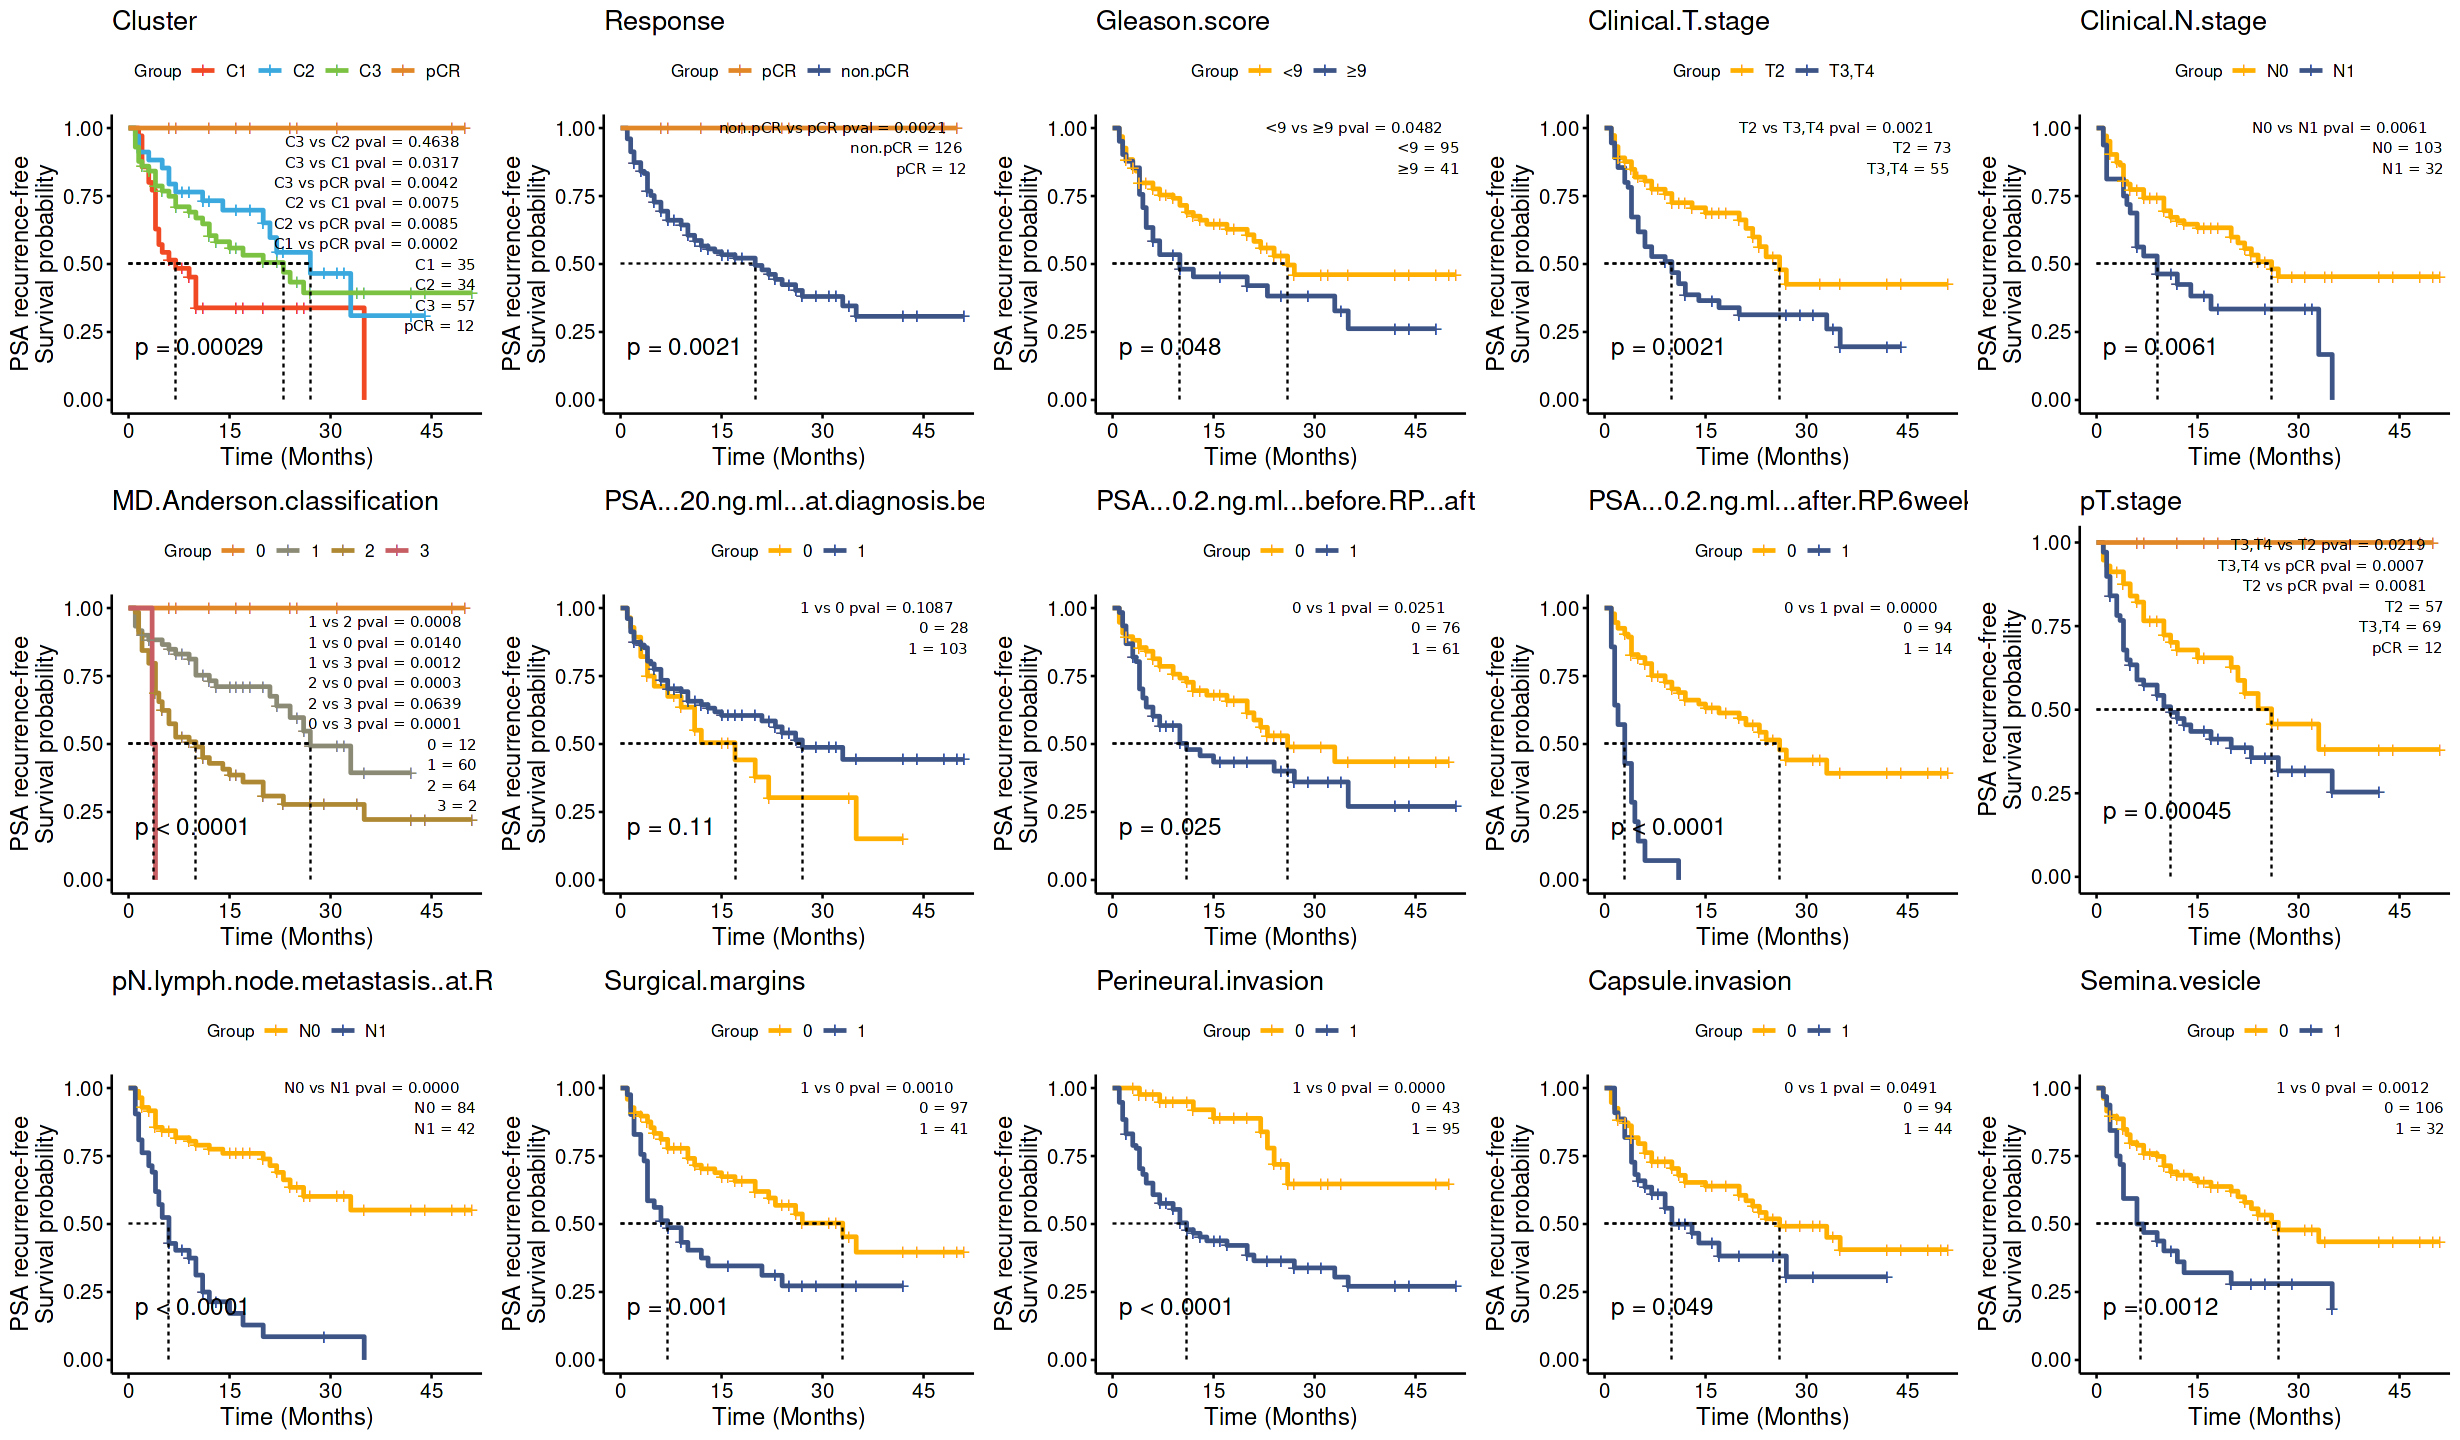

[1] "[ 2026-08-03 08:47:01 ]  write 1 pdf at report_c3/fig.1B.1G.S1E.S1F_train86_BCR.pdf"
[1] "[ 2026-08-03 08:47:01 ]  write 1 xlsx at report_c3/fig.1B.1G.S1E.S1F_train86_BCR.xlsx"


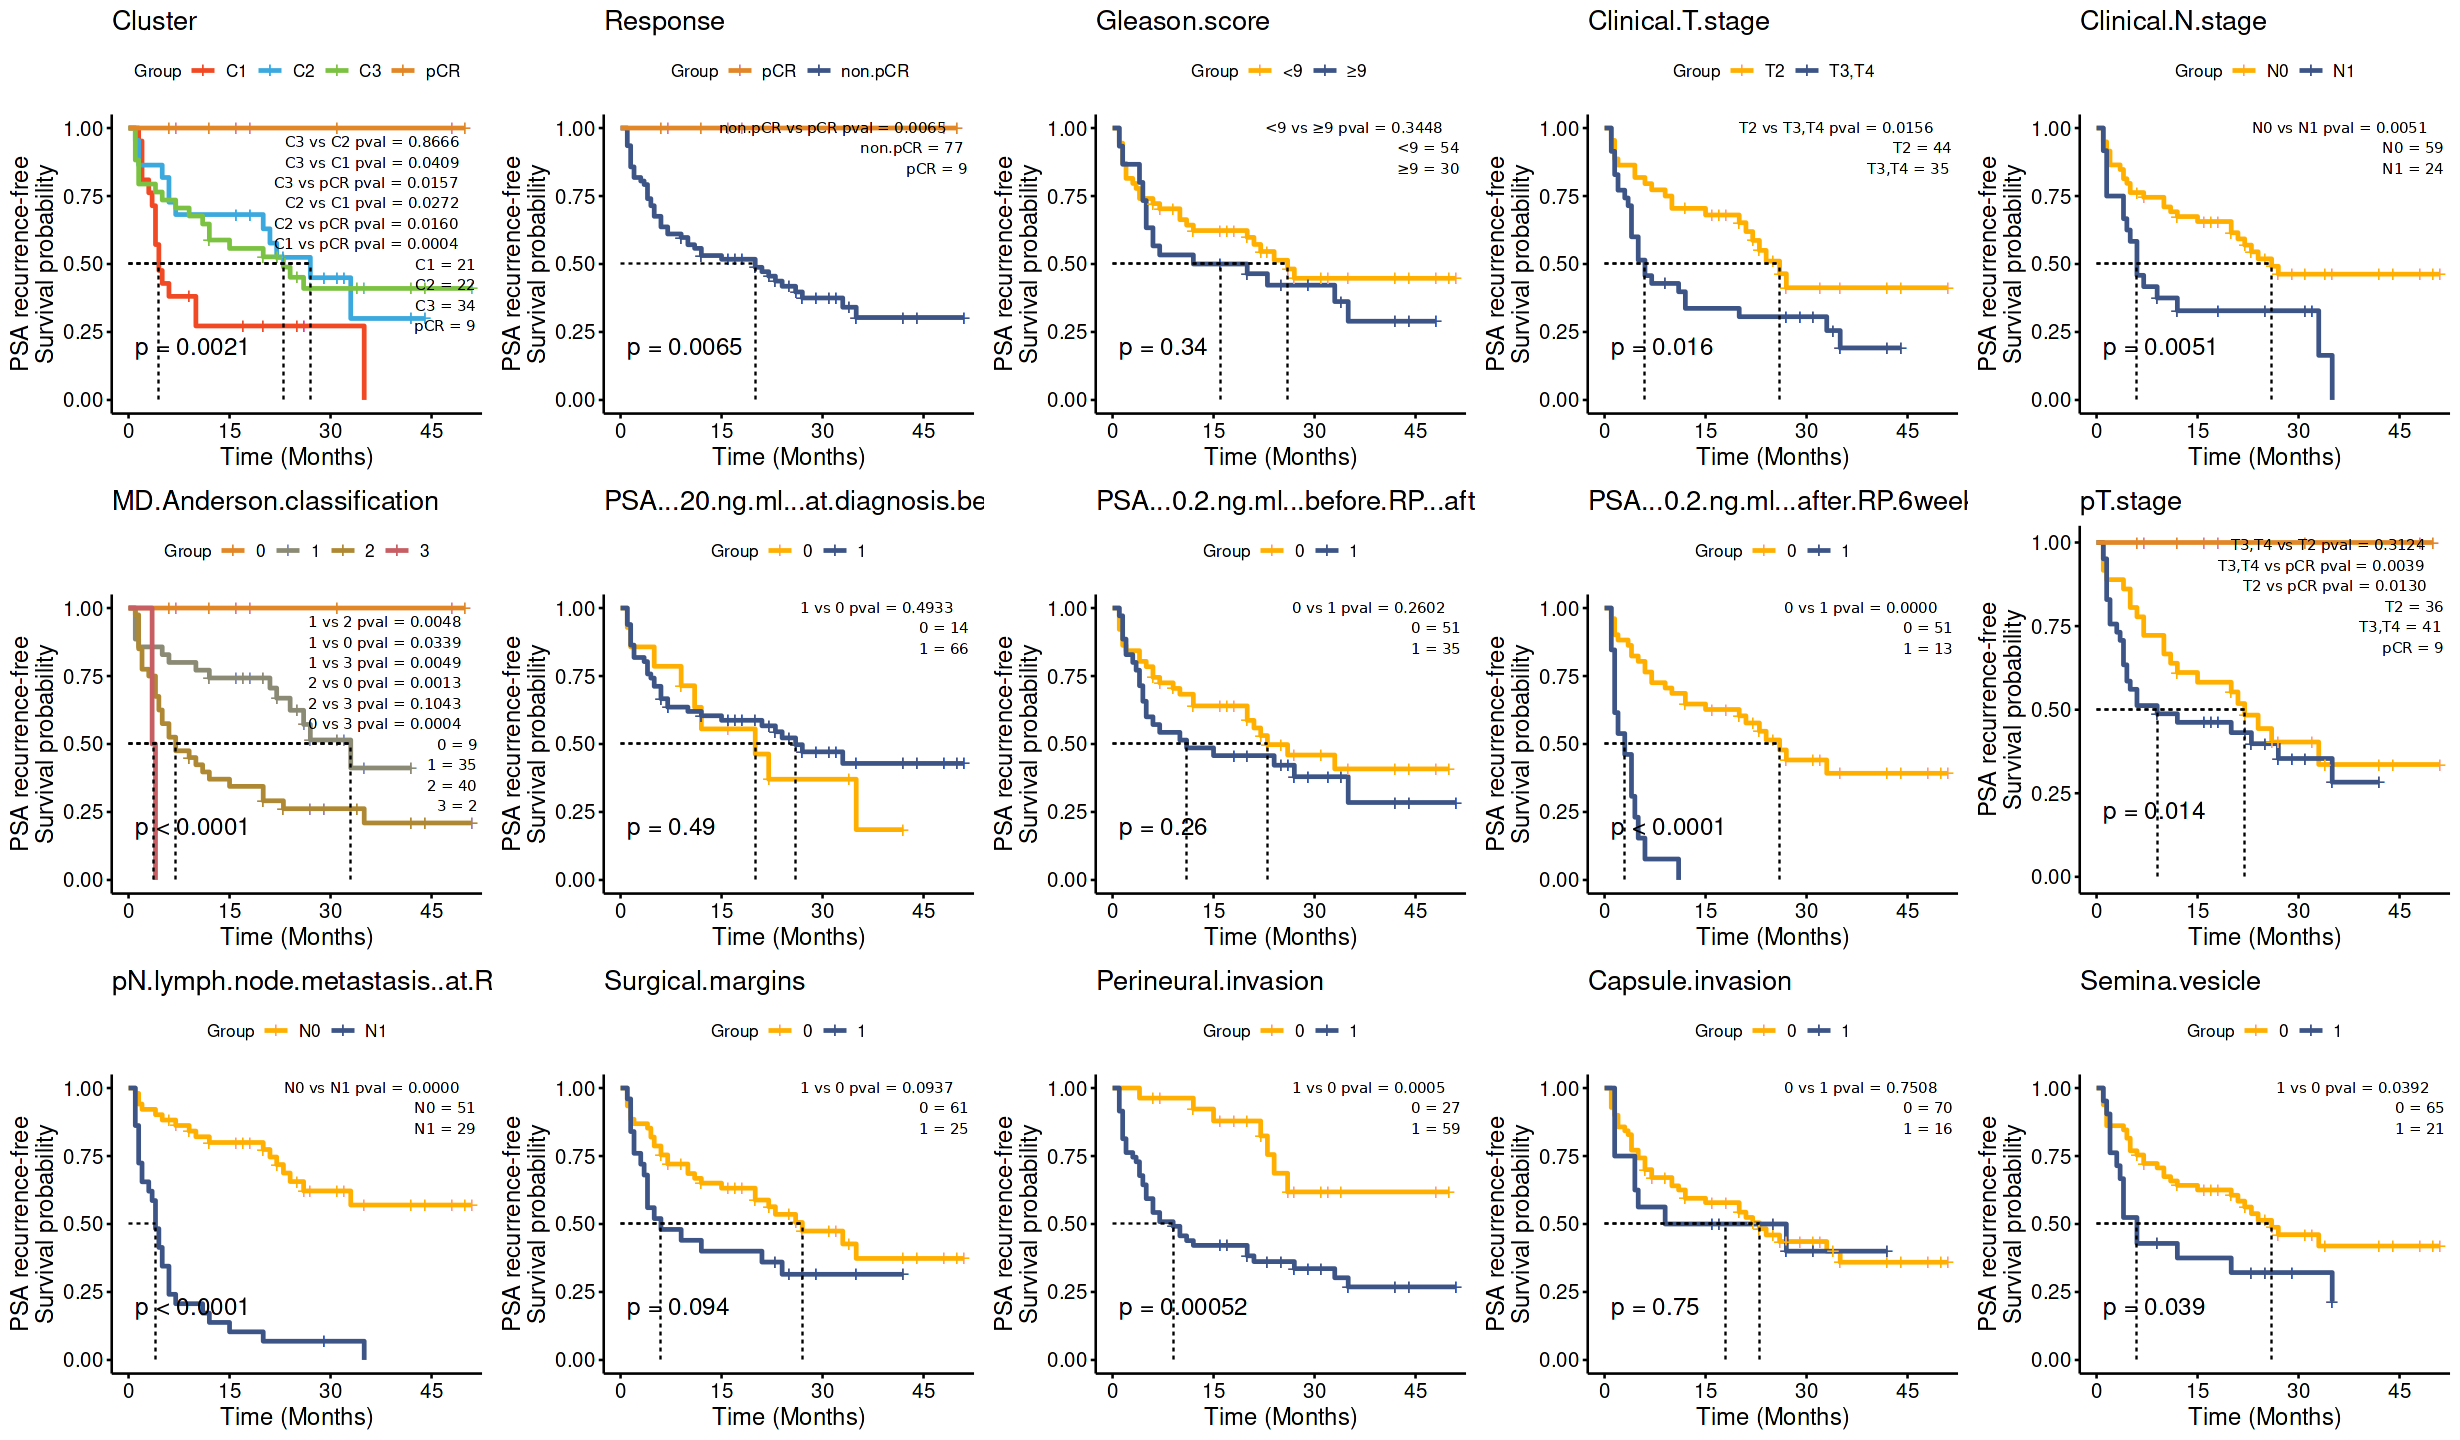

[1] "[ 2026-08-03 08:47:09 ]  write 1 pdf at report_c3/fig.unused_valid52_BCR.pdf"
[1] "[ 2026-08-03 08:47:09 ]  write 1 xlsx at report_c3/fig.unused_valid52_BCR.xlsx"


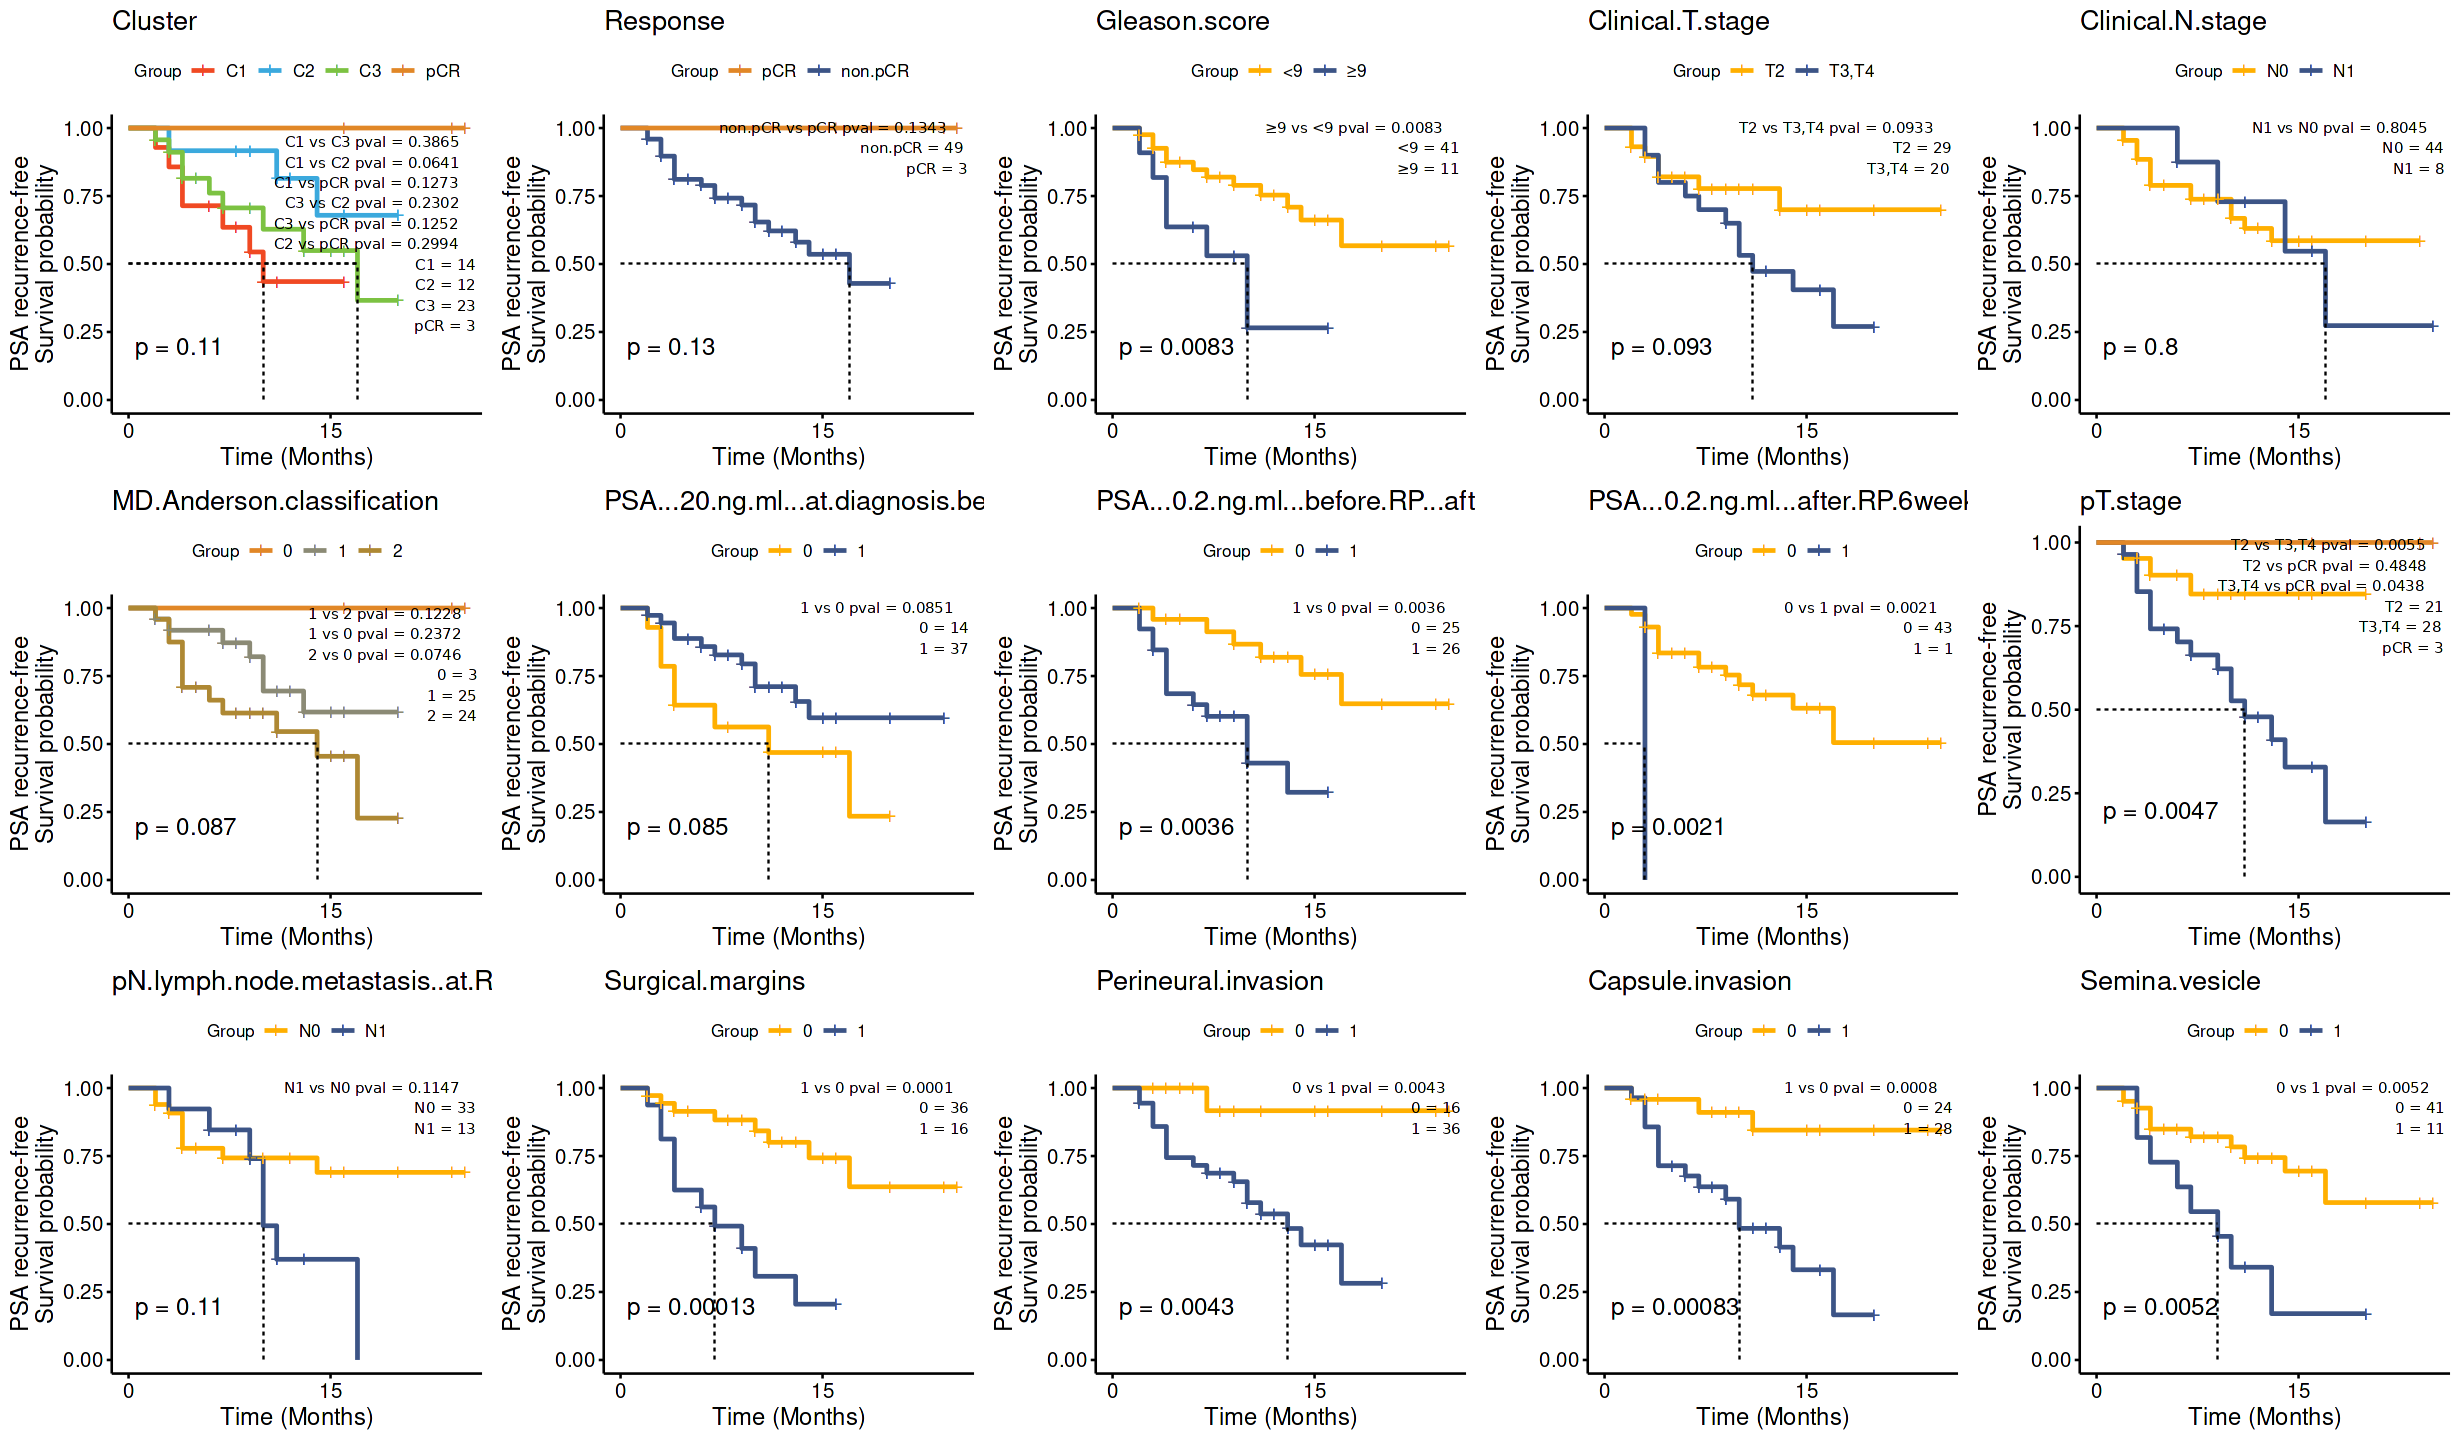

In [135]:
options(warn = -1)
make.custom(4.1*5, 4*3)
for (grp in names(ggs_bcr)){
    # all138 -> article fig S3D; train86 -> article fig 1/S1 panels; valid52 (prospective) has no article figure
    fig_lab = switch(grp, all138='fig.S3D', train86='fig.1B.1G.S1E.S1F', valid52='fig.unused')
    gg = cowplot::plot_grid(plotlist = ggs_bcr[[grp]], ncol=5)
    print(gg)
    gg %>% ysave(fig_lab,grp,'BCR', outputdir = file.path('report_c3'))
    ggs_bcr_data[[grp]] %>% ysave(fig_lab,grp,'BCR', outputdir = file.path('report_c3'))
}
options(warn = 0)

### fig 1C 1H S1E S1F RGR (train86); fig S3E RGR (all138)

In [136]:
make.custom(4.2,4)
ggs_rgr = list()
ggs_rgr_data = list()
options(warn = -1)
for (grp in c('all138','train86','valid52')){
    if (grp != 'all138'){
        data = data_raw %>% filter(source==!!grp)
    }else{
        data = data_raw
    }
    collect = list()
    collect_d = list()
    for (f in features){
        data$Group = data[[f]]
        d = data %>% filter(Group %>% is.na %>% not, Group!='Nx') %>% select(RGR_status, RGR_month, Group) 
        if (nrow(d) != 0) {
            sur.gg = plot_rgr(d, ti = f)
            gg = sur.gg$plot + 
                    ylab('Radiographic recurrence-free\nSurvival probability')
            collect[[length(collect)+1]] = gg
            collect_d[[f]] = d
        }
    } 
    ggs_rgr[[grp]] = collect
    ggs_rgr_data[[grp]] = collect_d
}

options(warn = 0)


Cluster C3 C2 C1 pCR 
Response non.pCR pCR 
Gleason.score <9 ≥9 
Clinical.T.stage T2 T3,T4 
Clinical.N.stage N0 N1 
MD.Anderson.classification 1 2 0 3 
PSA...20.ng.ml...at.diagnosis.before.NAT. 1 0 
PSA...0.2.ng.ml...before.RP...after.NAT. 0 1 
PSA...0.2.ng.ml...after.RP.6weeks. 0 1 
pT.stage T3,T4 T2 pCR 
pN.lymph.node.metastasis..at.RP. N0 N1 
Surgical.margins 1 0 
Perineural.invasion 1 0 
Capsule.invasion 0 1 
Semina.vesicle 1 0 
Cluster C3 C2 C1 pCR 
Response non.pCR pCR 
Gleason.score <9 ≥9 
Clinical.T.stage T2 T3,T4 
Clinical.N.stage N0 N1 
MD.Anderson.classification 1 2 0 3 
PSA...20.ng.ml...at.diagnosis.before.NAT. 1 0 
PSA...0.2.ng.ml...before.RP...after.NAT. 0 1 
PSA...0.2.ng.ml...after.RP.6weeks. 0 1 
pT.stage T3,T4 T2 pCR 
pN.lymph.node.metastasis..at.RP. N0 N1 
Surgical.margins 1 0 
Perineural.invasion 1 0 
Capsule.invasion 0 1 
Semina.vesicle 1 0 
Cluster C1 C3 C2 pCR 
Response non.pCR pCR 
Gleason.score ≥9 <9 
Clinical.T.stage T2 T3,T4 
Clinical.N.stage N1 N0 
MD.Anderso

[1] "[ 2026-08-03 08:47:25 ]  write 1 pdf at report_c3/fig.S3E_all138_RGR.pdf"
[1] "[ 2026-08-03 08:47:25 ]  write 1 xlsx at report_c3/fig.S3E_all138_RGR.xlsx"


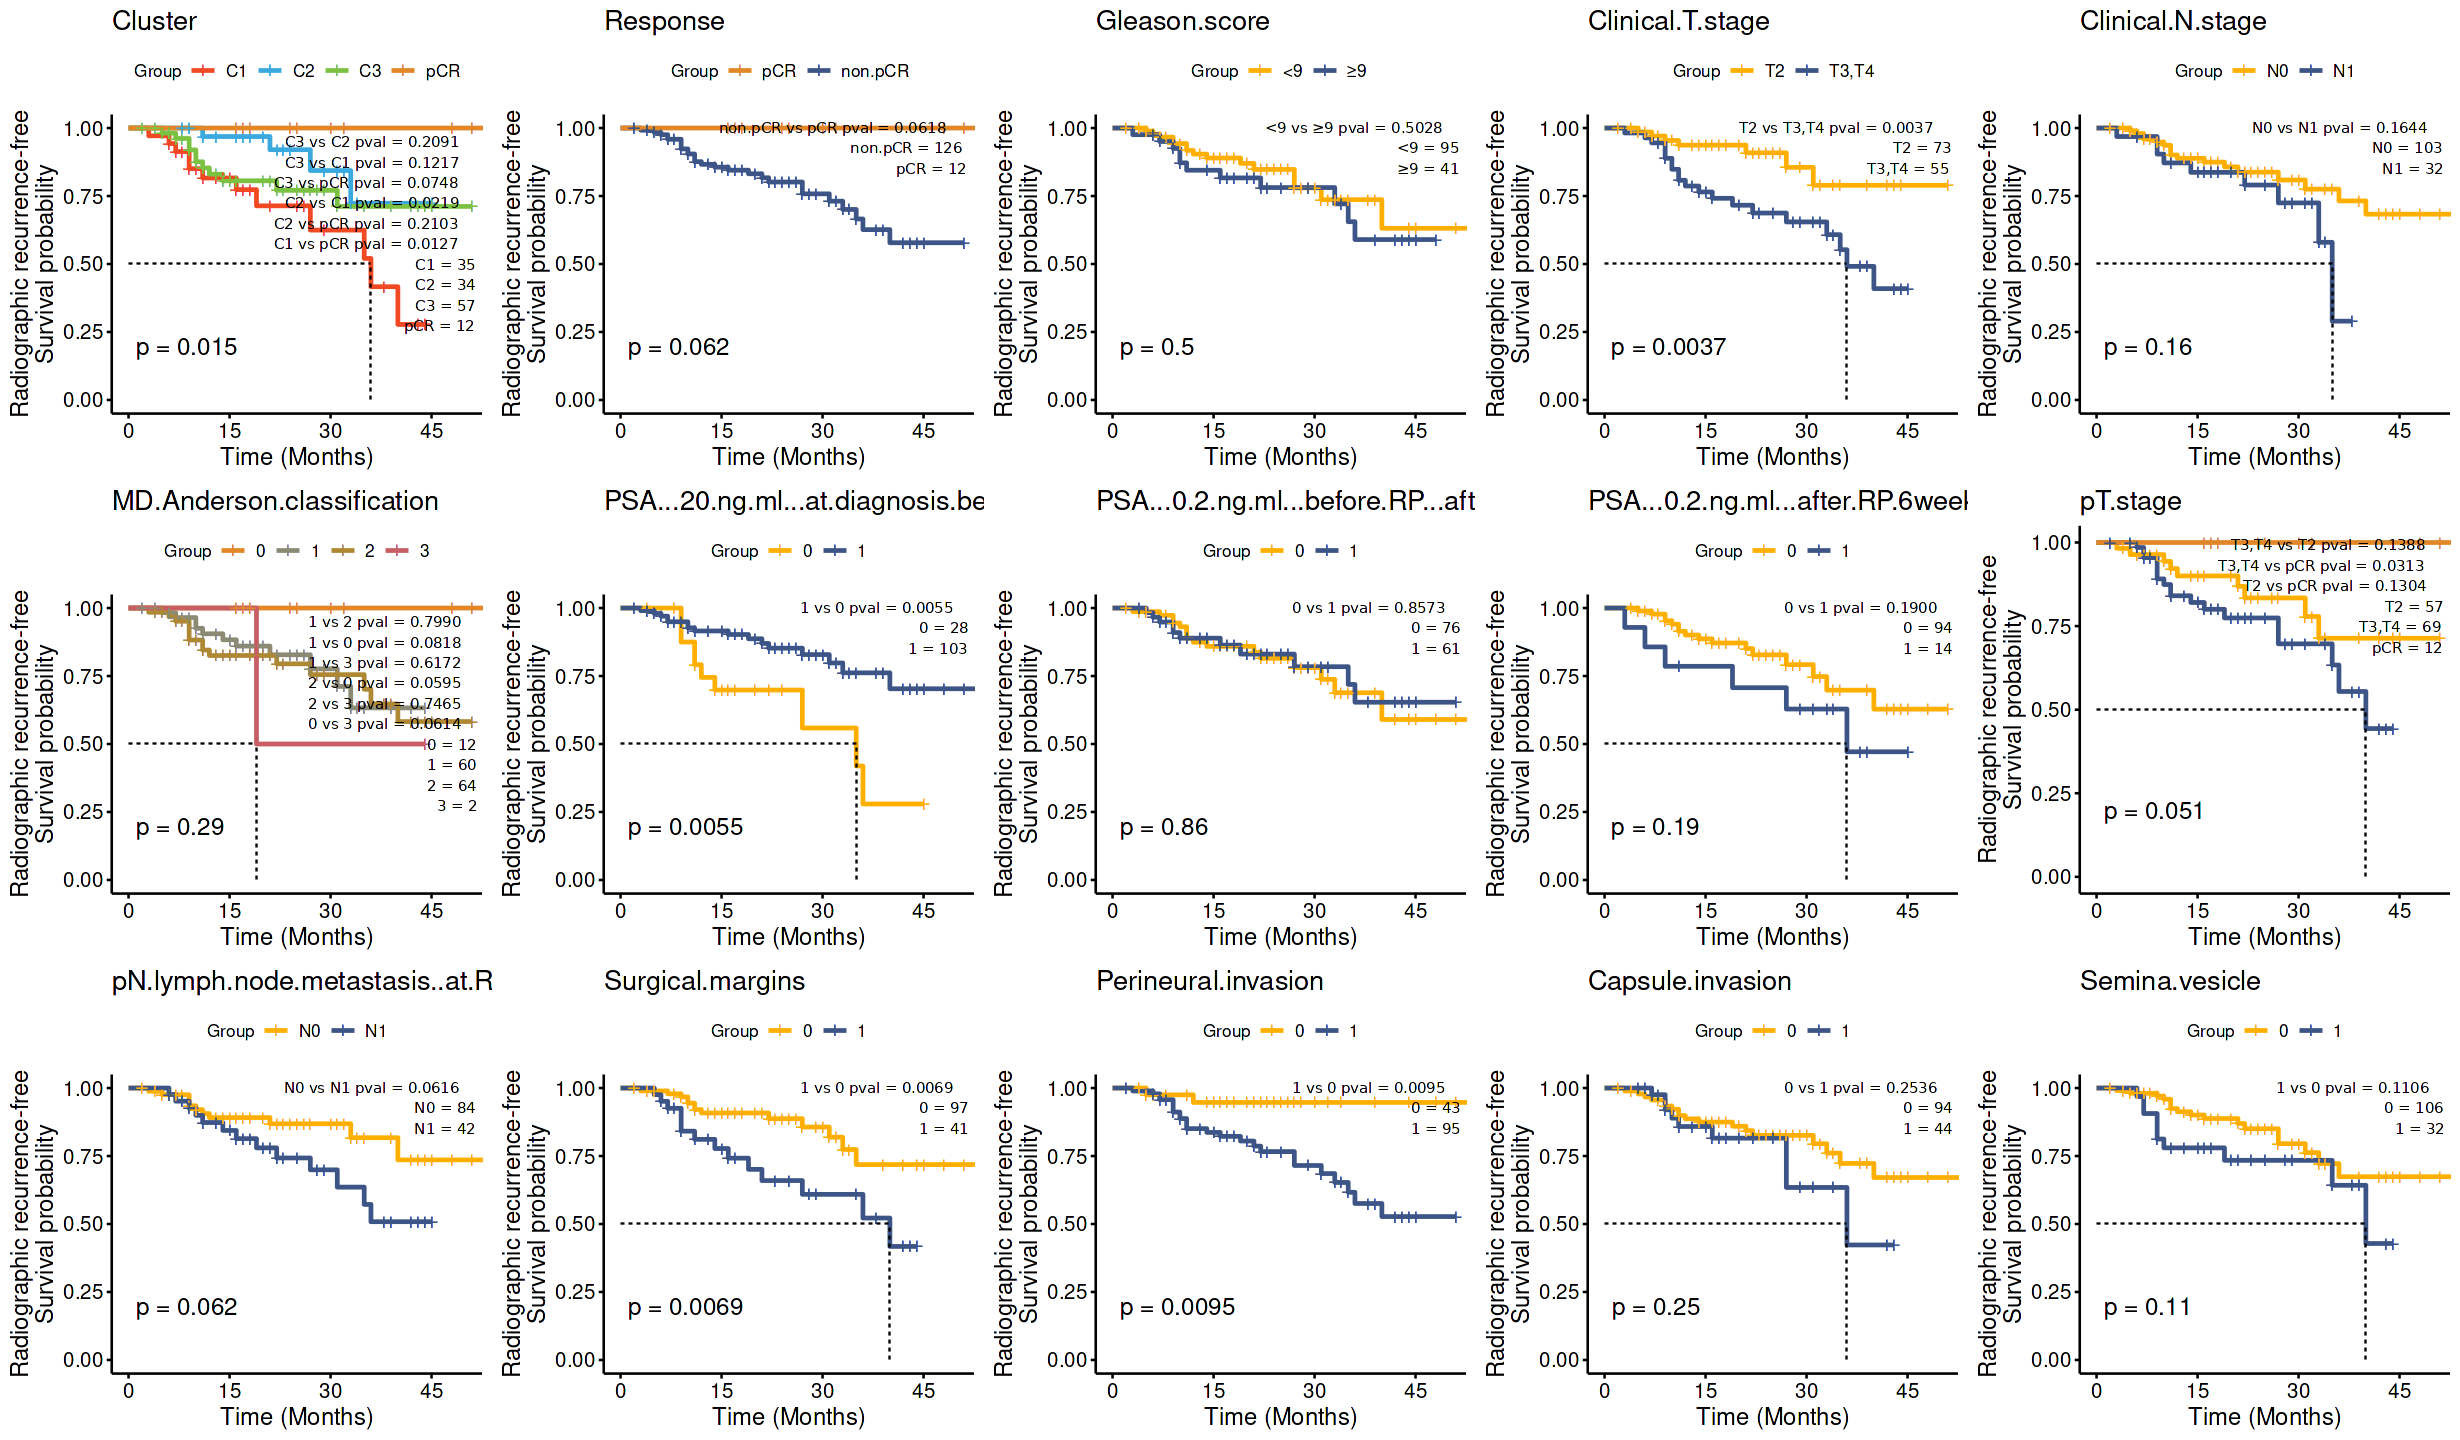

[1] "[ 2026-08-03 08:47:31 ]  write 1 pdf at report_c3/fig.1C.1H.S1E.S1F_train86_RGR.pdf"
[1] "[ 2026-08-03 08:47:31 ]  write 1 xlsx at report_c3/fig.1C.1H.S1E.S1F_train86_RGR.xlsx"


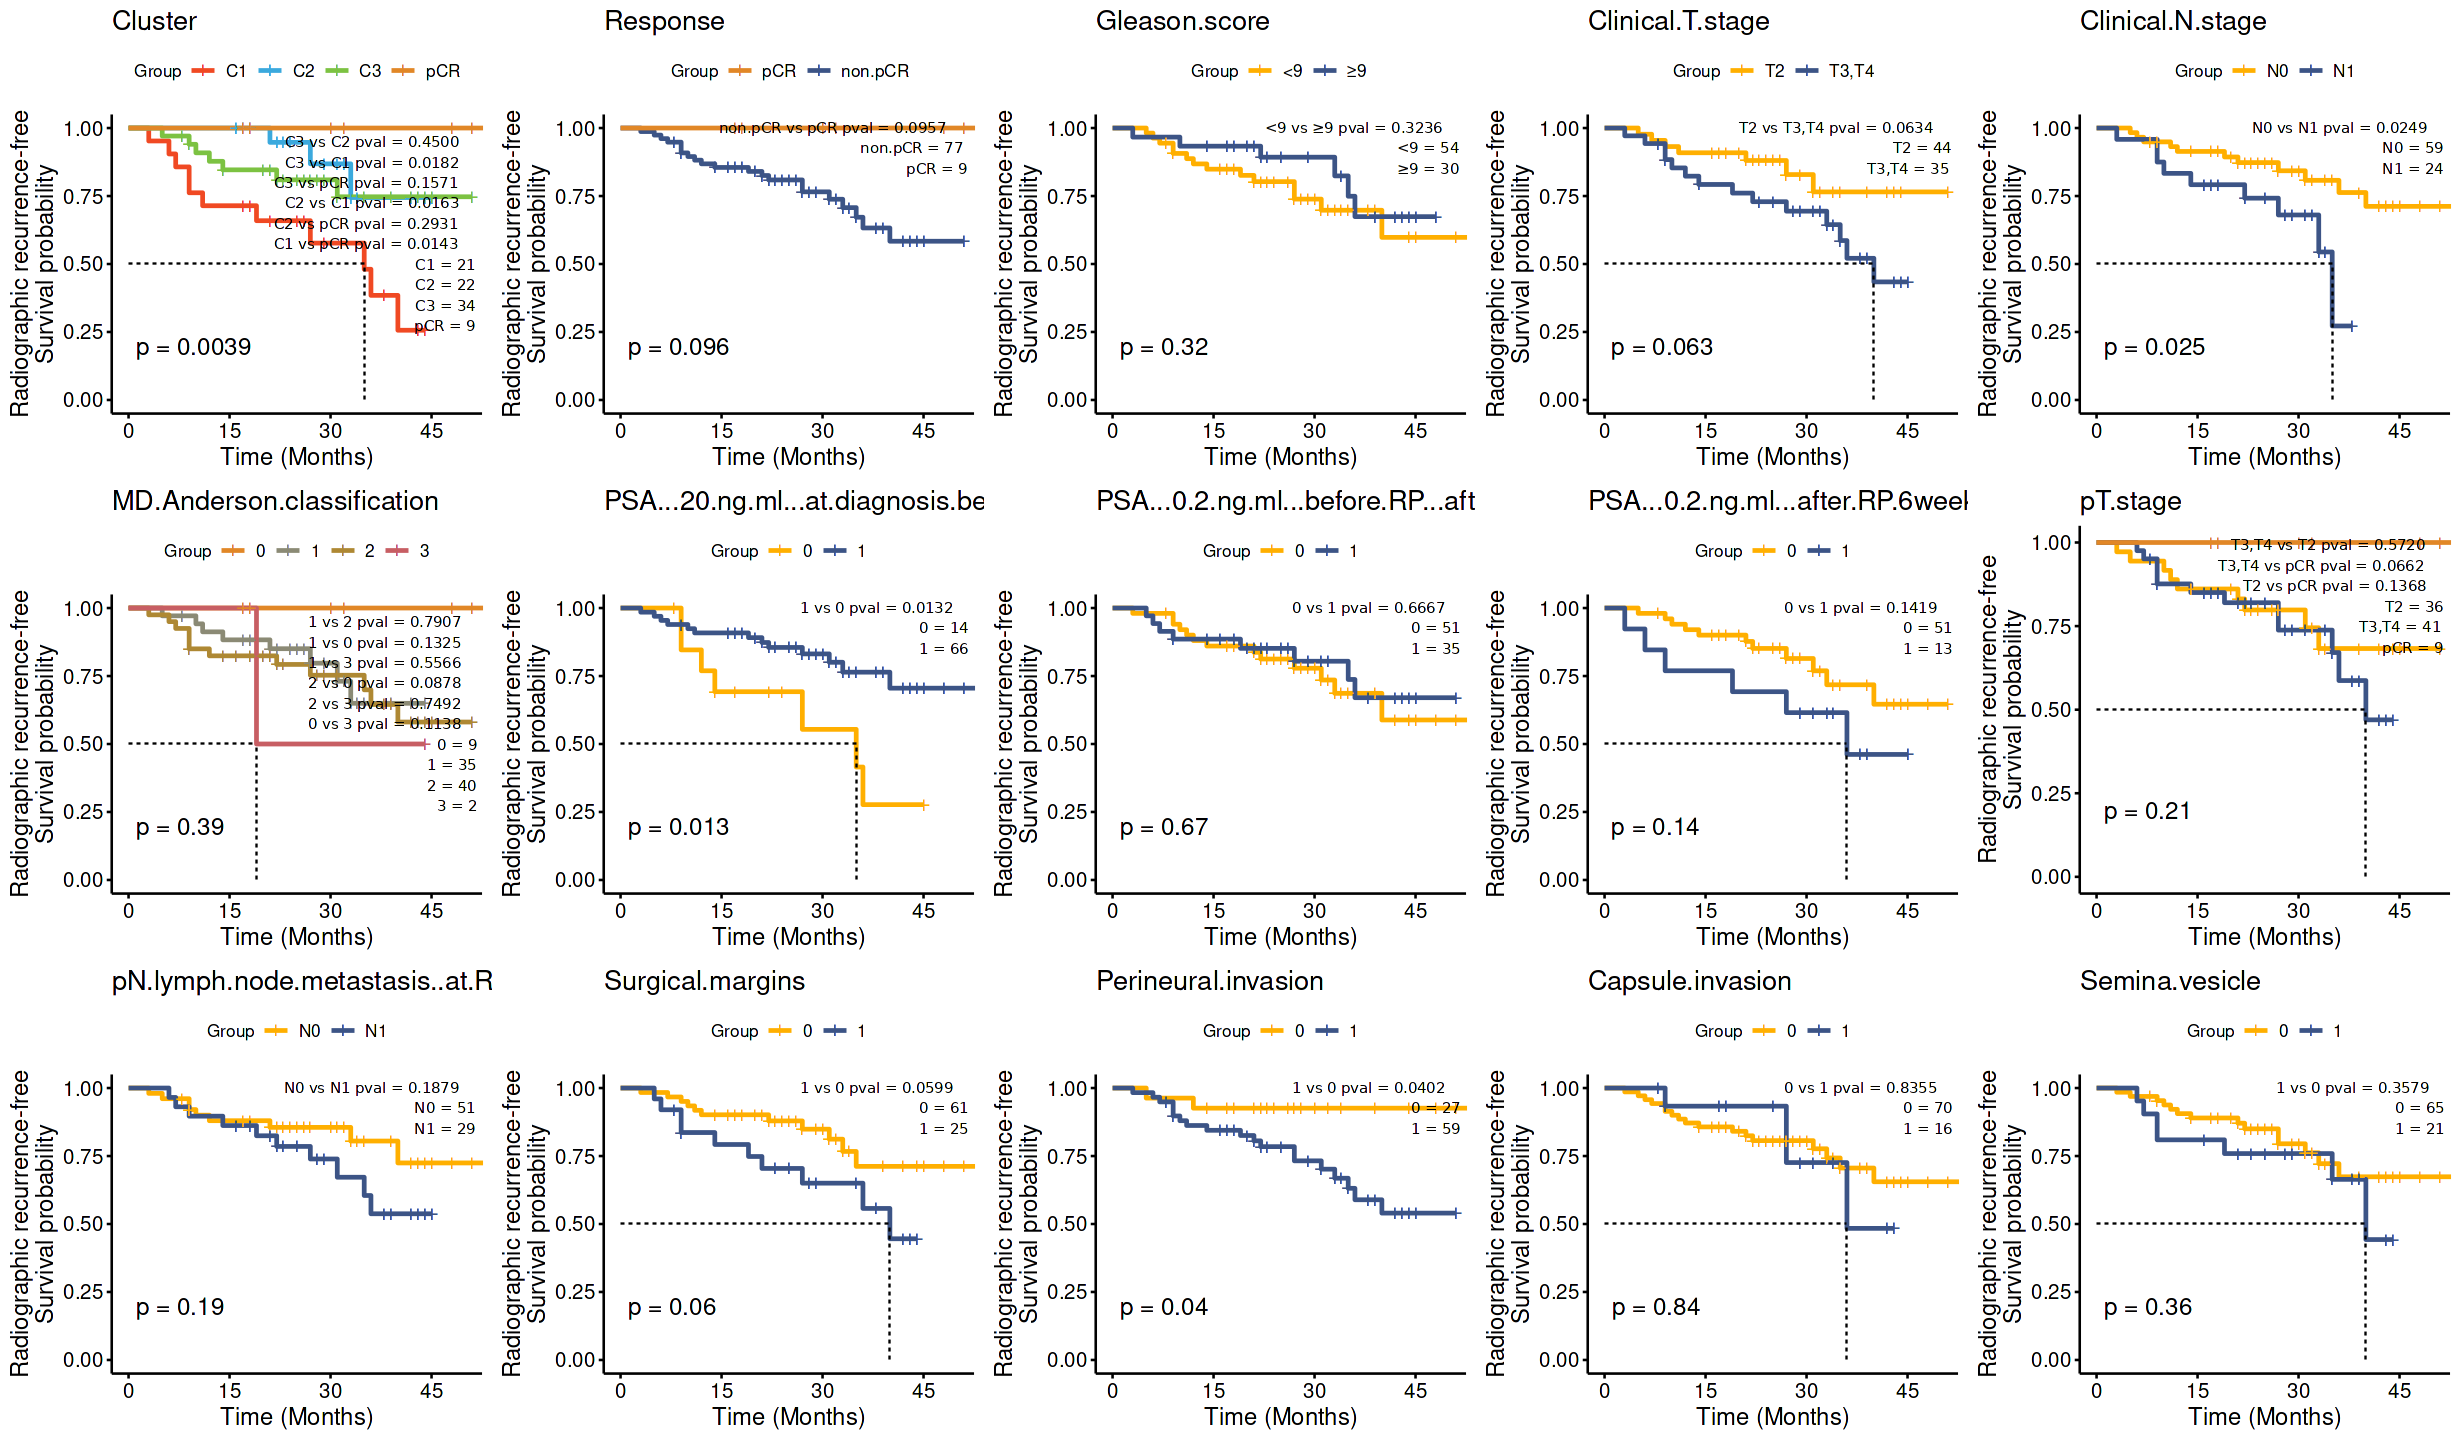

[1] "[ 2026-08-03 08:47:37 ]  write 1 pdf at report_c3/fig.unused_valid52_RGR.pdf"
[1] "[ 2026-08-03 08:47:37 ]  write 1 xlsx at report_c3/fig.unused_valid52_RGR.xlsx"


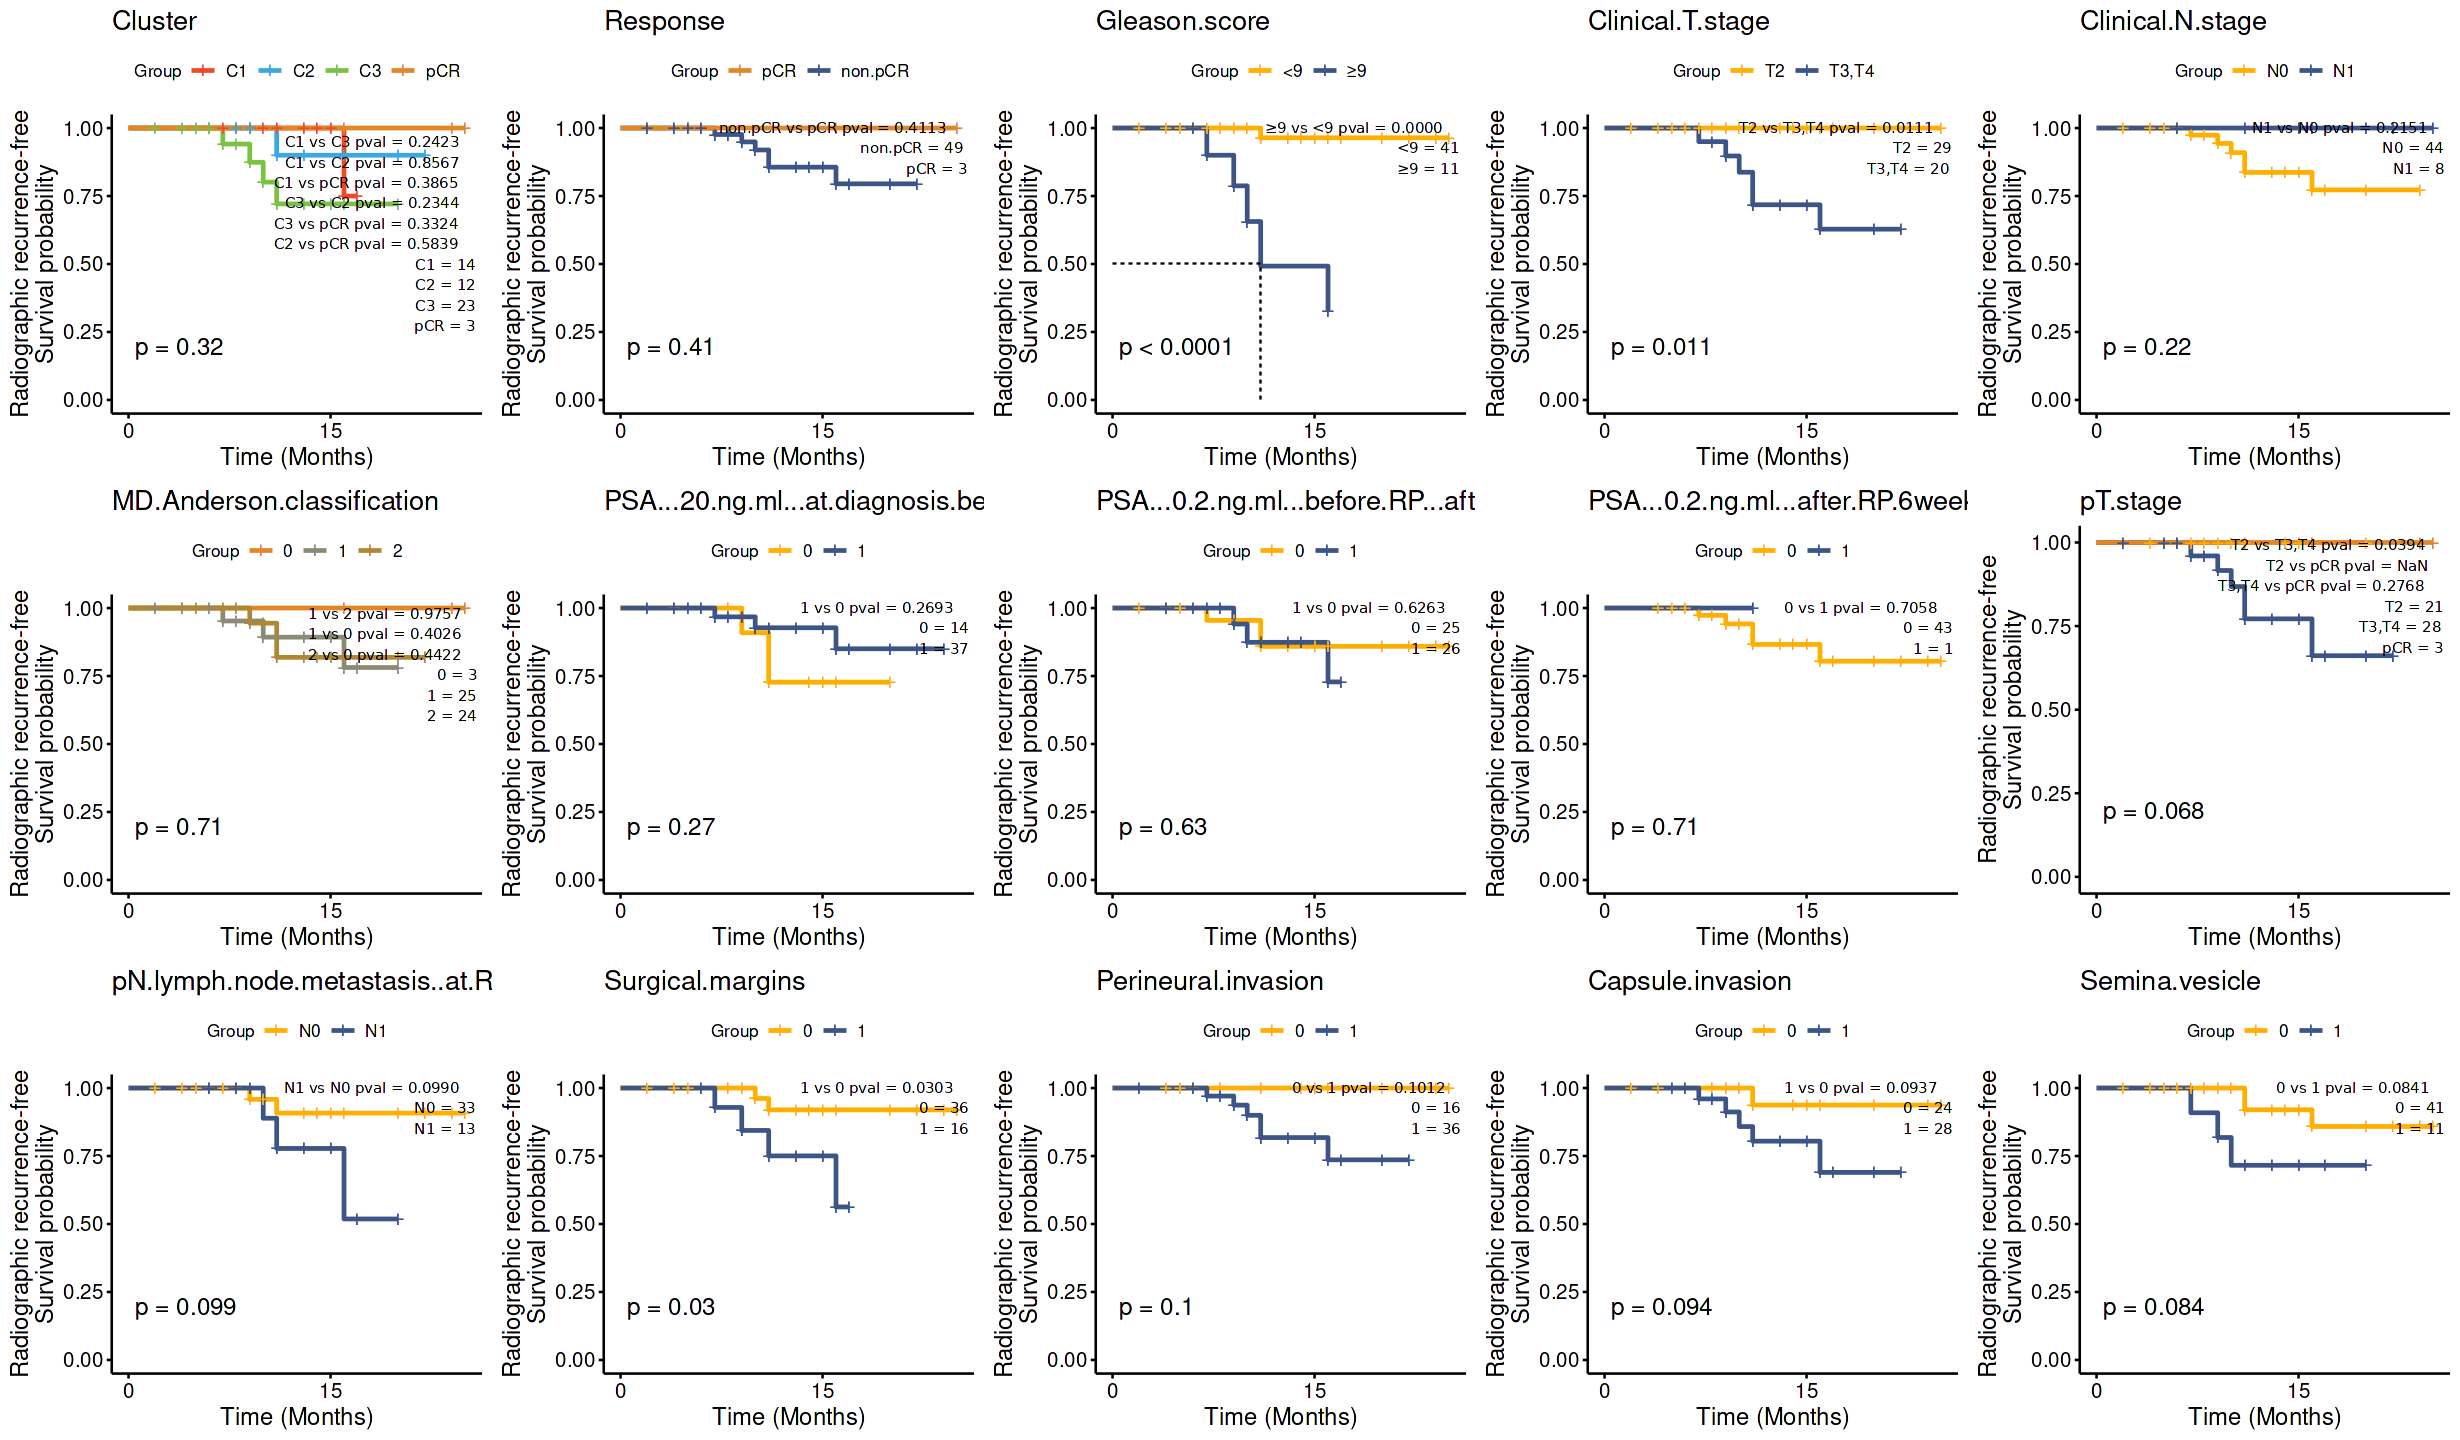

In [137]:
options(warn = -1)
make.custom(4.1*5, 4*3)
for (grp in names(ggs_rgr)){
    # all138 -> article fig S3E; train86 -> article fig 1/S1 panels; valid52 (prospective) has no article figure
    fig_lab = switch(grp, all138='fig.S3E', train86='fig.1C.1H.S1E.S1F', valid52='fig.unused')
    gg = cowplot::plot_grid(plotlist = ggs_rgr[[grp]], ncol=5)
    print(gg)
    gg %>% ysave(fig_lab,grp,'RGR', outputdir = file.path('report_c3'))
    ggs_rgr_data[[grp]] %>% ysave(fig_lab,grp,'RGR', outputdir = file.path('report_c3'))
}
options(warn = 0)

## fig1 D wes oncoplot


In [138]:
mainmat = db.importing('export_c3/fig1_subtype_heatmap_mat.dfx', row.names=1)
mainmat

[1] "[ 2026-08-03 08:47:40 ]  read [ fig1_subtype_heatmap_mat.dfx ] as ' fig1_subtype_heatmap_mat ' from >  export_c3"


,P72,P10,P14,P56,P16,P52,P47,P80,P70,P71,P83,P82,P84,P43,P60,⋯,P50,P04,P02,P01,P21,P48,P77,P35,P81,P74,P75,P64,P78,P76,P79
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
matr_DHRS7,2.808043,5.625099,0.3139248,2.520173,2.765275,1.669549,0.5086191,1.0117378,0.43778949,0.8148225,0.3079813,2.415037075,0.11425572,0.1473456,-0.42714083,⋯,-0.1614700,-0.4825760,-0.2755016,-0.4726331,-0.5473252,-0.5594827,-0.3483549,-0.2614402,-0.5309457,-0.6102692,-0.5719432,-0.3979068,-0.4749569,-0.4627365,-0.6224910
matr_NKX3-1,1.576163,4.530084,3.0604893,3.158740,1.967034,2.301321,0.9997265,0.3934587,0.52757837,0.4762289,0.9362897,-0.005181023,-0.03910264,-0.1965958,0.17718170,⋯,-0.6117748,-0.2898411,-0.3843131,-0.6066182,-0.6149739,-0.8055779,0.3037220,-0.4001885,-0.7022042,-0.8268763,-0.5353842,-0.4836637,-0.6435206,-0.2224900,-0.6772685
matr_SPDEF,4.656854,3.906506,3.8205300,2.628517,1.284360,1.932065,0.3260073,0.2679762,0.05054111,0.3009801,0.1462819,-0.112299143,-0.36401001,0.6248014,-0.02827362,⋯,-0.5521193,-0.3743399,-0.2027096,-0.5043282,-0.6346786,-0.6378150,-0.2958804,-0.4075790,-0.5393940,-0.6738637,-0.6080356,-0.4040810,-0.6850634,-0.4741950,-0.5414757
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
CD56bright natural killer cell,-1.209482,0.9014607,-3.583126,0.3351977,-1.0584020,0.6281721,2.0824689,-0.1166635,0.9316604,0.9757753,-0.6854441,-0.85471729,-1.801770,0.2439016,0.03333639,⋯,1.058728,-1.161423,0.77938230,-0.1492289,-0.3283623,0.1212448,-0.3045483,1.26482848,1.770211,-0.7132153,1.0564331,-0.3100944,-0.9074490,0.7399466,0.0422930
Memory B cell,-2.941354,-2.0750971,-2.160566,-3.4968077,-1.5763006,-1.5656255,1.1238986,1.2195712,0.4215601,0.7981830,1.1127909,-0.24799228,1.334904,-1.7860843,1.35214461,⋯,-1.541135,-0.355066,0.01978501,0.6169853,1.7095293,1.4587559,0.9996863,0.36327526,0.698693,1.2534229,0.6333637,1.2642541,-1.0487429,1.0507168,0.6838983
Eosinophil,-1.869926,0.3610277,-3.698403,-0.3152563,-0.8144997,1.2283429,-0.3250402,-2.0000047,-0.7875983,1.3499254,-1.1388020,-0.01658733,0.754906,0.7063848,0.81704484,⋯,-1.220809,-1.508699,-1.13054979,-0.8025173,-1.0040518,1.5964825,0.5120648,-0.02649549,1.339826,1.2155091,0.8203319,0.9612205,0.3030537,-0.8252242,1.3263246


In [139]:
tsb.order = colnames(mainmat)
gsea.order = rownames(mainmat)
tsb.order

[1] "P72" "P10" "P14" "P56" "P16" "P52" "P47" "P80" "P70" "P71" "P83" "P82"
[13] "P84" "P43" "P60" "P49" "P65" "P51" "P39" "P45" "P66" "P34" "P05" "P29"
[25] "P69" "P53" "P28" "P86" "P85" "P06" "P42" "P18" "P57" "P63" "P17" "P62"
[37] "P41" "P25" "P27" "P46" "P11" "P20" "P30" "P38" "P03" "P37" "P58" "P19"
[49] "P61" "P24" "P23" "P36" "P44" "P32" "P67" "P31" "P68" "P12" "P13" "P73"
[61] "P59" "P54" "P08" "P55" "P22" "P07" "P33" "P09" "P40" "P15" "P26" "P50"
[73] "P04" "P02" "P01" "P21" "P48" "P77" "P35" "P81" "P74" "P75" "P64" "P78"
[85] "P76" "P79"

In [140]:
sel_genes = c("FOXA1","SPOP","KMT2D","KMT2C","TP53","KDM6A","SYNE1","ZMYM3","BRCA2","PTEN",
              "MED12","BRAF","ATM","APC","SMARCA1","TMPRSS2","ERG","RB1","ZNF292","MAP3K7",
              "MST1","PIK3CA","CTNNB1","CDK12","BRCA1","CHD1","IDH1")

In [141]:
row.splt = db.importing('export_c3/fig1_subtype_row_cluster.dfx')$rc
col.splt = db.importing('export_c3/fig1_subtype_column_cluster.dfx')$cc
col.splt

[1] "[ 2026-08-03 08:47:40 ]  read [ fig1_subtype_row_cluster.dfx ] as ' fig1_subtype_row_cluster ' from >  export_c3"
[1] "[ 2026-08-03 08:47:40 ]  read [ fig1_subtype_column_cluster.dfx ] as ' fig1_subtype_column_cluster ' from >  export_c3"


[1] "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1" 
[13] "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C2"  "C2"  "C2" 
[25] "C2"  "C2"  "C2"  "C2"  "C2"  "C2"  "C2"  "C2"  "C2"  "C2"  "C2"  "C2" 
[37] "C2"  "C2"  "C2"  "C2"  "C2"  "C2"  "C2"  "C3"  "C3"  "C3"  "C3"  "C3" 
[49] "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3" 
[61] "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3" 
[73] "C3"  "C3"  "C3"  "C3"  "C3"  "pCR" "pCR" "pCR" "pCR" "pCR" "pCR" "pCR"
[85] "pCR" "pCR"

In [142]:
grp_new = data.frame(Tumor_Sample_Barcode = tsb.order, Clin_classification = col.splt)
grp_new = grp_new %>% filter(Clin_classification !='pCR')
grp_new

Tumor_Sample_Barcode,Clin_classification
<chr>,<chr>
P72,C1
P10,C1
P14,C1
⋮,⋮
P01,C3
P21,C3
P48,C3


In [143]:
wes = db.importing('export_by2_86_pCR_nonpCR/wes_snv_all.dfx') 
wes = wes %>% filter(Clin_classification=='non.pCR')
wes

[1] "[ 2026-08-03 08:47:40 ]  read [ wes_snv_all.dfx ] as ' wes_snv_all ' from >  export_by2_86_pCR_nonpCR"


Hugo_Symbol,NCBI_Build,Chromosome,Start_Position,End_Position,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele2,Tumor_Sample_Barcode,HGVSp_Short,VAF,symbol,a,n,t,p,ap,Custom_Label,Clin_classification
<chr>,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
ANKRD34A,GRCh37,chr1,145474457,145474457,Missense_Mutation,SNP,G,A,P01,p.A377T,8.11,ANKRD34A,K00143,NR22030714,TR22030713,P010143142842401,K00143P010143142842401,P01,non.pCR
PEAR1,GRCh37,chr1,156878538,156878538,Missense_Mutation,SNP,G,T,P01,p.G403W,7.55,PEAR1,K00143,NR22030714,TR22030713,P010143142842401,K00143P010143142842401,P01,non.pCR
DARC,GRCh37,chr1,159175236,159175236,Missense_Mutation,SNP,G,T,P01,p.G5W,5.80,DARC,K00143,NR22030714,TR22030713,P010143142842401,K00143P010143142842401,P01,non.pCR
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
FLNA,GRCh37,chrX,153588575,153588575,Missense_Mutation,SNP,C,A,P86,p.E1196D,6.15,FLNA,K00269,NR22303726,TR22303748,P010269148140701,K00269P010269148140701,P86,non.pCR
POLA1,GRCh37,chrX,24757606,24757606,Missense_Mutation,SNP,C,A,P86,p.Q719K,6.78,POLA1,K00269,NR22303726,TR22303748,P010269148140701,K00269P010269148140701,P86,non.pCR
MXRA5,GRCh37,chrX,3239590,3239590,Missense_Mutation,SNP,G,T,P86,p.T1404N,8.70,MXRA5,K00269,NR22303726,TR22303748,P010269148140701,K00269P010269148140701,P86,non.pCR


In [144]:
cc = db.importing('export_c3/fig1_subtype_column_cluster.dfx') %>% pull(cc)
rc = db.importing('export_c3/fig1_subtype_row_cluster.dfx') %>% pull(rc)

glx_grps = data.frame(tsb=tsb.order, Group = cc) %>% 
    mutate(Response = ifelse(Group=='pCR', 'pCR','non.pCR'))
nonpcr = glx_grps %>% filter(Group!='pCR') %>% pull(tsb)
nonpcr

[1] "[ 2026-08-03 08:47:40 ]  read [ fig1_subtype_column_cluster.dfx ] as ' fig1_subtype_column_cluster ' from >  export_c3"
[1] "[ 2026-08-03 08:47:40 ]  read [ fig1_subtype_row_cluster.dfx ] as ' fig1_subtype_row_cluster ' from >  export_c3"


[1] "P72" "P10" "P14" "P56" "P16" "P52" "P47" "P80" "P70" "P71" "P83" "P82"
[13] "P84" "P43" "P60" "P49" "P65" "P51" "P39" "P45" "P66" "P34" "P05" "P29"
[25] "P69" "P53" "P28" "P86" "P85" "P06" "P42" "P18" "P57" "P63" "P17" "P62"
[37] "P41" "P25" "P27" "P46" "P11" "P20" "P30" "P38" "P03" "P37" "P58" "P19"
[49] "P61" "P24" "P23" "P36" "P44" "P32" "P67" "P31" "P68" "P12" "P13" "P73"
[61] "P59" "P54" "P08" "P55" "P22" "P07" "P33" "P09" "P40" "P15" "P26" "P50"
[73] "P04" "P02" "P01" "P21" "P48"

In [145]:
glx = db.importing('export_by2_86_pCR_nonpCR/wes_glx.dfx') %>% mutate(Tumor_Sample_Barcode= Custom_Label) %>% 
    filter(Tumor_Sample_Barcode %in% nonpcr)
glx

[1] "[ 2026-08-03 08:47:41 ]  read [ wes_glx.dfx ] as ' wes_glx ' from >  export_by2_86_pCR_nonpCR"


Tumor_Sample_Barcode,a,t,p,uid,Custom_Label,ap,PSA,Treat_Res,NEPC,Cribriform,Group,Response,Response2,Clin_classification,RNA_Cluster,Protein_Cluster,Cluster,endocrine_therapy,therapy_month,ARi_type,Thpy_class,PSA_class,tsb,new_tsb
<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<dbl>,<int>,<int>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>
P01,K00143,TR22030713,P010143142842401,1428424,P01,K00143P010143142842401,0.019,1,1,0,C4,non.pCR,I,1,C3,C4,C4,戈舍瑞林+阿比特龙+泼尼松,6,2,>3,≤0.2,P01,P001
P02,K00144,TR22030669,P010144144820001,1448200,P02,K00144P010144144820001,0.024,1,0,0,C2,non.pCR,I,1,C2,C2,C2,戈舍瑞林+比卡鲁胺,3,1,≤3,≤0.2,P02,P002
P03,K00145,TR22030670,P010145141850101,1418501,P03,K00145P010145141850101,0.006,1,0,0,C3,non.pCR,I,1,C3,C3,C3,戈舍瑞林+比卡鲁胺,18,1,>3,≤0.2,P03,P003
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
P84,K00267,TR22303734,P010267145448901,1454489,P84,K00267P010267145448901,0.246,1,0,0,C2,non.pCR,I,1,C2,C2,C2,戈舍瑞林+比卡鲁胺,3,1,≤3,>0.2,P84,P084
P85,K00268,TR22303735,P010268147734101,1477341,P85,K00268P010268147734101,0.711,2,0,0,C2,non.pCR,II,2,C2,C2,C2,地加瑞克,3,1,≤3,>0.2,P85,P085
P86,K00269,TR22303748,P010269148140701,1481407,P86,K00269P010269148140701,0.051,1,0,0,C2,non.pCR,I,1,C4,C2,C2,戈舍瑞林+比卡鲁胺,4,1,>3,≤0.2,P86,P086


In [146]:
glx$Tumor_Sample_Barcode = glx$Custom_Label
df_wes = wes %>% filter(Hugo_Symbol %in% !!sel_genes)
df_wes = df_wes %>% complete(Tumor_Sample_Barcode = grp_new$Tumor_Sample_Barcode, fill = list(Hugo_Symbol='.'))
df_wes

Tumor_Sample_Barcode,Hugo_Symbol,NCBI_Build,Chromosome,Start_Position,End_Position,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele2,HGVSp_Short,VAF,symbol,a,n,t,p,ap,Custom_Label,Clin_classification
<chr>,<chr>,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
P01,.,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
P02,.,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
P03,.,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
P84,SPOP,GRCh37,chr17,47696450,47696450,Missense_Mutation,SNP,A,C,p.F125V,5.33,SPOP,K00267,NR22303717,TR22303734,P010267145448901,K00267P010267145448901,P84,non.pCR
P85,.,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
P86,FOXA1,GRCh37,chr14,38061240,38061240,Missense_Mutation,SNP,G,A,p.S250F,22.71,FOXA1,K00269,NR22303726,TR22303748,P010269148140701,K00269P010269148140701,P86,non.pCR


In [147]:
maf = maftools::read.maf(maf = df_wes, clinicalData = grp_new)
maf

-Validating
--Non MAF specific values in Variant_Classification column:
  NA
--Non MAF specific values in Variant_Type column:
  NA
-Silent variants: 36 
-Summarizing
--Possible FLAGS among top ten genes:
  SYNE1
-Processing clinical data
-Finished in 0.084s elapsed (0.738s cpu) 


An object of class  MAF 
                   ID summary  Mean Median
               <char>  <char> <num>  <num>
 1:        NCBI_Build  GRCh37    NA     NA
 2:            Center    <NA>    NA     NA
 3:           Samples      77    NA     NA
 4:            nGenes      21    NA     NA
 5:   Frame_Shift_Del       4 0.052      0
 6:      In_Frame_Del       1 0.013      0
 7: Missense_Mutation      51 0.662      0
 8: Nonsense_Mutation      12 0.156      0
 9:       Splice_Site       5 0.065      0
10:             total      73 0.948      1

In [148]:
# %%R
# select group columns
COLS = c('Clin_classification')

# load all wes data


# set colors
CNV_LEGEND = structure(c("Amplification","Gain","Loss","Deletion")
          ,names=c("Frame_Shift_Ins","In_Frame_Ins","In_Frame_Del","Frame_Shift_Del"))
ygen_set_color_scheme()
# ygen_anno_color(grp_new,cols=COLS)
COL_ONCOPLOT_ANNO = list(Clin_classification=c(C1='#F04923',C2='#3BA9DD',C3='#7CC242',pCR='#E18727'))

[1] "global var COL_SNV, COL_CNV, COL_TITV have been set."


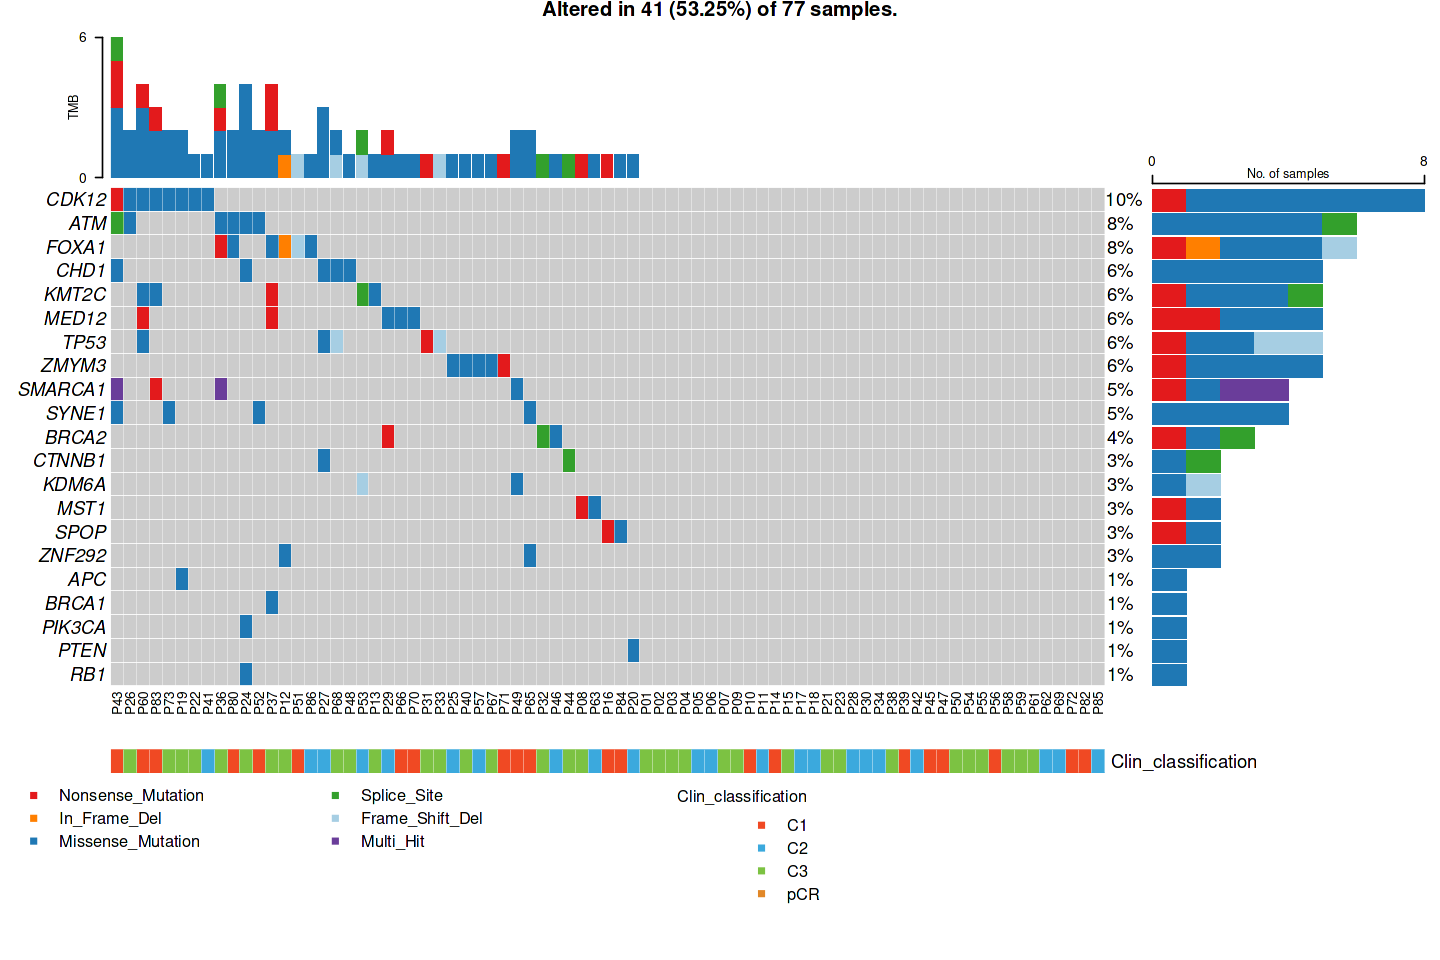

In [149]:
make.wide()
plt.onco = expr(
    maftools::oncoplot(maf
            ,genes = sel_genes
            # ,top = 40
            ,fontSize = 0.9
            ,gene_mar = 7
            ,colors=COL_SNV
            ,clinicalFeatures = COLS
            ,annotationColor = COL_ONCOPLOT_ANNO
            ,sortByAnnotation=FALSE
            ,fill=FALSE
            ,showTumorSampleBarcodes = TRUE
            # ,annotationOrder = c("0","1","2","3")
            ,annoBorderCol='white'
            ,anno_height=0.5
            ,legend_height= 4
            ,legendFontSize=1.2
            ,removeNonMutated = FALSE
            # ,lengend_txt_replace = CNV_LEGEND
            )
    )
eval(plt.onco)

In [150]:
plt.onco %>% ysave('fig.1D','SNA','oncoplot','77_cases',outputdir = OUTPUTROOT)
df_wes %>% ysave('fig.1D','SNA','oncoplot','77_cases',outputdir = OUTPUTROOT)

[1] "[ 2026-08-03 08:47:41 ]  write 1 pdf at report_c3/fig.1D_SNA_oncoplot_77_cases.pdf"
[1] "[ 2026-08-03 08:47:41 ]  write 1 xlsx at report_c3/fig.1D_SNA_oncoplot_77_cases.xlsx"


## fig 1E ComplexHeatmap

In [151]:
mainmat = db.importing('export_c3/fig1_subtype_heatmap_mat.dfx', row.names=1)
mainmat

[1] "[ 2026-08-03 08:47:41 ]  read [ fig1_subtype_heatmap_mat.dfx ] as ' fig1_subtype_heatmap_mat ' from >  export_c3"


,P72,P10,P14,P56,P16,P52,P47,P80,P70,P71,P83,P82,P84,P43,P60,⋯,P50,P04,P02,P01,P21,P48,P77,P35,P81,P74,P75,P64,P78,P76,P79
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
matr_DHRS7,2.808043,5.625099,0.3139248,2.520173,2.765275,1.669549,0.5086191,1.0117378,0.43778949,0.8148225,0.3079813,2.415037075,0.11425572,0.1473456,-0.42714083,⋯,-0.1614700,-0.4825760,-0.2755016,-0.4726331,-0.5473252,-0.5594827,-0.3483549,-0.2614402,-0.5309457,-0.6102692,-0.5719432,-0.3979068,-0.4749569,-0.4627365,-0.6224910
matr_NKX3-1,1.576163,4.530084,3.0604893,3.158740,1.967034,2.301321,0.9997265,0.3934587,0.52757837,0.4762289,0.9362897,-0.005181023,-0.03910264,-0.1965958,0.17718170,⋯,-0.6117748,-0.2898411,-0.3843131,-0.6066182,-0.6149739,-0.8055779,0.3037220,-0.4001885,-0.7022042,-0.8268763,-0.5353842,-0.4836637,-0.6435206,-0.2224900,-0.6772685
matr_SPDEF,4.656854,3.906506,3.8205300,2.628517,1.284360,1.932065,0.3260073,0.2679762,0.05054111,0.3009801,0.1462819,-0.112299143,-0.36401001,0.6248014,-0.02827362,⋯,-0.5521193,-0.3743399,-0.2027096,-0.5043282,-0.6346786,-0.6378150,-0.2958804,-0.4075790,-0.5393940,-0.6738637,-0.6080356,-0.4040810,-0.6850634,-0.4741950,-0.5414757
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
CD56bright natural killer cell,-1.209482,0.9014607,-3.583126,0.3351977,-1.0584020,0.6281721,2.0824689,-0.1166635,0.9316604,0.9757753,-0.6854441,-0.85471729,-1.801770,0.2439016,0.03333639,⋯,1.058728,-1.161423,0.77938230,-0.1492289,-0.3283623,0.1212448,-0.3045483,1.26482848,1.770211,-0.7132153,1.0564331,-0.3100944,-0.9074490,0.7399466,0.0422930
Memory B cell,-2.941354,-2.0750971,-2.160566,-3.4968077,-1.5763006,-1.5656255,1.1238986,1.2195712,0.4215601,0.7981830,1.1127909,-0.24799228,1.334904,-1.7860843,1.35214461,⋯,-1.541135,-0.355066,0.01978501,0.6169853,1.7095293,1.4587559,0.9996863,0.36327526,0.698693,1.2534229,0.6333637,1.2642541,-1.0487429,1.0507168,0.6838983
Eosinophil,-1.869926,0.3610277,-3.698403,-0.3152563,-0.8144997,1.2283429,-0.3250402,-2.0000047,-0.7875983,1.3499254,-1.1388020,-0.01658733,0.754906,0.7063848,0.81704484,⋯,-1.220809,-1.508699,-1.13054979,-0.8025173,-1.0040518,1.5964825,0.5120648,-0.02649549,1.339826,1.2155091,0.8203319,0.9612205,0.3030537,-0.8252242,1.3263246


In [152]:
rn = mainmat %>% rownames()
prtgenes = mainmat[rn %>%  str_starts('matp'),]
prtgenes

,P72,P10,P14,P56,P16,P52,P47,P80,P70,P71,P83,P82,P84,P43,P60,⋯,P50,P04,P02,P01,P21,P48,P77,P35,P81,P74,P75,P64,P78,P76,P79
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
matp_NKX3-1,0.4978827,3.041265,2.4141671,3.081645,0.2089846,1.028086,0.00789202,1.0397680,0.1492449,0.8608203,-0.8842984,1.2710063,0.02819734,1.5674345,0.9413565,⋯,-0.06321844,0.4131249,0.09182286,-0.03223376,-0.8992922,-0.1737407,0.07491506,-0.3607995,-0.02144459,0.08850384,-0.03163678,-1.3484609,-1.7102206,0.1756802,0.246019
matp_REEP6,-0.4502282,1.627995,0.8697264,1.923616,0.1921810,1.412764,2.78926473,1.1288843,1.6396285,0.4607937,0.9345393,-0.5002784,0.97587627,0.7842831,-1.0382623,⋯,-0.63428688,-0.3220882,-0.67950636,-0.21460567,-0.6427237,-1.3678320,-1.14875979,-0.7664175,-0.68958696,-0.72680350,-0.10905024,-0.1660879,-0.2362595,-0.1862717,-1.754646
matp_PGM3,2.3602765,1.922458,0.3138042,2.560760,2.1640650,3.704552,0.38174085,0.8504095,1.0802433,0.4840246,0.5670476,0.6014493,-0.72715735,1.9382063,-0.7196579,⋯,-0.30013048,-0.3951019,-0.60675025,-0.57969981,-0.9443567,-1.2281011,-0.50810759,-0.1883123,-0.87105538,-1.14885737,-0.45892212,-0.5695800,-0.2176369,-0.2607835,-1.400571
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
matp_PGM1,-2.343512,-2.7017562,-1.8569353,-0.2177773,-2.3761492,0.3755760,-0.83511597,-1.261559,1.5496364,-0.3443753,0.4828056,0.17414995,0.22400707,-1.4480863,-1.8006713,⋯,0.74029631,0.58358504,0.4260577,-0.8969540,1.61270526,0.03803145,0.5066522,1.0106528,0.1300850,-0.6661187,-0.8310180,-0.6274240,2.9041655,2.0564708,-0.1949427
matp_BST2,1.951204,-2.1763827,-0.9969405,-1.7367180,-1.0301525,-1.1349235,-0.15951822,0.229749,-1.0127297,-0.2015667,0.0428639,1.00909283,0.59031827,-0.5928785,-0.7539759,⋯,-0.25366634,-0.09924344,1.2046083,1.0259774,0.08364204,1.72225007,-1.3005381,-0.1331035,-0.4595004,1.4914547,2.6602286,-0.7962451,0.2280944,0.8365766,-1.0201245
matp_CD8A,-1.375157,0.5926533,-2.8342659,-0.4701790,-0.3422091,-0.5851882,-0.08631245,-0.397438,-0.1170842,-0.1957218,1.4403291,0.01976149,0.05389816,-0.7121415,-0.8340870,⋯,-0.08700821,0.97560817,-0.1098788,0.3312158,-0.13631724,1.44716590,1.0643811,0.3834587,-0.3509900,0.1400647,-0.1292312,-0.1093884,-0.6771665,-0.4667929,-0.7168903


In [153]:
tsb.order = colnames(mainmat)
gsea.order = rownames(mainmat)
tsb.order

[1] "P72" "P10" "P14" "P56" "P16" "P52" "P47" "P80" "P70" "P71" "P83" "P82"
[13] "P84" "P43" "P60" "P49" "P65" "P51" "P39" "P45" "P66" "P34" "P05" "P29"
[25] "P69" "P53" "P28" "P86" "P85" "P06" "P42" "P18" "P57" "P63" "P17" "P62"
[37] "P41" "P25" "P27" "P46" "P11" "P20" "P30" "P38" "P03" "P37" "P58" "P19"
[49] "P61" "P24" "P23" "P36" "P44" "P32" "P67" "P31" "P68" "P12" "P13" "P73"
[61] "P59" "P54" "P08" "P55" "P22" "P07" "P33" "P09" "P40" "P15" "P26" "P50"
[73] "P04" "P02" "P01" "P21" "P48" "P77" "P35" "P81" "P74" "P75" "P64" "P78"
[85] "P76" "P79"

In [154]:
# generated from GET_DATA_86_7.ipynb / Collect fig1 snv,cnv,fusion data 
mut = db.importing('export_big/fig1_wes_rna_molecular_table.dfx') %>% column_to_rownames('V1')
mut = mut[,tsb.order] %>% t %>% as.data.frame()
mut

[1] "[ 2026-08-03 08:47:41 ]  read [ fig1_wes_rna_molecular_table.dfx ] as ' fig1_wes_rna_molecular_table ' from >  export_big"


,TP53_mut,CDK12_mut,KMT2C_mut,KMT2D_mut,CSMD3_mut,FOXA1_mut,BRCA1_mut,BRCA2_mut,ATM_mut,BRCA1_germline,BRCA2_germline,ATM_germline,TMPRSS2--ERG_fusion,MYC_gain,EGFR_gain,RB1_loss,ZNF292_loss,MAP3K7_loss,CHD1_loss,PTEN_loss
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
P72,F,F,F,F,F,F,F,F,F,F,F,T,F,T,F,F,F,T,F,F
P10,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F
P14,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,T,F,F,F,F
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
P78,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F
P76,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F
P79,F,F,F,T,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F


In [155]:
rn = rownames(mainmat)
mask = rn %>% str_starts('HALL')
torep = rn[mask] %>% str_sub(10) %>%str_replace_all(fixed('_')," ") %>% str_to_title() %>% str_replace_all(fixed('Cd'),"CD")
rn[mask] = torep

mask = rn %>% str_starts("matp_")
torep = rn[mask] %>% str_replace('matp','Prt')
rn[mask] = torep

mask = rn %>% str_starts("matr_")
torep = rn[mask] %>% str_replace('matr','RNA')
rn[mask] = torep

map_ssgsea_term_name = structure(rn,names=rn)
torep = c('Pi3k Akt Mtor Signaling' = 'PI3K AKT mTOR Signaling',
'Tnfa Signaling Via Nfkb' = 'TNFα Signaling Via NFκB',
'Il6 Jak Stat3 Signaling' = 'IL6 JAK STAT3 Signaling',
'Interferon Alpha Response' = 'IFNα Response',
'Wnt Beta Catenin Signaling' = 'WNT β-catenin Signaling',
'Notch Signaling' = 'NOTCH Signaling',
'Kras Signaling Dn' = 'KRAS Signaling DN',
'Kras Signaling Up' = 'KRAS Signaling Up',
'Il2 Stat5 Signaling' = 'IL2 STAT5 Signaling',
'Uv Response Dn' = 'UV Response DN',
'Tgf Beta Signaling' = 'TGFβ Signaling',
'Mtorc1 Signaling' = 'mTORC1 Signaling',
'Uv Response Up' = 'UV Response Up',
'Myc Targets V2' = 'MYC Targets V2',
'Myc Targets V1' = 'MYC Targets V1',
'G2m Checkpoint' = 'G2M Checkpoint',
'E2f Targets' = 'E2F Targets',
'Dna Repair' = 'DNA Repair')
for (i in names(torep)){
    if (!i %in% names(map_ssgsea_term_name) ) stop(i)
}
for (i in names(torep)){
    map_ssgsea_term_name[i] = torep[i]
}
stopifnot(length(map_ssgsea_term_name) == nrow(mainmat))

names(map_ssgsea_term_name) = NULL
rownames(mainmat) = map_ssgsea_term_name

In [156]:
row.splt = db.importing('export_c3/fig1_subtype_row_cluster.dfx')$rc
col.splt = db.importing('export_c3/fig1_subtype_column_cluster.dfx')$cc
col.splt

[1] "[ 2026-08-03 08:47:41 ]  read [ fig1_subtype_row_cluster.dfx ] as ' fig1_subtype_row_cluster ' from >  export_c3"
[1] "[ 2026-08-03 08:47:41 ]  read [ fig1_subtype_column_cluster.dfx ] as ' fig1_subtype_column_cluster ' from >  export_c3"


[1] "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1" 
[13] "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C2"  "C2"  "C2" 
[25] "C2"  "C2"  "C2"  "C2"  "C2"  "C2"  "C2"  "C2"  "C2"  "C2"  "C2"  "C2" 
[37] "C2"  "C2"  "C2"  "C2"  "C2"  "C2"  "C2"  "C3"  "C3"  "C3"  "C3"  "C3" 
[49] "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3" 
[61] "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3" 
[73] "C3"  "C3"  "C3"  "C3"  "C3"  "pCR" "pCR" "pCR" "pCR" "pCR" "pCR" "pCR"
[85] "pCR" "pCR"

In [157]:
grp_new = data.frame(Tumor_Sample_Barcode = tsb.order, Clin_classification = col.splt)
grp_new

Tumor_Sample_Barcode,Clin_classification
<chr>,<chr>
P72,C1
P10,C1
P14,C1
⋮,⋮
P78,pCR
P76,pCR
P79,pCR


In [158]:
stopifnot(all(rownames(mut) == colnames(mainmat)))

In [159]:
colData = data.frame(Protein_Cluster = structure(col.splt , names = colnames(mainmat))) 

for (i in colnames(mut)){
    colData[[i]] = mut %>% pull(!!i)
    COL_ANNO[[i]] = c(F='#91D1F3',T='#317CC0')
}
# colData = colData %>% t %>% as.data.frame()
colData

,Protein_Cluster,TP53_mut,CDK12_mut,KMT2C_mut,KMT2D_mut,CSMD3_mut,FOXA1_mut,BRCA1_mut,BRCA2_mut,ATM_mut,BRCA1_germline,BRCA2_germline,ATM_germline,TMPRSS2--ERG_fusion,MYC_gain,EGFR_gain,RB1_loss,ZNF292_loss,MAP3K7_loss,CHD1_loss,PTEN_loss
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
P72,C1,F,F,F,F,F,F,F,F,F,F,F,T,F,T,F,F,F,T,F,F
P10,C1,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F
P14,C1,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,T,F,F,F,F
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
P78,pCR,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F
P76,pCR,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F
P79,pCR,F,F,F,T,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F


In [160]:
sel = (mainmat %>% rownames)[mainmat %>% rownames %>% str_starts('RNA_') | mainmat %>% rownames %>%  str_starts('Prt_')]
length(sel)

[1] 143

In [161]:
rna = sel[sel %>% str_starts('RNA_')] %>% str_sub(5)
prt = sel[sel %>% str_starts('Prt_')] %>% str_sub(5)
rna %>% intersect(prt)

[1] "NKX3-1" "PRDX4"

In [162]:
make.custom(12,4)

ANNO_LABEL_FONTSIZE = 6
ANNO_NAME_FONTSIZE = 6
LEGEND_TITLE_FONTSIZE = 6

ha.top = HeatmapAnnotation(
#         PSA = anno_barplot(colData$PSA,ylim = c(0,15), height = unit(10,'mm'))
        df = colData
#         ,annotation_height = unit(8.5,'cm')
#         ,height = unit(9.5, "cm")
        ,simple_anno_size = unit(2,'mm')
        ,border = FALSE
        ,gp = gpar(col = "white",lwd=0.5)
        ,col = COL_ANNO
        # ,gp = gpar(fontsize=3)
        ,annotation_name_gp= gpar(fontsize = ANNO_NAME_FONTSIZE)
        # ,labels_gp = gpar(fontsize=4)
        ,annotation_legend_param = list(
#             nrow=NROW
            labels_gp = gpar(fontsize=ANNO_LABEL_FONTSIZE)
            , title_gp = gpar(fontsize=LEGEND_TITLE_FONTSIZE)
            )
)

# ha.bottom = HeatmapAnnotation(
#     `Treatment` = anno_lollipop
# #     ,height = unit(2, "cm")
#     ,annotation_name_gp = gpar(fontsize = ANNO_NAME_FONTSIZE)
#     ,annotation_legend_param = list(labels_gp = gpar(fontsize=ANNO_LABEL_FONTSIZE)
#                                     , title_gp = gpar(fontsize=LEGEND_TITLE_FONTSIZE)
#                                    )
# )

lgd.bottom = Legend(title='Treatment', at= names(COL_POINTS)
                  , legend_gp = gpar(fill=COL_POINTS)
                  , labels_gp = gpar(fontsize=ANNO_LABEL_FONTSIZE)
                  , title_gp = gpar(fontsize=LEGEND_TITLE_FONTSIZE)
                 )

In [163]:
mask = row.splt == 'gene'
mat1 = mainmat[mask,]
row.split1 = row.splt[mask]

mat2 =  mainmat[!mask,]
row.split2 = row.splt[!mask]


In [164]:
mat0 = colData %>% t %>% as.data.frame
mat0

,P72,P10,P14,P56,P16,P52,P47,P80,P70,P71,P83,P82,P84,P43,P60,⋯,P50,P04,P02,P01,P21,P48,P77,P35,P81,P74,P75,P64,P78,P76,P79
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
Protein_Cluster,C1,C1,C1,C1,C1,C1,C1,C1,C1,C1,C1,C1,C1,C1,C1,⋯,C3,C3,C3,C3,C3,C3,pCR,pCR,pCR,pCR,pCR,pCR,pCR,pCR,pCR
TP53_mut,F,F,F,F,F,F,F,F,F,F,F,F,F,F,T,⋯,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F
CDK12_mut,F,F,F,F,F,F,F,F,F,F,T,F,F,T,T,⋯,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
MAP3K7_loss,T,F,F,F,F,T,F,F,T,F,F,F,F,F,F,⋯,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F
CHD1_loss,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F,⋯,F,F,F,T,F,F,F,F,F,F,F,F,F,F,F
PTEN_loss,F,F,F,F,F,T,F,F,T,F,F,F,F,F,F,⋯,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F


In [165]:
stopifnot(all(colnames(mat0) == colnames(mat1)))
stopifnot(all(colnames(mat1) == colnames(mat2)))


In [166]:
mat_all = rbind(mat0, mat1)
mat_all = rbind(mat_all, mat2)
mat_all

,P72,P10,P14,P56,P16,P52,P47,P80,P70,P71,P83,P82,P84,P43,P60,⋯,P50,P04,P02,P01,P21,P48,P77,P35,P81,P74,P75,P64,P78,P76,P79
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
Protein_Cluster,C1,C1,C1,C1,C1,C1,C1,C1,C1,C1,C1,C1,C1,C1,C1,⋯,C3,C3,C3,C3,C3,C3,pCR,pCR,pCR,pCR,pCR,pCR,pCR,pCR,pCR
TP53_mut,F,F,F,F,F,F,F,F,F,F,F,F,F,F,T,⋯,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F
CDK12_mut,F,F,F,F,F,F,F,F,F,F,T,F,F,T,T,⋯,F,F,F,F,F,F,F,F,F,F,F,F,F,F,F
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
CD56bright natural killer cell,-1.20948157600502,0.901460713840494,-3.58312649402706,0.335197687939785,-1.0584020157013,0.628172081008779,2.08246887460064,-0.116663487709648,0.93166036912618,0.975775317634897,-0.68544410056591,-0.854717290630048,-1.80176985493213,0.24390161918468,0.0333363945957576,⋯,1.05872821630225,-1.16142326786739,0.779382295868428,-0.149228939618225,-0.328362294667909,0.121244800984368,-0.304548258438668,1.26482847540711,1.77021127409712,-0.713215314252782,1.05643312401903,-0.310094357571322,-0.907449026062334,0.73994664580471,0.0422929959893655
Memory B cell,-2.94135438745371,-2.07509709638472,-2.16056581301454,-3.49680773079881,-1.576300582039,-1.56562550538168,1.12389857436997,1.21957116222569,0.421560146276248,0.798183041291162,1.11279093316055,-0.247992275752807,1.33490367654308,-1.78608426393397,1.35214460539146,⋯,-1.54113512791774,-0.355065976264327,0.0197850127079293,0.616985260119455,1.70952930212533,1.45875591854838,0.999686257926559,0.36327526038224,0.698693037412817,1.25342292293393,0.633363718237018,1.26425414527311,-1.04874287176852,1.05071676266534,0.683898289442996
Eosinophil,-1.86992564987827,0.361027733511443,-3.69840282442703,-0.315256250721062,-0.814499667429623,1.22834294716751,-0.325040191352767,-2.00000470981745,-0.787598341479067,1.34992543461678,-1.13880199409941,-0.0165873261857823,0.754906016112605,0.706384795581384,0.817044839871375,⋯,-1.22080888776934,-1.50869862019925,-1.1305497901341,-0.802517282851409,-1.00405180782759,1.59648249399429,0.512064833945118,-0.0264954871141103,1.33982557180926,1.21550914794125,0.820331903100166,0.961220538148048,0.303053709881604,-0.825224227454092,1.32632464611889


In [167]:
options(warn=-1)

hm1 = Heatmap(matrix = mat1
        , height = unit(2.5,'in')
        , cluster_column_slices = FALSE
        , cluster_row_slices = FALSE
        , show_column_names = TRUE
        , show_row_names = FALSE
        , column_split = col.splt 
        , row_split = row.split1 %>% factor(levels = c('gene'))
        , col = COL_HEATMAP_F
#         , rect_gp = gpar(col = "white", lwd=0.5)
        , name = 'oncoplot'
        , top_annotation = ha.top
#         , bottom_annotation = ha.bottom
#         , right_annotation = va
        , row_names_side = 'right'
        , row_names_gp = gpar(fontsize=6)
        , column_names_gp = gpar(fontsize=6)
        , cluster_rows = FALSE
        , clustering_method_rows = 'ward.D2'
        , clustering_method_columns = 'ward.D2'
#         , show_row_dend = FALSE
        , cluster_columns = FALSE
#         , col = COL_WES
        , na_col = '#EDEDED'
        , row_title_side = 'left'
        , heatmap_legend_param = list(direction = "horizontal"
#                                       ,nrow=NROW
                                      ,labels_gp = gpar(fontsize=ANNO_LABEL_FONTSIZE)
                                      ,title_gp = gpar(fontsize=LEGEND_TITLE_FONTSIZE)
                                     )
    )

hm2 = Heatmap(matrix = mat2
        , height =  unit(6.5, "in")
        , cluster_column_slices = FALSE
        , cluster_row_slices = FALSE
        , show_column_names = TRUE
        , column_split = col.splt 
        , row_split = row.split2 %>% factor(levels = c('H','Im'))
        , col = COL_HEATMAP_F
#         , rect_gp = gpar(col = "white", lwd=0.5)
        , name = 'oncoplot'
#         , bottom_annotation = ha.bottom
#         , right_annotation = va
        , row_names_side = 'right'
        , row_names_gp = gpar(fontsize=6)
        , column_names_gp = gpar(fontsize=6)
        , cluster_rows = FALSE
        , clustering_method_rows = 'ward.D2'
        , clustering_method_columns = 'ward.D2'
#         , show_row_dend = FALSE
        , cluster_columns = FALSE
#         , col = COL_WES
        , na_col = '#EDEDED'
        , row_title_side = 'left'
        , heatmap_legend_param = list(direction = "horizontal"
#                                       ,nrow=NROW
                                      ,labels_gp = gpar(fontsize=ANNO_LABEL_FONTSIZE)
                                      ,title_gp = gpar(fontsize=LEGEND_TITLE_FONTSIZE)
                                     )
    )
options(warn=0)


Warning message:
“Heatmap/annotation names are duplicated: oncoplot”


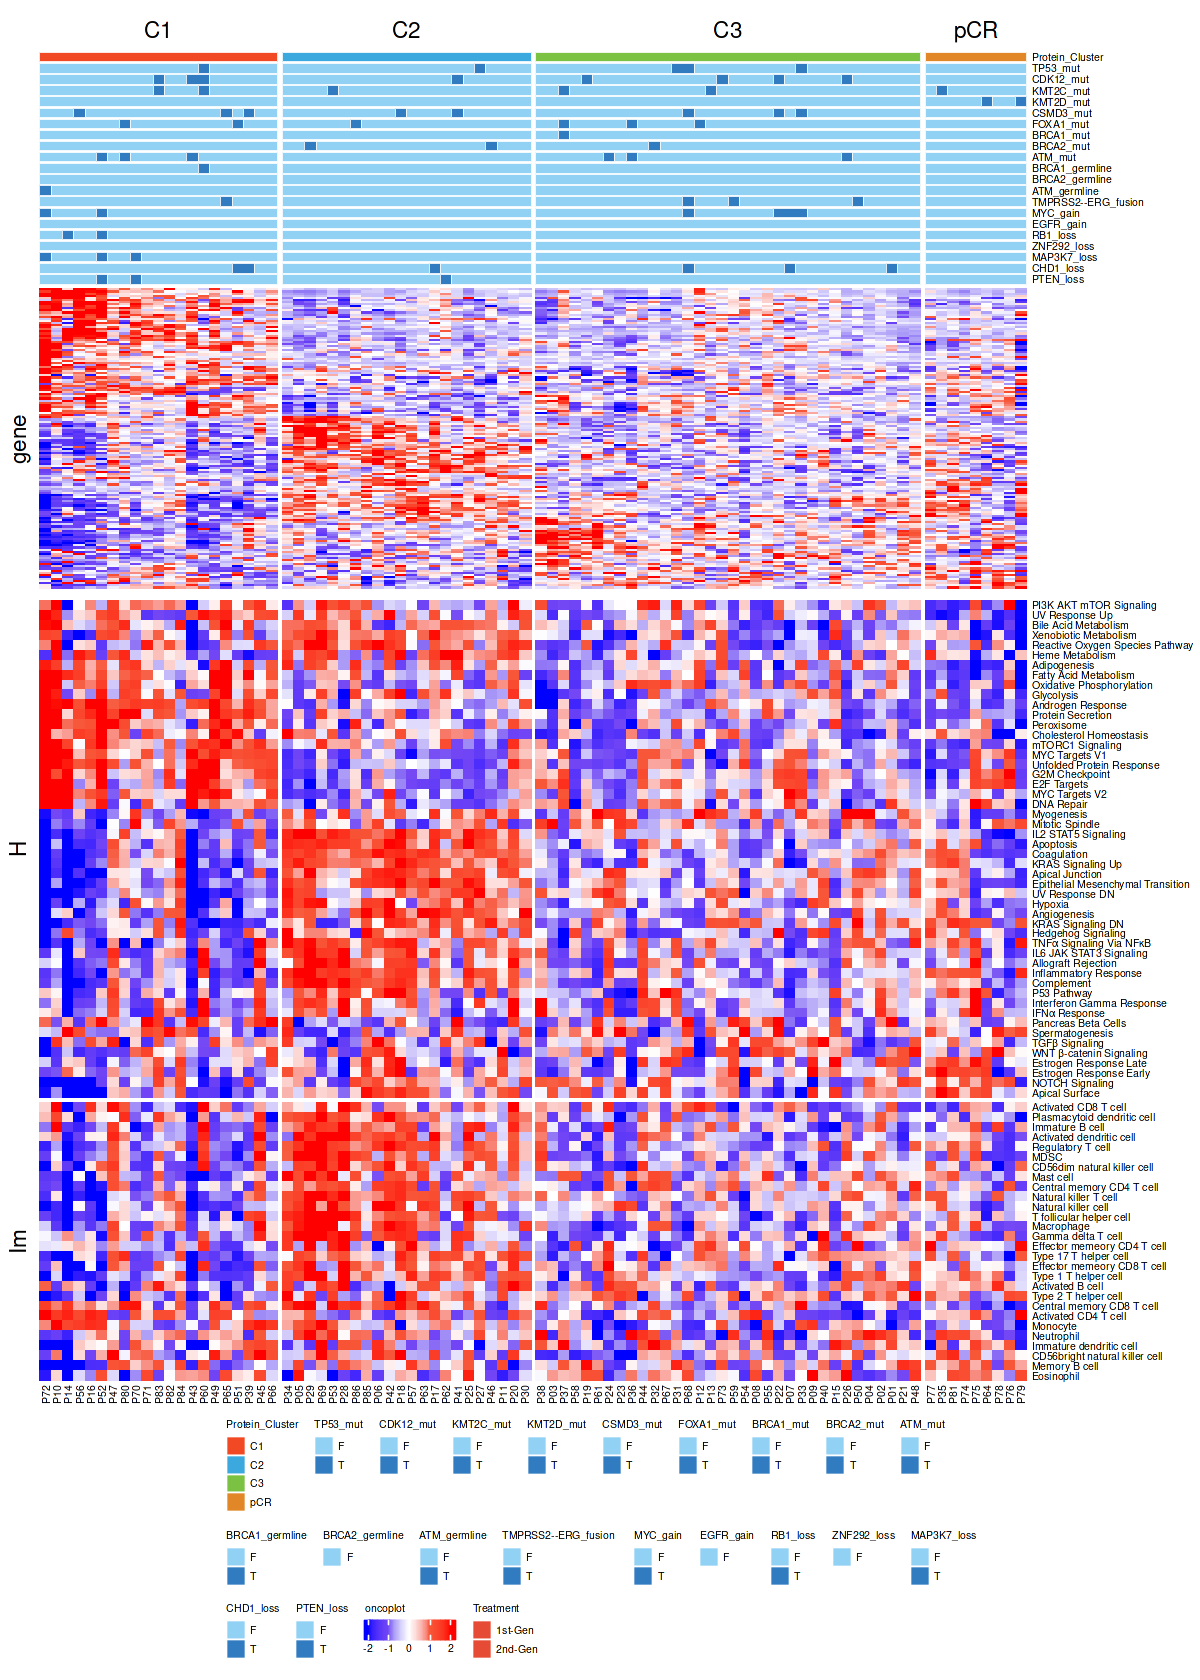

In [168]:
make.custom(10,14)
ht_list = hm1 %v% hm2

plt.fig1 = expr(
    draw(ht_list
         ,annotation_legend_list=list(lgd.bottom)
         ,merge_legend=TRUE
         ,annotation_legend_side = "bottom"
         ,heatmap_legend_side='bottom'
        )
)
eval(plt.fig1)

In [169]:
make.custom(10,14)
plt.fig1 %>% ysave('fig.1E.main_heatmap', outputdir = OUTPUTROOT)
mat_all %>% ysave('fig.1E.main_heatmap', outputdir = OUTPUTROOT)


[1] "[ 2026-08-03 08:47:46 ]  write 1 pdf at report_c3/fig.1E.main_heatmap.pdf"
[1] "[ 2026-08-03 08:47:46 ]  write 1 xlsx at report_c3/fig.1E.main_heatmap.xlsx"


## fig 1F clin Heatmap

### gen AR score data

1、PAM50分型——2017 JAMA onco  3分类

2、AR score打分——2015 Cell 

3、AR-active打分——2019 CCR AR-activity 9基因加权平均

4、ADT-response 打分——2018 Cancer res

5、NEPC signature打分——2016 Nature Med


In [7]:
i1 = db.importing('external_data/Figure_1_heatmap_clustering_noval/01-2017 JAMAonco-PAM50分型.xlsx') %>% pull('CDC20') 
i1

i2 = db.importing('external_data/Figure_1_heatmap_clustering_noval/02-2015 Cell.xlsx') %>% pull('AR.score')
i2

i3 = db.importing('external_data/Figure_1_heatmap_clustering_noval/03-2019 CCR.xlsx') %>% pull('AR-active')
i3

i4 = db.importing('external_data/Figure_1_heatmap_clustering_noval/04-2018-Cancer res-NIHMS1026227-supplement-supp_table_1.xlsx'
                  ,sheet_name = 2, startRow = 2) %>%pull("genes")
i4

i5 = db.importing('external_data/Figure_1_heatmap_clustering_noval/05-2016 NM-NEPC附表9.xlsx'
                  , sheet_name = 'Table S9', startRow = 2) %>%pull("HGNC.ID")
i5
sel_genes = list(i1=i1,i2=i2,i3=i3,i4=i4,i5=i5)

[1] "[ 2026-09-06 02:03:46 ]  read [ 01-2017 JAMAonco-PAM50分型.xlsx ] as ' 01-2017 JAMAonco-PAM50分型 ' from >  external_data/Figure_1_heatmap_clustering_noval"


[1] "KIF2C"   "EX01"    "CDCA1"   "BIRC5"   "CEP55"   "RRM2"    "CCNE1"  
 [8] "ORC6L"   "MYBL2"   "CCNB1"   "NAT1"    "CENPF"   "ANLN"    "MELK"   
[15] "KNTC2"   "CDC6"    "MKI67"   "UBE2T"   "MIA"     "PTTG1"   "UBE2C"  
[22] "MMP11"   "FGFR4"   "GRB7"    "CXXC5"   "FOXC1"   "PGR"     "ESR1"   
[29] "PHGDH"   "CDH3"    "ERBB2"   "BCL2"    "MAPT"    "BAG1"    "ACTR3B" 
[36] "EGFR"    "BLVRA"   "SFRP1"   "KRT5"    "KRT14"   "KRT17"   "TMEM45B"
[43] "GPR160"  "MYC"     "MLPH"    "TYMS"    "MDM2"    "FOXA1"   "SLC39A6"

[1] "[ 2026-09-06 02:03:46 ]  read [ 02-2015 Cell.xlsx ] as ' 02-2015 Cell ' from >  external_data/Figure_1_heatmap_clustering_noval"


[1] "KLK3"     "KLK2"     "PMEPA1"   "ABCC4"    "NKX3−1"   "C1orf116"
 [7] "FKBP5"    "ACSL3"    "ZBTB10"   "HERC3"    "PTGER4"   "MPHOSPH9"
[13] "EAF2"     "MED28"    "NNMT"     "MAF"      "GNMT"     "CENPN"   
[19] "ELL2"     "TMPRSS2"

[1] "[ 2026-09-06 02:03:46 ]  read [ 03-2019 CCR.xlsx ] as ' 03-2019 CCR ' from >  external_data/Figure_1_heatmap_clustering_noval"


[1] "KLK3"   "KLK2"   "STEAP1" "STEAP2" "NKX3-1" "FKBP5"  "PPAP2A" "ACSL3" 
[9] "RAB3B"

[1] "[ 2026-09-06 02:03:46 ]  read [ 04-2018-Cancer res-NIHMS1026227-supplement-supp_table_1.xlsx ] as ' 04-2018-Cancer res-NIHMS1026227-supplement-supp_table_1 ' from >  external_data/Figure_1_heatmap_clustering_noval"


[1] "PRKAG1"   "KIAA1210" "MORN3"    "TMEM133"  "CCDC151"  "EHHADH"  
 [7] "TXK"      "LRRC18"   "NUDT1"    "EZH2"     "CCL16"    "CLEC9A"  
[13] "SEMA3C"   "PRTFDC1"  "ALDH2"    "TACC2"    "HEPN1"    "KLK12"   
[19] "C8orf4"   "NLRP13"   "CRYM"     "FAHD2A"   "GLYATL1"  "HEY2"    
[25] "HJURP"    "KCNH8"    "LPGAT1"   "MSMB"     "NPR3"     "PEX11A"  
[31] "RBPMS2"   "SFTA3"    "SLC35F2"  "TFAP4"    "SOX14"    "B3GALTL" 
[37] "LSM7"     "RLN1"     "FAM134A"  "ID2"      "CDH26"    "SELE"    
[43] "GALM"     "FBXO43"   "DNAJC12"  "TM2D2"    "STMN1"    "NAV2"    
[49] "GABRB3"

[1] "[ 2026-09-06 02:03:46 ]  read [ 05-2016 NM-NEPC附表9.xlsx ] as ' 05-2016 NM-NEPC附表9 ' from >  external_data/Figure_1_heatmap_clustering_noval"


[1] "AR"           "CCND1"        "CIITA"        "CREBBP"       "CSDE1"       
 [6] "CYLD"         "DICER1"       "FHIT"         "FOXP1"        "HERPUD1"     
[11] "MMP2"         "MYH9"         "NUP93"        "PAX8"         "RBBP6"       
[16] "TRIM33"       "GATA2"        "MAPKAPK3"     "SPDEF"        "ASXL3"       
[21] "CAND2"        "ETV5"         "GPX2"         "JAKMIP2"      "KIAA0408"    
[26] "SOGA3"        "TRIM9"        "BRINP1"       "C7orf76"      "GNAO1"       
[31] "KCNB2"        "KCND2"        "LRRC16B"      "MAP10"        "NRSN1"       
[36] "PCSK1"        "PROX1"        "RGS7"         "SCG3"         "SEC11C"      
[41] "SEZ6"         "ST8SIA3"      "SVOP"         "SYT11"        "ARHGAP8"     
[46] "CATSPERB"     "EFNA4"        "EPN3"         "EVPL"         "HOXB13"      
[51] "KLK3"         "KLK4"         "LMAN1L"       "NKX3-1"       "OPHN1"       
[56] "PIEZO1"       "PRR5-ARHGAP8" "PSCA"         "RAB27B"       "RGS10"       
[61] "RIPK2"        "SLC25A37"     "SLC44A4"      "TC2N"         "UPK2"        
[66] "AURKA"        "DNMT1"        "EZH2"         "MYCN"         "RB1"

In [8]:
tpm = db.importing('export_by2_86_pCR_nonpCR/rna_tpm.dfx',row.names=1)
tpm = tpm %>% yscale_rows()

rn = rownames(tpm)
r = list(EX01="EXO1",CDCA1="NUF2",ORC6L="ORC6",KNTC2="NDC80",         
        PPAP2A="PLPP1",TMEM133="ARHGAP42",C8orf4="TCIM",         
        B3GALTL="B3GLCT",FAM134A="RETREG2",         
        C7orf76="SEM1",LRRC16B="CARMIL3",`NKX3−1`='NKX3-1'
    )


for (i in 1:5){
    n = paste0('i',i)
    s = sel_genes[[n]]
    for (k in names(r)){
        v = r[k]
        s[s==k] = v
    }
    sel_genes[[n]] =  s %>% unlist()
}
for (i in 1:5){
    n = paste0('i',i)
    i = sel_genes[[n]]
    cat ('len(i) = ', length(i) ,' len(rn x i) = ',rn %>% intersect(i) %>%length, setdiff(i,rn),'\n')
}


[1] "[ 2026-09-06 02:03:48 ]  read [ rna_tpm.dfx ] as ' rna_tpm ' from >  export_by2_86_pCR_nonpCR"
len(i) =  49  len(rn x i) =  49  
len(i) =  20  len(rn x i) =  20  
len(i) =  9  len(rn x i) =  9  
len(i) =  49  len(rn x i) =  49  
len(i) =  70  len(rn x i) =  69 PRR5-ARHGAP8 


In [9]:
sel_genes

$i1
 [1] "KIF2C"   "EXO1"    "NUF2"    "BIRC5"   "CEP55"   "RRM2"    "CCNE1"  
 [8] "ORC6"    "MYBL2"   "CCNB1"   "NAT1"    "CENPF"   "ANLN"    "MELK"   
[15] "NDC80"   "CDC6"    "MKI67"   "UBE2T"   "MIA"     "PTTG1"   "UBE2C"  
[22] "MMP11"   "FGFR4"   "GRB7"    "CXXC5"   "FOXC1"   "PGR"     "ESR1"   
[29] "PHGDH"   "CDH3"    "ERBB2"   "BCL2"    "MAPT"    "BAG1"    "ACTR3B" 
[36] "EGFR"    "BLVRA"   "SFRP1"   "KRT5"    "KRT14"   "KRT17"   "TMEM45B"
[43] "GPR160"  "MYC"     "MLPH"    "TYMS"    "MDM2"    "FOXA1"   "SLC39A6"

$i2
 [1] "KLK3"     "KLK2"     "PMEPA1"   "ABCC4"    "NKX3-1"   "C1orf116"
 [7] "FKBP5"    "ACSL3"    "ZBTB10"   "HERC3"    "PTGER4"   "MPHOSPH9"
[13] "EAF2"     "MED28"    "NNMT"     "MAF"      "GNMT"     "CENPN"   
[19] "ELL2"     "TMPRSS2" 

$i3
[1] "KLK3"   "KLK2"   "STEAP1" "STEAP2" "NKX3-1" "FKBP5"  "PLPP1"  "ACSL3" 
[9] "RAB3B" 

$i4
 [1] "PRKAG1"   "KIAA1210" "MORN3"    "ARHGAP42" "CCDC151"  "EHHADH"  
 [7] "TXK"      "LRRC18"   "NUDT1"    "EZH2"     "CCL16"    "CLEC9A"  
[13] "SEMA3C"   "PRTFDC1"  "ALDH2"    "TACC2"    "HEPN1"    "KLK12"   
[19] "TCIM"     "NLRP13"   "CRYM"     "FAHD2A"   "GLYATL1"  "HEY2"    
[25] "HJURP"    "KCNH8"    "LPGAT1"   "MSMB"     "NPR3"     "PEX11A"  
[31] "RBPMS2"   "SFTA3"    "SLC35F2"  "TFAP4"    "SOX14"    "B3GLCT"  
[37] "LSM7"     "RLN1"     "RETREG2"  "ID2"      "CDH26"    "SELE"    
[43] "GALM"     "FBXO43"   "DNAJC12"  "TM2D2"    "STMN1"    "NAV2"    
[49] "GABRB3"  

$i5
 [1] "AR"           "CCND1"        "CIITA"        "CREBBP"       "CSDE1"       
 [6] "CYLD"         "DICER1"       "FHIT"         "FOXP1"        "HERPUD1"     
[11] "MMP2"         "MYH9"         "NUP93"        "PAX8"         "RBBP6"       
[16] "TRIM33"       "GATA2"        "MAPKAPK3"     "SPDEF"        "ASXL3"       
[21] "CAND2"        "ETV5"         "GPX2"         "JAKMIP2"      "KIAA0408"    
[26] "SOGA3"        "TRIM9"        "BRINP1"       "SEM1"         "GNAO1"       
[31] "KCNB2"        "KCND2"        "CARMIL3"      "MAP10"        "NRSN1"       
[36] "PCSK1"        "PROX1"        "RGS7"         "SCG3"         "SEC11C"      
[41] "SEZ6"         "ST8SIA3"      "SVOP"         "SYT11"        "ARHGAP8"     
[46] "CATSPERB"     "EFNA4"        "EPN3"         "EVPL"         "HOXB13"      
[51] "KLK3"         "KLK4"         "LMAN1L"       "NKX3-1"       "OPHN1"       
[56] "PIEZO1"       "PRR5-ARHGAP8" "PSCA"         "RAB27B"       "RGS10"       
[61] "RIPK2"        "SLC25A37"     "SLC44A4"      "TC2N"         "UPK2"        
[66] "AURKA"        "DNMT1"        "EZH2"         "MYCN"         "RB1"

In [10]:
res = list()
for (s in 1:5){
    iname = paste0("i",s)
    i = sel_genes[[iname]]
    x = rn %>% intersect(i)
    mat = tpm[x,]
    index = mat %>% apply(2, sum)
    res[[iname]] = index
}
res = data.frame(res) %>% t %>% as.data.frame()
rownames(res) = c('PAM50 Index, Zhao et al.'
                  , 'AR activity Score, TCGA'
                  , 'AR-A Score, Spratt et al.'
                  , 'ADT-RS Score, Karnes et al.'
                  , 'Integrated NEPC Score, Beltran et al.'
                 )
res = res %>% yscale_rows() %>% as.matrix()
# res = res %>% as.matrix()
res

,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,⋯,P72,P73,P74,P75,P76,P77,P78,P79,P80,P81,P82,P83,P84,P85,P86
"PAM50 Index, Zhao et al.",-0.3704212,0.30611014,0.04763237,-0.22272347,-0.3685337,0.25846601,-0.2302541,-0.27291368,-0.07545427,1.3699426,0.9505931,-0.3366038,-0.3347487,2.874684,0.24979213,⋯,4.7467236,0.03256375,0.1258272,0.9367632,0.6857769,0.2567905,0.8351985,1.2170331,-0.3268520,1.7531264,1.5769049,1.072397,0.28244270,-0.0122795,-0.09650154
"AR activity Score, TCGA",-1.0181582,-0.28304629,-0.28175042,-0.08423045,0.0470699,0.04067152,-0.2949954,-0.38670394,-0.22277148,3.0621957,-0.6124943,1.0333422,1.1153150,2.633203,-0.54548490,⋯,4.6708253,0.08858894,-0.6537305,0.3285990,-0.4753670,-0.1504807,-0.3111341,1.1050224,-0.3028079,-0.2411211,1.1277626,1.265360,0.18718989,-0.8601089,-0.53934862
"AR-A Score, Spratt et al.",-0.7255237,-0.47048226,-0.58026921,-0.55070186,-0.5662203,-0.64098821,-0.3218798,-0.09666859,-0.47843289,3.7707020,-0.5666353,1.3872332,0.4397158,2.561894,-0.46204206,⋯,2.8709145,0.09051176,-0.5556362,-0.2686215,-0.1498764,-0.1822042,-0.1667060,0.2934373,0.1669489,-0.3570055,0.6667167,0.663092,0.07346517,-0.5549569,-0.37300243
"ADT-RS Score, Karnes et al.",-0.7545129,-0.04259598,1.06407108,0.11238264,0.4855208,-0.23190513,-0.3538442,-0.48295361,-0.31700941,2.0073677,1.1684751,0.8901141,0.2432600,2.033137,-0.67446985,⋯,0.5339646,-0.13002779,0.2480733,0.6645972,1.0017653,1.5224218,0.3805340,1.8279964,0.1602753,1.1581858,1.3281711,1.124361,1.26264709,0.2194153,0.13626146
"Integrated NEPC Score, Beltran et al.",-0.8420147,0.53825253,1.22986029,0.22738976,0.1915921,0.03734894,0.1766270,0.31213434,-0.02923606,0.9992662,0.4425123,1.6854717,0.1779229,1.505765,0.01206786,⋯,0.2948855,0.13471800,-0.1887156,2.4801235,0.2564179,1.4210702,0.5816102,1.5327864,-0.5003314,1.0488112,1.0001607,1.046710,0.75396543,-0.2616681,-0.76214075


In [11]:
res %>% t %>% summary()

 PAM50 Index, Zhao et al. AR activity Score, TCGA AR-A Score, Spratt et al.
 Min.   :-1.66366         Min.   :-1.2985         Min.   :-0.8111          
 1st Qu.:-0.55025         1st Qu.:-0.5815         1st Qu.:-0.5555          
 Median :-0.07929         Median :-0.2722         Median :-0.3545          
 Mean   : 0.00000         Mean   : 0.0000         Mean   : 0.0000          
 3rd Qu.: 0.25805         3rd Qu.: 0.1342         3rd Qu.: 0.1524          
 Max.   : 4.74672         Max.   : 4.6708         Max.   : 3.7707          
 ADT-RS Score, Karnes et al. Integrated NEPC Score, Beltran et al.
 Min.   :-2.6572             Min.   :-2.27410                     
 1st Qu.:-0.6708             1st Qu.:-0.69384                     
 Median : 0.0411             Median :-0.04901                     
 Mean   : 0.0000             Mean   : 0.00000                     
 3rd Qu.: 0.7400             3rd Qu.: 0.65907                     
 Max.   : 2.2942             Max.   : 2.48012                     

In [12]:
mainmat = db.importing('data/export_c3/fig1_subtype_heatmap_mat.dfx', row.names=1)
tsb.order = colnames(mainmat)

row.splt = db.importing('data/export_c3/fig1_subtype_row_cluster.dfx')$rc
col.splt = db.importing('data/export_c3/fig1_subtype_column_cluster.dfx')$cc
col.splt


[1] "[ 2026-09-06 02:03:54 ]  read [ fig1_subtype_heatmap_mat.dfx ] as ' fig1_subtype_heatmap_mat ' from >  data/export_c3"
[1] "[ 2026-09-06 02:03:54 ]  read [ fig1_subtype_row_cluster.dfx ] as ' fig1_subtype_row_cluster ' from >  data/export_c3"
[1] "[ 2026-09-06 02:03:54 ]  read [ fig1_subtype_column_cluster.dfx ] as ' fig1_subtype_column_cluster ' from >  data/export_c3"


[1] "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1" 
[13] "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C1"  "C2"  "C2"  "C2" 
[25] "C2"  "C2"  "C2"  "C2"  "C2"  "C2"  "C2"  "C2"  "C2"  "C2"  "C2"  "C2" 
[37] "C2"  "C2"  "C2"  "C2"  "C2"  "C2"  "C2"  "C3"  "C3"  "C3"  "C3"  "C3" 
[49] "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3" 
[61] "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3"  "C3" 
[73] "C3"  "C3"  "C3"  "C3"  "C3"  "pCR" "pCR" "pCR" "pCR" "pCR" "pCR" "pCR"
[85] "pCR" "pCR"

In [13]:
clin = db.importing('export_c3/fig1_clinical_pathological_heatmap_info.xlsx', sheet_name = 1) %>% 
    arrange(paitent.number %>% match(tsb.order)) %>%
    column_to_rownames("paitent.number") %>%
    select(-Group) %>% 
    mutate(Protein_Cluster = !!col.splt, .before = `Age.(≥70.y)`)
clin = clin %>% mutate(
    Clinical.T.stage = Clinical.T.stage %>% str_sub(1,2)
    , pT.stage = ifelse(pT.stage =='pCR', 'pCR', pT.stage %>% str_sub(1,2))
)
ref = c('F','T')
COL_ANNO_CLIN = list()
clin.data = data.frame(tsb = rownames(clin))
for (i in colnames(clin)){
    col = clin[[i]]
    i2 = i %>% str_replace_all(fixed('.'), " ") %>% str_replace(fixed("0 2"),'0.2')
    if (max(col,na.rm = TRUE) == 1){
        clin.data[[i2]] = ifelse(clin[,i] == 1, 'T', ifelse(clin[,i]==0,'F',NA)) %>% factor()
        COL_ANNO_CLIN[[i2]] = c(T="#444444",F='#F2F2F2')
    }else{
        clin.data[[i2]] = clin[[i]] %>% factor()
    }
}
COL_ANNO_CLIN = c(COL_ANNO_CLIN, list(
    Protein_Cluster= c(C1='#F04923',C2='#3BA9DD',C3='#7CC242',pCR='#E18727')
    , `Gleason score` = c("6"="#96cce8","7"="#506f84","8"="#bd634b","9"="#853e3a","10"="#a98b31")
    , `Clinical T stage` = structure(npg[c(3,5,1,6)], names =c('T2','T3','T4','Tx'))
    , `Clinical N stage` = c("N0"="#f2f2f2","N1"="#8b8a75","Nx"="#ae8833")
    , `MD Anderson classification` = c("0"="#f2f2f2","1"="#8b8a75","2"="#ae8833",'3' = '#c75e63')
    , `pT stage` = structure(c(npg[c(3,5,1,6)],'#E18727'), names =c('T2','T3','T4','Tx','pCR')) 
    , `pN lymph node metastasis (at RP)` = c("N0"="#f2f2f2","N1"="#8b8a75","Nx"="#ae8833")
))

clin.data = clin.data %>% column_to_rownames('tsb')
# clin.data = clin.data %>% cbind(res[rownames(clin.data),])
res = res['AR activity Score, TCGA',rownames(clin.data),drop=FALSE]
res
clin.data


[1] "[ 2026-09-06 02:03:54 ]  read [ fig1_clinical_pathological_heatmap_info.xlsx ] as ' fig1_clinical_pathological_heatmap_info ' from >  export_c3"


,P72,P10,P14,P56,P16,P52,P47,P80,P70,P71,P83,P82,P84,P43,P60,⋯,P50,P04,P02,P01,P21,P48,P77,P35,P81,P74,P75,P64,P78,P76,P79
"AR activity Score, TCGA",4.670825,3.062196,2.633203,2.183024,2.830105,1.825733,0.3528234,-0.3028079,0.1139356,0.6087798,1.26536,1.127763,0.1871899,0.3428313,1.624014,⋯,-1.24591,-0.08423045,-0.2830463,-1.018158,-0.9045481,-0.5429852,-0.1504807,-0.5523492,-0.2411211,-0.6537305,0.328599,-0.2626837,-0.3111341,-0.475367,1.105022


,Protein_Cluster,Age (≥70 y),Gleason score,Clinical T stage,pT stage,Clinical N stage,pN lymph node metastasis (at RP),MD Anderson classification,PSA (≥20 ng/ml) (at diagnosis before NAT),PSA (≥0.2 ng/ml) (before RP) (after NAT),PSA (≥0.2 ng/ml) (after RP 6weeks),Surgical margins,Perineural invasion,Capsule invision,Semina vesicle,NEPC differentiation (at RP),BCR_status,Radiographic recurrence
,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>
P72,C1,F,9,T2,T3,N1,N1,2,T,T,T,F,T,T,F,F,T,F
P10,C1,T,8,T3,T3,N1,N0,2,F,F,NA,F,T,F,T,F,F,T
P14,C1,F,7,T3,T3,Nx,N1,2,NA,T,T,T,T,F,T,F,T,T
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
P78,pCR,F,6,T2,pCR,N1,N0,0,T,F,NA,F,F,F,F,F,F,F
P76,pCR,F,6,T2,pCR,N0,N0,0,T,F,F,F,F,F,F,F,F,F
P79,pCR,T,7,Tx,pCR,N0,N0,0,T,F,NA,F,F,F,F,F,F,F


In [15]:
clin.data %>% group_by(Protein_Cluster) %>% summarise(n=n())

Protein_Cluster,n
<fct>,<int>
C1,21
C2,22
C3,34
pCR,9


In [177]:
res %>% as.data.frame %>% ysave('fig.1F_clin_AR_score',outputdir = OUTPUTROOT)

[1] "[ 2026-08-03 08:47:54 ]  write 1 xlsx at report_c3/fig.1F_clin_AR_score.xlsx"


In [178]:
COL_ANNO_CLIN$`Age (≥70 y)`

T         F 
"#444444" "#F2F2F2"

### plot fig 1F clin Heatmap

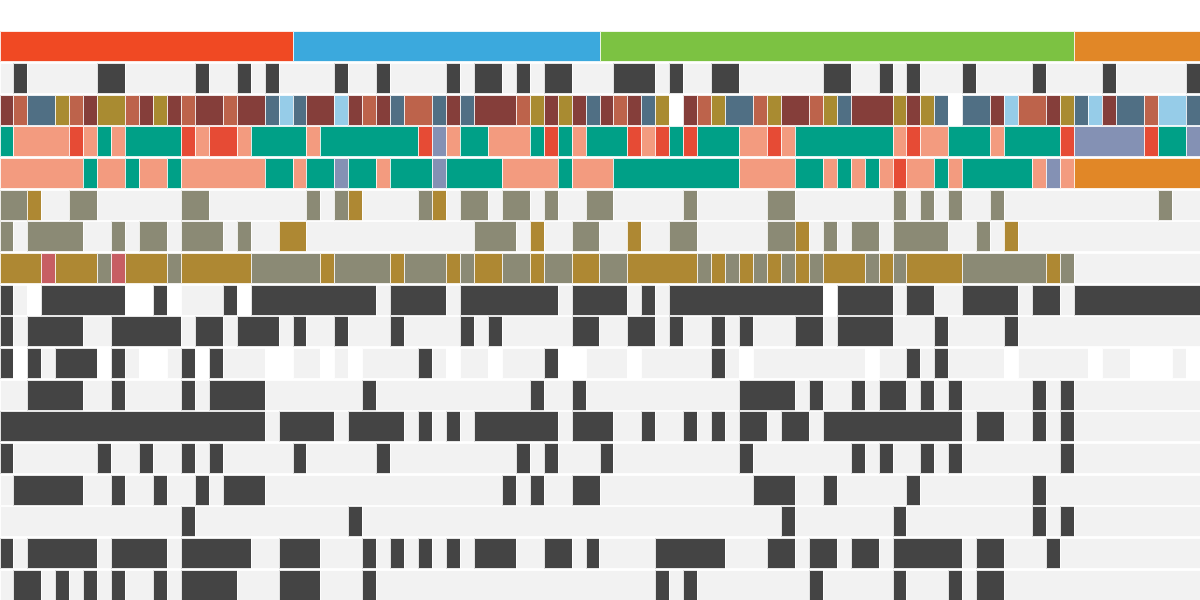

In [179]:
options(warn = -1)
make.custom(10,5)
ANNO_LABEL_FONTSIZE = 6
ANNO_NAME_FONTSIZE = 12
ha.top.clin = HeatmapAnnotation( 
#         PSA = anno_barplot(colData$PSA,ylim = c(0,15), height = unit(10,'mm'))
        df = clin.data
        ,height = unit(0.3*nrow(clin.data),unit='inch')
#         ,annotation_height = unit(8.5,'cm')
#         ,height = unit(9.5, "cm")
        ,simple_anno_size = unit(0.25,'in')
        ,border = FALSE
        ,na_col = 'white'
        ,gp = gpar(col = "white",lwd=0.5)
        ,col = COL_ANNO_CLIN
        # ,gp = gpar(fontsize=3)
        ,annotation_name_gp= gpar(fontsize = ANNO_NAME_FONTSIZE)
        # ,labels_gp = gpar(fontsize=4)
        ,annotation_legend_param = list(
#             nrow=NROW
            labels_gp = gpar(fontsize=ANNO_LABEL_FONTSIZE)
            , title_gp = gpar(fontsize=LEGEND_TITLE_FONTSIZE)
            )
    )
draw(ha.top.clin)
options(warn = 0)

In [180]:
clin.data %>% ysave('fig.1F_clin_data',outputdir = OUTPUTROOT)

[1] "[ 2026-08-03 08:47:54 ]  write 1 xlsx at report_c3/fig.1F_clin_data.xlsx"


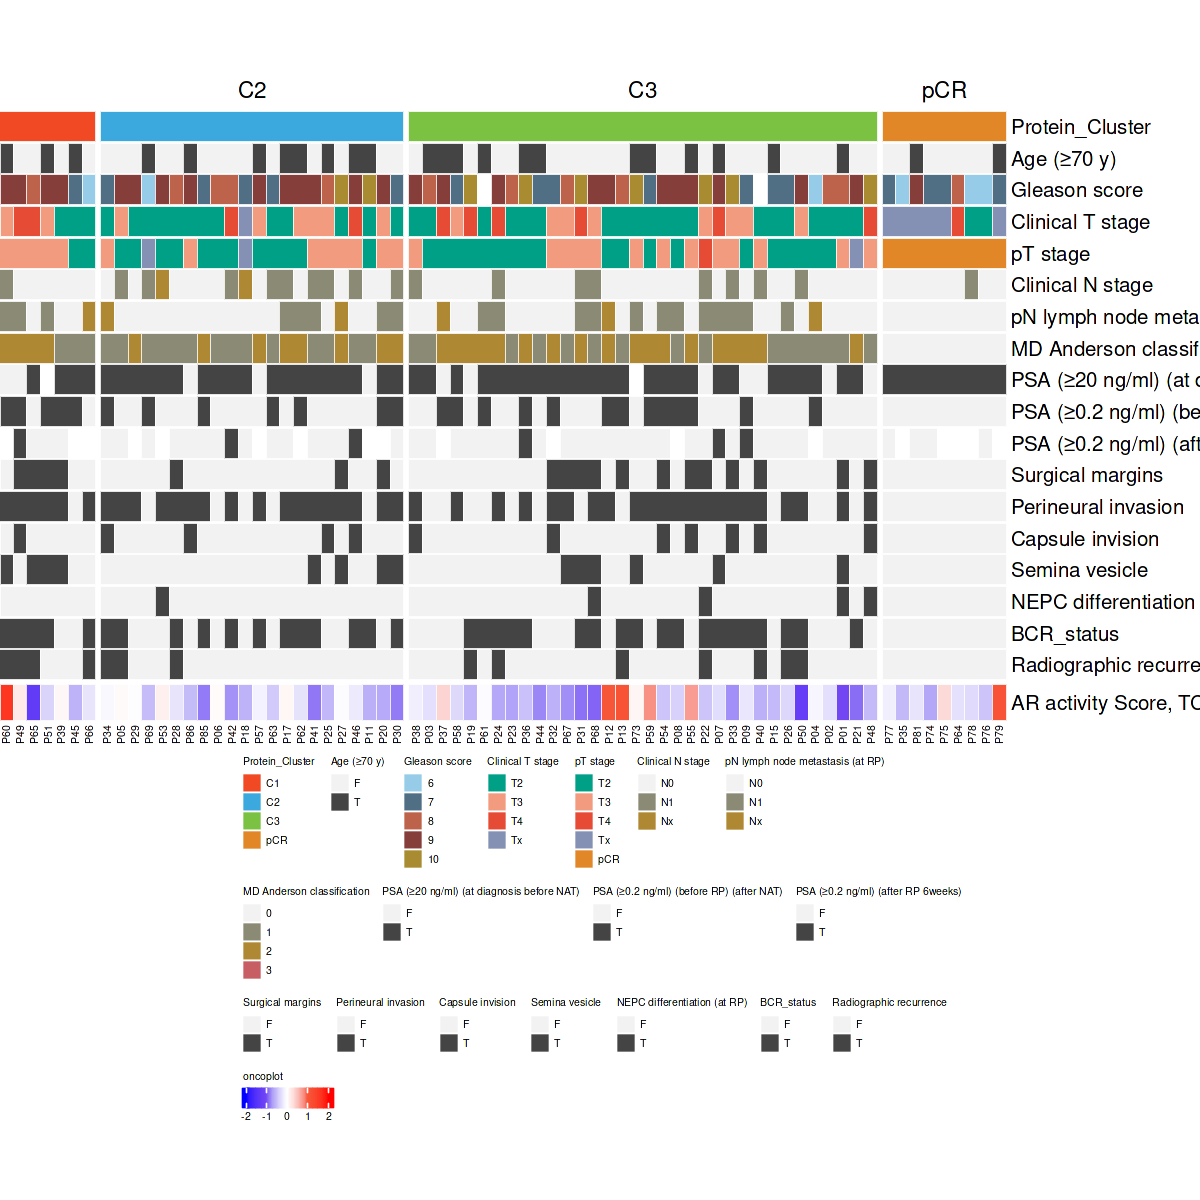

In [181]:
options(warn = -1)
make.custom(10,10)
par(mar = c(4, 4, 4, 4))
# mockmat = mainmat[1,]
# rownames(mockmat) = "G"
# mockmat[1,] = 0
fig1.b = Heatmap(matrix = res, width = unit(10,'inch'), height = unit(0.3,'inch')
        , cluster_column_slices = FALSE
        , cluster_row_slices = FALSE
        , show_column_names = TRUE
        , column_split = col.splt 
        , col = COL_HEATMAP_F
        , rect_gp = gpar(col = "white", lwd=0.5)
        , name = 'oncoplot'
        , top_annotation = ha.top.clin
#         , bottom_annotation = ha.bottom
#         , right_annotation = va
        , row_names_side = 'right'
        , row_names_gp = gpar(fontsize=12)
        , column_names_gp = gpar(fontsize=6)
        , cluster_rows = FALSE
        , clustering_method_rows = 'ward.D2'
        , clustering_method_columns = 'ward.D2'
#         , show_row_dend = FALSE
        , cluster_columns = FALSE
#         , col = COL_WES
        , na_col = '#EDEDED'
        , row_title_side = 'left'
        , heatmap_legend_param = list(direction = "horizontal"
#                                       ,nrow=NROW
                                      ,labels_gp = gpar(fontsize=6)
                                      ,title_gp = gpar(fontsize=6)
                                     )
    )

plt.fig1b = expr(
    draw(fig1.b
#          , annotation_legend_list=list(lgd.bottom)
         ,merge_legend=TRUE
         ,annotation_legend_side = "bottom"
         ,heatmap_legend_side='bottom'
        )
)

eval(plt.fig1b)
options(warn = 0)

In [182]:
options(warn = -1)
make.custom(15,10)
plt.fig1b %>% ysave('fig.1F_clin', outputdir = OUTPUTROOT)
options(warn = 0)

[1] "[ 2026-08-03 08:47:57 ]  write 1 pdf at report_c3/fig.1F_clin.pdf"


## fig S2B

This notebook only writes the source data (`fig.S2B.data.glyco_4levels.xlsx`); **Fig S2B is plotted manually** from these data.

In [6]:
a = c( 
    c('Glycoprotein1','Protein_Name',11,9),
    c('Glycosite2','Glycosite',11,9),
    c('Glycans3','sGlycan',11,9),
    c('Glycopiptides4','GID',11,9)
  )
data = list()
for (i in seq(1,length(a),by = 4)){
    vname   = a[i]
    colname = a[i+1]
    mat = db.importing(paste0('mat',vname),frm = 'external_data/Glycosylation/washed') %>% 
        column_to_rownames(colname) %>% as.matrix
    des = db.importing(paste0('des',vname),frm = 'external_data/Glycosylation/washed') %>% 
        column_to_rownames(colname) %>%
        dplyr::rename(HM = HighMannose,Fu = Fucose, SA=`Sialic Acid`,Bs = Bisect) %>%
        dplyr::select(HM,Fu,SA,Bs, everything())
    data[[paste0('mat',vname)]] = mat
    data[[paste0('des',vname)]] = des
}

[1] "[ 2026-08-08 07:14:42 ]  read [ matGlycoprotein1.dfx ] as ' matGlycoprotein1 ' from >  external_data/Glycosylation/washed"
[1] "[ 2026-08-08 07:14:42 ]  read [ desGlycoprotein1.dfx ] as ' desGlycoprotein1 ' from >  external_data/Glycosylation/washed"
[1] "[ 2026-08-08 07:14:42 ]  read [ matGlycosite2.dfx ] as ' matGlycosite2 ' from >  external_data/Glycosylation/washed"
[1] "[ 2026-08-08 07:14:42 ]  read [ desGlycosite2.dfx ] as ' desGlycosite2 ' from >  external_data/Glycosylation/washed"
[1] "[ 2026-08-08 07:14:42 ]  read [ matGlycans3.dfx ] as ' matGlycans3 ' from >  external_data/Glycosylation/washed"
[1] "[ 2026-08-08 07:14:42 ]  read [ desGlycans3.dfx ] as ' desGlycans3 ' from >  external_data/Glycosylation/washed"
[1] "[ 2026-08-08 07:14:42 ]  read [ matGlycopiptides4.dfx ] as ' matGlycopiptides4 ' from >  external_data/Glycosylation/washed"
[1] "[ 2026-08-08 07:14:42 ]  read [ desGlycopiptides4.dfx ] as ' desGlycopiptides4 ' from >  external_data/Glycosylation/washed"


In [8]:
data %>% ysave('fig.S2B.data.glyco_4levels', outputdir = OUTPUTROOT)

[1] "[ 2026-08-08 07:16:00 ]  write 1 xlsx at report_c3/fig.S2B.data.glyco_4levels.xlsx"


## fig S2C

In [183]:
COL_SNV_RATE_COMPARE = c(npg[1],'#3c5486',npg[7])

In [184]:
sel_symbols = c('FOXA1','SPOP','KMT2D','KMT2C','TP53','KDM6A','SYNE1','ZMYM3','BRCA2',
         'PTEN','MED12','BRAF','ATM','PIK3CA','CTNNB1','CDK12','BRCA1','CHD1','IDH1')



In [185]:
snv_tcga = db.importing('external_data/a_new_exteranl_validation_data/external_data/public_data_summary/2016 TCGA-RNAseqIndex of _runs_stddata__2016_01_28_data_PRAD_20160128/prad_tcga/data_mutations.txt')
snv_tcga


[1] "[ 2026-08-03 08:47:57 ]  read [ data_mutations.txt ] as ' data_mutations ' from >  external_data/a_new_exteranl_validation_data/external_data/public_data_summary/2016 TCGA-RNAseqIndex of _runs_stddata__2016_01_28_data_PRAD_20160128/prad_tcga"


Hugo_Symbol,Entrez_Gene_Id,Center,NCBI_Build,Chromosome,Start_Position,End_Position,Strand,Consequence,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele1,Tumor_Seq_Allele2,dbSNP_RS,⋯,CGC_Mutation_Type,DrugBank,Genome_Change,OREGANNO_Values,Protein_Change,Transcript_Strand,FamilialCancerDatabase_Syndromes,CCLE_ONCOMAP_overlapping_mutations,GO_Cellular_Component,UniProt_Natural_Variations,Annotation_Transcript,Refseq_mRNA_Id,pox_cutoff,oxoGCut,Tumorscape_Deletion_Peaks
<chr>,<int>,<chr>,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<int>,<chr>
HIVEP3,59269,broad.mit.edu,GRCh37,1,41978662,41978662,+,missense_variant,Missense_Mutation,SNP,G,G,A,NA,⋯,NA,NA,g.chr1:41978662G>A,NA,p.A2077V,-,NA,NA,cytoplasm|nucleus,NA,ENST00000372584.1,NM_001127714.2,0.004672,0,Myeloproliferative disorder(586;0.0367)
PCDHA4,56144,broad.mit.edu,GRCh37,5,140187629,140187629,+,missense_variant,Missense_Mutation,SNP,C,C,T,NA,⋯,NA,NA,g.chr5:140187629C>T,NA,p.S286L,+,NA,NA,NA,NA,ENST00000530339.1,NM_018907.2,0.029380,0,NA
PPP3CC,5533,broad.mit.edu,GRCh37,8,22368644,22368644,+,missense_variant,Missense_Mutation,SNP,C,C,A,NA,⋯,NA,NA,g.chr8:22368644C>A,NA,p.T177K,+,NA,NA,cytosol,NA,ENST00000240139.5,NM_005605.4,0.014758,0,Prostate(55;0.104)
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
MIR371A,442916,broad.mit.edu,GRCh37,19,54290977,54290977,+,mature_miRNA_variant,RNA,SNP,G,G,A,NA,⋯,NA,NA,g.chr19:54290977G>A,NA,NA,-,NA,NA,NA,NA,ENST00000595160.1,NR_029864.1|NR_029865.1|NR_039909.1,1,0,NA
TRBV5-4,28611,broad.mit.edu,GRCh37,7,142168890,142168890,+,5_prime_UTR_variant,5'UTR,SNP,C,C,T,rs143671051,⋯,NA,NA,g.chr7:142168890C>T,NA,NA,-,NA,NA,NA,NA,ENST00000454561.2,NA,1,0,NA
TRBV5-4,28611,broad.mit.edu,GRCh37,7,142168862,142168862,+,5_prime_UTR_variant,5'UTR,SNP,A,A,G,rs140095394,⋯,NA,NA,g.chr7:142168862A>G,NA,NA,-,NA,NA,NA,NA,ENST00000454561.2,NA,1,0,NA


In [186]:
snv2 = snv_tcga %>% 
    filter(Variant_Classification %in% 
                    c('Missense_Mutation','Silent','Frame_Shift_Ins','In_Frame_Del','Translation_Start_Site',
                      'In_Frame_Ins','Nonsense_Mutation','Splice_Site','Frame_Shift_Del','Nonstop_Mutation'
                     )) %>% 
    distinct(Hugo_Symbol, Tumor_Sample_Barcode)
snv2


Hugo_Symbol,Tumor_Sample_Barcode
<chr>,<chr>
HIVEP3,TCGA-G9-6353-01
PCDHA4,TCGA-G9-6353-01
PPP3CC,TCGA-G9-6353-01
⋮,⋮
FAM170A,TCGA-KK-A59V-01
MFRP,TCGA-J4-A67T-01
NUDT11,TCGA-EJ-A46E-01


In [187]:
N = snv_tcga$Tumor_Sample_Barcode %>% unique %>% length
N

stat_tcga = snv2 %>% group_by(Hugo_Symbol) %>% 
    summarise(n=Tumor_Sample_Barcode %>% unique%>% length) %>%
    mutate(freq = n / !!N * 100, source='TCGA-PRAD') %>%
    filter(Hugo_Symbol %in% !!sel_symbols) %>%
    arrange(match(Hugo_Symbol,sel_symbols)) %>%
    dplyr::select(Hugo_Symbol, freq, source, n)
stat_tcga

[1] 499

Hugo_Symbol,freq,source,n
<chr>,<dbl>,<chr>,<int>
FOXA1,6.212425,TCGA-PRAD,31
SPOP,11.422846,TCGA-PRAD,57
KMT2D,6.012024,TCGA-PRAD,30
⋮,⋮,⋮,⋮
BRCA1,0.4008016,TCGA-PRAD,2
CHD1,1.8036072,TCGA-PRAD,9
IDH1,1.2024048,TCGA-PRAD,6


In [188]:
# the freq data is the supplemental excel of the paper
snv_natcan = readxl::read_xlsx('external_data/a_new_exteranl_validation_data/external_data/public_data_collaborator/data_for_collaborator/2024-natcan/43018_2024_820_MOESM2_ESM.xlsx', sheet = 'Supplementary Table 2', skip=1)
stat_natcan = snv_natcan[,5:ncol(snv_natcan)] %>% 
    rename(Gene=`Gene...5`) %>% 
    filter(!is.na(Gene)) %>%
    dplyr::select(Hugo_Symbol=Gene, freq = `Our cohort_freq`) %>%
    filter(Hugo_Symbol %in% !!sel_symbols) %>% 
    arrange(match(Hugo_Symbol,sel_symbols)) %>%
    mutate(freq= freq*100, source='Nature Cancer 2024', n=NA) %>%
    dplyr::select(Hugo_Symbol, freq, source, n)
stat_natcan


New names:
• `Gene` -> `Gene...1`
• `` -> `...3`
• `` -> `...4`
• `Gene` -> `Gene...5`


Hugo_Symbol,freq,source,n
<chr>,<dbl>,<chr>,<lgl>
FOXA1,31.2,Nature Cancer 2024,NA
SPOP,15.2,Nature Cancer 2024,NA
KMT2D,12.0,Nature Cancer 2024,NA
⋮,⋮,⋮,⋮
BRCA1,2.4,Nature Cancer 2024,NA
CHD1,1.6,Nature Cancer 2024,NA
IDH1,1.6,Nature Cancer 2024,NA


In [189]:

snv_our = db.importing('export_by2_86_pCR_nonpCR/wes_snv_all.dfx')
snv_our


[1] "[ 2026-08-03 08:47:58 ]  read [ wes_snv_all.dfx ] as ' wes_snv_all ' from >  export_by2_86_pCR_nonpCR"


Hugo_Symbol,NCBI_Build,Chromosome,Start_Position,End_Position,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele2,Tumor_Sample_Barcode,HGVSp_Short,VAF,symbol,a,n,t,p,ap,Custom_Label,Clin_classification
<chr>,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
ANKRD34A,GRCh37,chr1,145474457,145474457,Missense_Mutation,SNP,G,A,P01,p.A377T,8.11,ANKRD34A,K00143,NR22030714,TR22030713,P010143142842401,K00143P010143142842401,P01,non.pCR
PEAR1,GRCh37,chr1,156878538,156878538,Missense_Mutation,SNP,G,T,P01,p.G403W,7.55,PEAR1,K00143,NR22030714,TR22030713,P010143142842401,K00143P010143142842401,P01,non.pCR
DARC,GRCh37,chr1,159175236,159175236,Missense_Mutation,SNP,G,T,P01,p.G5W,5.80,DARC,K00143,NR22030714,TR22030713,P010143142842401,K00143P010143142842401,P01,non.pCR
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
FLNA,GRCh37,chrX,153588575,153588575,Missense_Mutation,SNP,C,A,P86,p.E1196D,6.15,FLNA,K00269,NR22303726,TR22303748,P010269148140701,K00269P010269148140701,P86,non.pCR
POLA1,GRCh37,chrX,24757606,24757606,Missense_Mutation,SNP,C,A,P86,p.Q719K,6.78,POLA1,K00269,NR22303726,TR22303748,P010269148140701,K00269P010269148140701,P86,non.pCR
MXRA5,GRCh37,chrX,3239590,3239590,Missense_Mutation,SNP,G,T,P86,p.T1404N,8.70,MXRA5,K00269,NR22303726,TR22303748,P010269148140701,K00269P010269148140701,P86,non.pCR


In [190]:
snv_our$Variant_Classification %>% unique

[1] "Missense_Mutation"      "Nonsense_Mutation"      "Splice_Site"           
[4] "In_Frame_Del"           "Frame_Shift_Del"        "Nonstop_Mutation"      
[7] "In_Frame_Ins"           "Translation_Start_Site" "Frame_Shift_Ins"

In [191]:
snv2 = snv_our %>% 
    filter(Variant_Classification %in% 
                    c('Missense_Mutation','Silent','Frame_Shift_Ins','In_Frame_Del','Translation_Start_Site',
                      'In_Frame_Ins','Nonsense_Mutation','Splice_Site','Frame_Shift_Del','Nonstop_Mutation'
                     )) %>% 
    distinct(Hugo_Symbol, Tumor_Sample_Barcode)

In [192]:
N = snv_our$Tumor_Sample_Barcode %>% unique %>% length
N

stat_our = snv2 %>% group_by(Hugo_Symbol) %>% 
    summarise(n=Tumor_Sample_Barcode %>% unique%>% length) %>%
    mutate(freq = n / !!N * 100, source='Our data') %>%
    filter(Hugo_Symbol %in% !!sel_symbols) %>%
    arrange(match(Hugo_Symbol,sel_symbols)) %>%
    dplyr::select(Hugo_Symbol, freq, source, n)
stat_our

[1] 86

Hugo_Symbol,freq,source,n
<chr>,<dbl>,<chr>,<int>
FOXA1,6.976744,Our data,6
SPOP,2.325581,Our data,2
KMT2D,2.325581,Our data,2
⋮,⋮,⋮,⋮
CDK12,9.302326,Our data,8
BRCA1,1.162791,Our data,1
CHD1,5.813953,Our data,5


In [193]:
nrow(stat_our)
nrow(stat_natcan)
nrow(stat_tcga)

[1] 17

[1] 19

[1] 19

In [194]:
stat_tcga = stat_tcga %>%
  complete(Hugo_Symbol = sel_symbols,fill = list(freq=0,source='TCGA-PRAD', n=0))
stat_natcan = stat_natcan %>%
  complete(Hugo_Symbol = sel_symbols,fill = list(freq=0, source='Nature Cancer 2024', n=0))
stat_our = stat_our %>%
  complete(Hugo_Symbol = sel_symbols,fill = list(freq=0,source='Our data', n=0))

In [195]:
nrow(stat_our)
nrow(stat_natcan)
nrow(stat_tcga)

[1] 19

[1] 19

[1] 19

In [196]:

data = rbind(stat_our, stat_natcan, stat_tcga) %>% 
    mutate(source=factor(source, levels = c('Our data','Nature Cancer 2024','TCGA-PRAD')),
           Hugo_Symbol = factor(Hugo_Symbol,levels = sel_symbols)
          )
data


Hugo_Symbol,freq,source,n
<fct>,<dbl>,<fct>,<int>
ATM,6.976744,Our data,6
BRAF,0.000000,Our data,0
BRCA1,1.162791,Our data,1
⋮,⋮,⋮,⋮
SYNE1,7.014028,TCGA-PRAD,35
TP53,12.224449,TCGA-PRAD,61
ZMYM3,2.404810,TCGA-PRAD,12


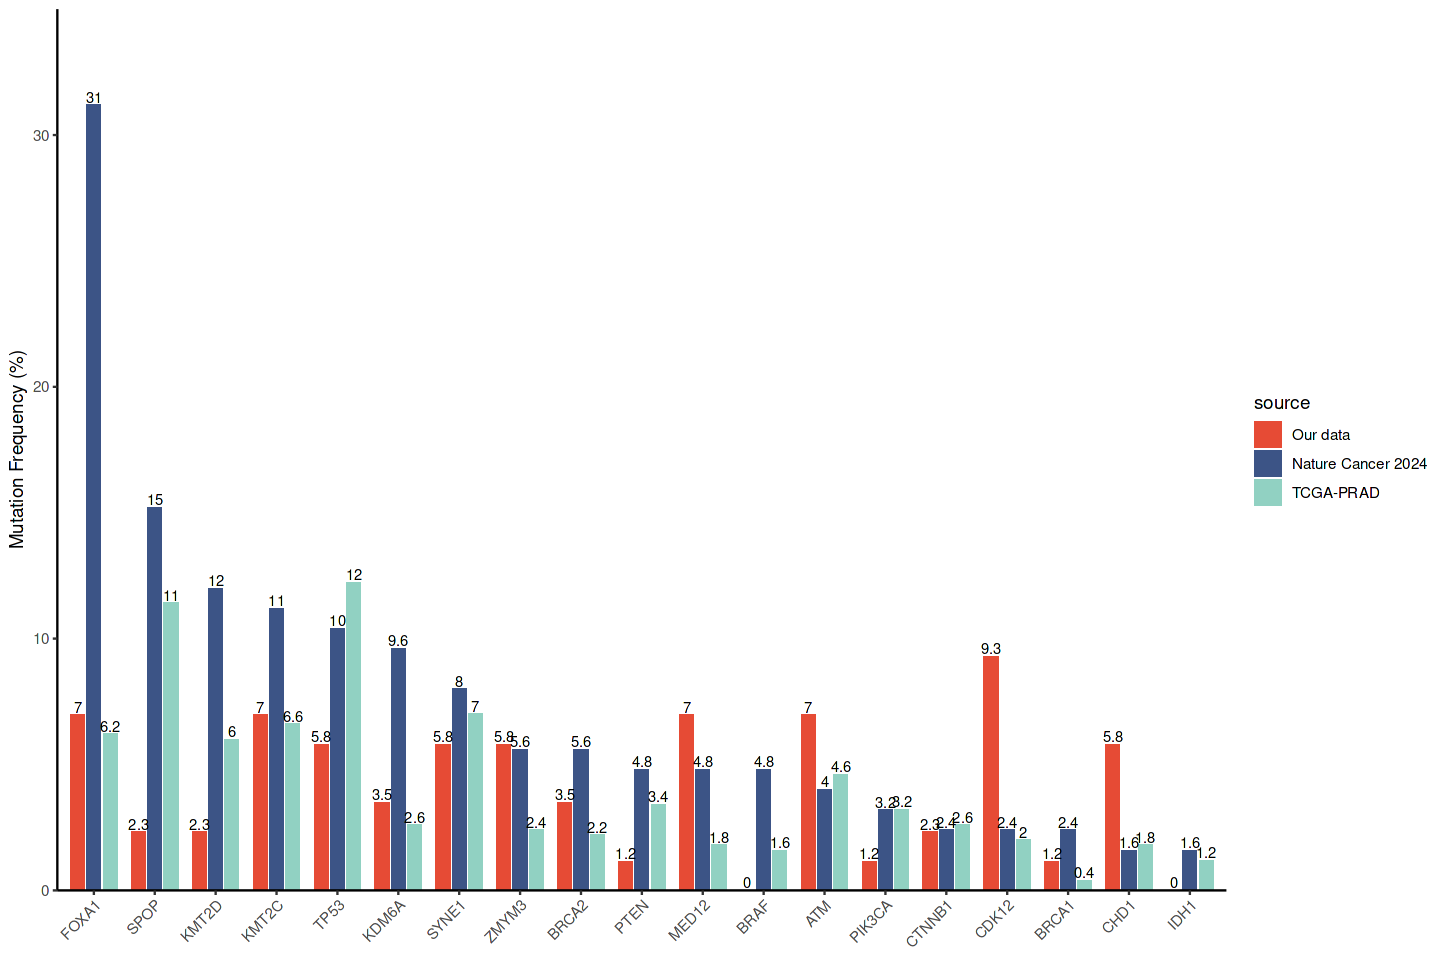

In [197]:
make.wide()
fig.s2c = data %>% ggplot(aes(x = Hugo_Symbol, y=freq, fill=source)) +
    geom_bar(stat = "identity", width=0.7, position = position_dodge(width = 0.8)) + 
    geom_text(aes(label = signif(freq,2)),vjust=-0.2, size = 3, position = position_dodge(width = 0.8)) +
    theme_classic() +
    labs(x = NULL, 
       y = "Mutation Frequency (%)") +
    scale_fill_manual(values=COL_SNV_RATE_COMPARE) +
    scale_y_continuous(expand = c(0,0), limits = c(0,35)) +
    theme(axis.text.x = element_text(angle = 45,hjust = 1))
fig.s2c


In [198]:
fig.s2c %>% ysave('fig.S2C.frequencies_compare_cohorts',outputdir = OUTPUTROOT)

[1] "[ 2026-08-03 08:48:00 ]  write 1 pdf at report_c3/fig.S2C.frequencies_compare_cohorts.pdf"


In [199]:
data %>% mutate(n=ifelse(n==0,ifelse(freq==0,0,NA),n)) %>% ysave('fig.S2C.data.frequencies_compare_cohorts', table_title_lines='Fig. S2C Source data to plot fig.S2C frequencies_compare_cohorts',outputdir = OUTPUTROOT)


[1] "[ 2026-08-03 08:48:00 ]  write 1 xlsx at report_c3/fig.S2C.data.frequencies_compare_cohorts.xlsx"


## fig S3A S3B S3C
**Fig S3A–S3C — manually generated.** This panel was drawn manually with external tools; there is no plotting code in this repository. (NHT duration, ARi regimen distribution and AR activity by regimen)

## fig S3F S3G S3H ext survival data

In [52]:
library(survival)
COL_ANNO_3G = list(Group=c(C1='#F04923',C2='#3BA9DD',Co='#8A9197'),
                   Cohort=c(Train='#198E5C',Valid='#EF7F29'),
                   Group3=c(C1='#F04923',C2='#3BA9DD',C3='#7CC242')
                  )
plot_bcr = function(data, ti){
    g1 =c()
    g2 = c()
    pval = c()
    msg = c()
    grps = data$Group %>% unique
    cat(ti, grps,'\n')
    for (g in combn(grps,2,simplify = FALSE)){
        diff_AB <- survival::survdiff(Surv(BCR_month, BCR_status) ~ Group, data = data, subset = Group %in% g,  rho = 0)
        g1 %<>% c(g[1])
        g2 %<>% c(g[2])
        pval %<>% c(diff_AB$pvalue)
        
        msg %<>% c(paste(g[1],'vs',g[2],'pval =',sprintf(paste0("%.", 4, "f"), diff_AB$pvalue),'\n'))
    }
    sum = data %>% group_by(Group) %>% summarise(n = n()) %>% as.data.frame()
    for (i in 1:nrow(sum)){
        msg %<>% c(paste(sum[i, 'Group'],' = ',sum[i, 'n'],'\n', sep = ''))
    }
    stats = data.frame(g1=g1,g2=g2,pval=pval)
    msg = msg %>% str_flatten()
    
    break_interval <- ceiling(max(data$BCR_month) / 5) 
    
    fit = survfit(Surv(BCR_month, BCR_status) ~ Group, data = data)
    fig = survminer::ggsurvplot(fit, data = data
#                                   , palette =  COL_Group3
                         ,risk.table = TRUE # Add risk table
                         ,pval = TRUE # Add p-value
                         ,conf.int = FALSE # Add confidence interval
    #                      ,risk.table.col = "strata"
    #                      ,test.for.trend = TRUE
                         ,surv.median.line = 'hv'
                        ,color = 'Group'
                        , palette = COL_ANNO_3G$Group3
                        ,break.x.by = break_interval
                         ,xlab = 'Time (Months)'
    #                      ,xlim=c(0,90)
                        ,title=paste(ti)
                        )
    
    fig$plot = fig$plot %+% annotate("text", x = Inf, y = Inf, label = msg, 
                  hjust = 1.1, vjust = 1.1, 
                  size = 3, color = "black", 
                  family = "sans", 
                  parse = FALSE)  %+%
        theme(text = element_text(size = 24)) 

    fig
}

In [53]:
## Data used is generated by GEN_EXT_SURVIVAL_DATA_PY.ipynb
## to generate the ext dataframe need


In [54]:
glx = db.importing('ext_data_glx_source.dfx',frm='export_c3', col.names='tag') %>% pull(tag)
glx

[1] "[ 2026-08-08 07:52:48 ]  read [ ext_data_glx_source.dfx ] as ' ext_data_glx_source ' from >  export_c3"


[1] "2016_TCGA"           "2018_Cancer_cell"    "2019_PNAS"          
[4] "2023_Mol_Cell"       "2024_CRM"            "2024_natcan_prt"    
[7] "2024_natcan_rna"     "2019_CancerCell_prt" "2019_CancerCell_rna"

[1] "[ 2026-08-08 07:56:48 ]  read [ ext_data_2016_TCGA_data_pca.dfx ] as ' ext_data_2016_TCGA_data_pca ' from >  export_c3"
2016_TCGA OS C2 C3 C1 
[1] "[ 2026-08-08 07:56:49 ]  write 1 pdf at report_c3/fig.S3F.S3G.S3H/fig.S3F.S3G.S3H.ext_2016_TCGA_OS.pdf"
2016_TCGA DFS C2 C3 C1 


Warning message in .add_surv_median(p, fit, type = surv.median.line, fun = fun, :
“Median survival not reached.”


[1] "[ 2026-08-08 07:56:50 ]  write 1 pdf at report_c3/fig.S3F.S3G.S3H/fig.S3F.S3G.S3H.ext_2016_TCGA_DFS.pdf"
[1] "[ 2026-08-08 07:56:50 ]  read [ ext_data_2018_Cancer_cell_data_pca.dfx ] as ' ext_data_2018_Cancer_cell_data_pca ' from >  export_c3"
2018_Cancer_cell BCR C1 C3 C2 


Warning message in .add_surv_median(p, fit, type = surv.median.line, fun = fun, :
“Median survival not reached.”


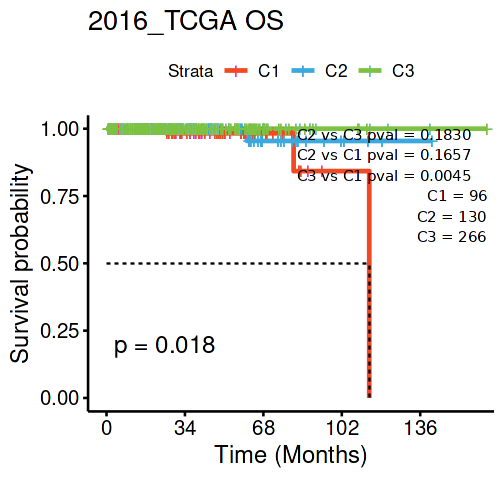

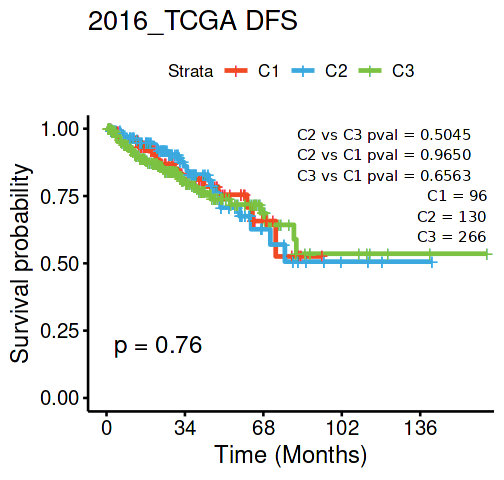

[1] "[ 2026-08-08 07:56:51 ]  write 1 pdf at report_c3/fig.S3F.S3G.S3H/fig.S3F.S3G.S3H.ext_2018_Cancer_cell_BCR.pdf"
[1] "[ 2026-08-08 07:56:51 ]  read [ ext_data_2019_PNAS_data_pca.dfx ] as ' ext_data_2019_PNAS_data_pca ' from >  export_c3"
2019_PNAS OS C3 C2 C1 


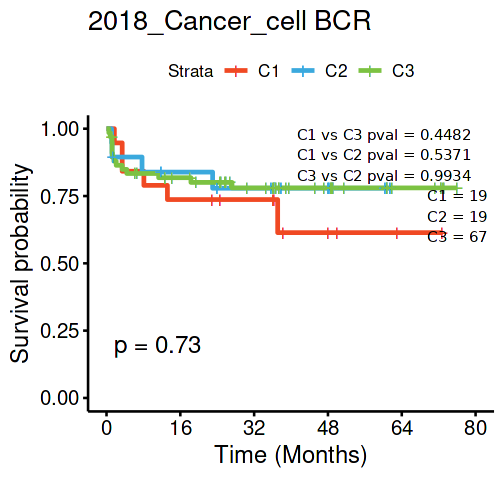

[1] "[ 2026-08-08 07:56:52 ]  write 1 pdf at report_c3/fig.S3F.S3G.S3H/fig.S3F.S3G.S3H.ext_2019_PNAS_OS.pdf"
[1] "[ 2026-08-08 07:56:52 ]  read [ ext_data_2023_Mol_Cell_data_pca.dfx ] as ' ext_data_2023_Mol_Cell_data_pca ' from >  export_c3"
2023_Mol_Cell OS C2 C3 C1 


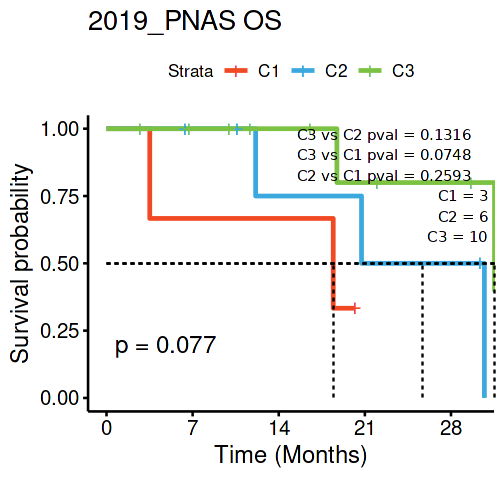

[1] "[ 2026-08-08 07:56:52 ]  write 1 pdf at report_c3/fig.S3F.S3G.S3H/fig.S3F.S3G.S3H.ext_2023_Mol_Cell_OS.pdf"
[1] "[ 2026-08-08 07:56:52 ]  read [ ext_data_2024_CRM_data_pca.dfx ] as ' ext_data_2024_CRM_data_pca ' from >  export_c3"
2024_CRM BCR C3 C2 C1 


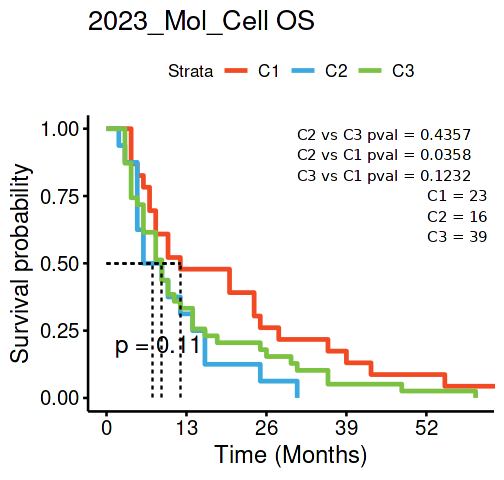

[1] "[ 2026-08-08 07:56:53 ]  write 1 pdf at report_c3/fig.S3F.S3G.S3H/fig.S3F.S3G.S3H.ext_2024_CRM_BCR.pdf"
[1] "[ 2026-08-08 07:56:53 ]  read [ ext_data_2024_natcan_prt_data_pca.dfx ] as ' ext_data_2024_natcan_prt_data_pca ' from >  export_c3"
2024_natcan_prt BCR C2 C1 C3 


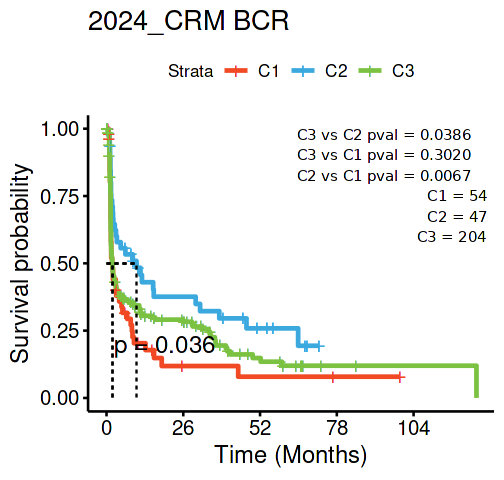

[1] "[ 2026-08-08 07:56:54 ]  write 1 pdf at report_c3/fig.S3F.S3G.S3H/fig.S3F.S3G.S3H.ext_2024_natcan_prt_BCR.pdf"
[1] "[ 2026-08-08 07:56:54 ]  read [ ext_data_2024_natcan_rna_data_pca.dfx ] as ' ext_data_2024_natcan_rna_data_pca ' from >  export_c3"
2024_natcan_rna BCR C3 C2 C1 


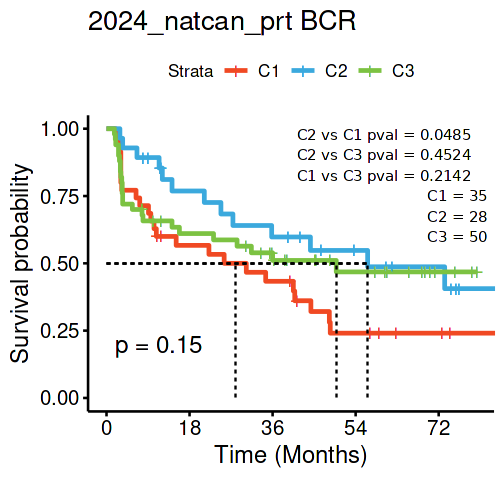

[1] "[ 2026-08-08 07:56:55 ]  write 1 pdf at report_c3/fig.S3F.S3G.S3H/fig.S3F.S3G.S3H.ext_2024_natcan_rna_BCR.pdf"
[1] "[ 2026-08-08 07:56:55 ]  read [ ext_data_2019_CancerCell_prt_data_pca.dfx ] as ' ext_data_2019_CancerCell_prt_data_pca ' from >  export_c3"
2019_CancerCell_prt BCR C2 C3 C1 


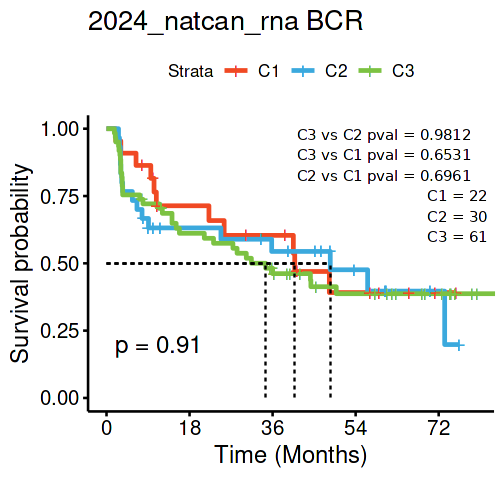

[1] "[ 2026-08-08 07:56:57 ]  write 1 pdf at report_c3/fig.S3F.S3G.S3H/fig.S3F.S3G.S3H.ext_2019_CancerCell_prt_BCR.pdf"
[1] "[ 2026-08-08 07:56:57 ]  read [ ext_data_2019_CancerCell_rna_data_pca.dfx ] as ' ext_data_2019_CancerCell_rna_data_pca ' from >  export_c3"
2019_CancerCell_rna BCR C2 C3 C1 


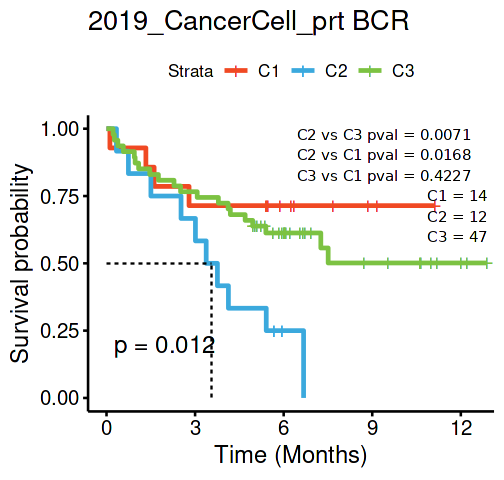

[1] "[ 2026-08-08 07:56:58 ]  write 1 pdf at report_c3/fig.S3F.S3G.S3H/fig.S3F.S3G.S3H.ext_2019_CancerCell_rna_BCR.pdf"


[1] "2016_TCGA OS"            "2016_TCGA DFS"          
 [3] "2018_Cancer_cell BCR"    "2019_PNAS OS"           
 [5] "2023_Mol_Cell OS"        "2024_CRM BCR"           
 [7] "2024_natcan_prt BCR"     "2024_natcan_rna BCR"    
 [9] "2019_CancerCell_prt BCR" "2019_CancerCell_rna BCR"

[1] "[ 2026-08-08 07:56:58 ]  write 1 xlsx at report_c3/fig.S3F.S3G.S3H/fig.S3F.S3G.S3H.ext_plot_data.xlsx"


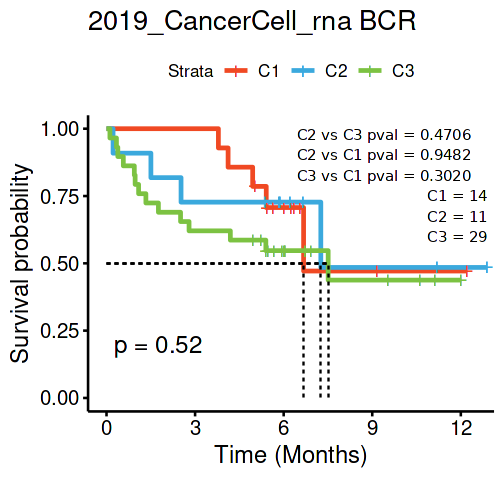

In [60]:
make.custom(4.2,4)

plots = list()
datas = list()
for (tag in glx){
    file = paste('ext_data',tag,'data_pca.dfx',sep='_')
    data = db.importing(file,frm='export_c3')
    x = colnames(data)
    x = x[x %>% str_detect('MONTH$')]
    surv_grps = x %>% str_sub(1,-7)
    for (grp in surv_grps){
        
        d = data %>% select(BCR_status = !!sym(paste0(grp,'_STATUS')),
                BCR_month = !!sym(paste0(grp,'_MONTH')),
                Group = Cluster) %>%
            filter(!is.na(BCR_status))
        if (max(d$BCR_month) > 200){
            d = d %>% mutate(BCR_month = round(BCR_month / 30, 1))
        }
        f = paste(tag,grp)
        datas[[f]] = d
        
        sur.gg = plot_bcr(d, ti = paste(tag, grp))
        gg = sur.gg$plot
        print(gg)
        plots[[length(plots)+1]] = gg
        gg %>% ysave('fig.S3F.S3G.S3H.ext',tag,grp, outputdir = file.path('report_c3','fig.S3F.S3G.S3H'))
    }
    
}

names(datas)
# datas %>% ysave('fig.S3F.S3G.S3H.ext_plot_data',outputdir = 'report_c3/fig.S3F.S3G.S3H')

In [59]:
data_all = list()
for (tag in glx){
    file = paste('ext_data',tag,'data_pca.dfx',sep='_')
    data = db.importing(file,frm='export_c3')
    data_all[[tag]] = data
}
data_all %>% ysave('fig.S3F.S3G.S3H.data.ext_survival',outputdir = OUTPUTROOT)


[1] "[ 2026-08-08 07:54:43 ]  read [ ext_data_2016_TCGA_data_pca.dfx ] as ' ext_data_2016_TCGA_data_pca ' from >  export_c3"
[1] "[ 2026-08-08 07:54:43 ]  read [ ext_data_2018_Cancer_cell_data_pca.dfx ] as ' ext_data_2018_Cancer_cell_data_pca ' from >  export_c3"
[1] "[ 2026-08-08 07:54:43 ]  read [ ext_data_2019_PNAS_data_pca.dfx ] as ' ext_data_2019_PNAS_data_pca ' from >  export_c3"
[1] "[ 2026-08-08 07:54:43 ]  read [ ext_data_2023_Mol_Cell_data_pca.dfx ] as ' ext_data_2023_Mol_Cell_data_pca ' from >  export_c3"
[1] "[ 2026-08-08 07:54:43 ]  read [ ext_data_2024_CRM_data_pca.dfx ] as ' ext_data_2024_CRM_data_pca ' from >  export_c3"
[1] "[ 2026-08-08 07:54:43 ]  read [ ext_data_2024_natcan_prt_data_pca.dfx ] as ' ext_data_2024_natcan_prt_data_pca ' from >  export_c3"
[1] "[ 2026-08-08 07:54:43 ]  read [ ext_data_2024_natcan_rna_data_pca.dfx ] as ' ext_data_2024_natcan_rna_data_pca ' from >  export_c3"
[1] "[ 2026-08-08 07:54:43 ]  read [ ext_data_2019_CancerCell_prt_data_pca.dfx ] 

## fig S1D S2D S2E S2F S2G

In [204]:
## calc tsne

In [134]:
clin2 = db.importing('external_data/Fig1_heatmap_clinical_pathological_information.txt') %>% 
    select(tsb = paitent.number, MD = MD.Anderson.classification) %>%
    mutate(MD=paste0('MD',MD))
clin2

[1] "[ 2026-08-08 08:22:05 ]  read [ Fig1_heatmap_clinical_pathological_information.txt ] as ' Fig1_heatmap_clinical_pathological_information ' from >  external_data"


tsb,MD
<chr>,<chr>
P01,MD1
P02,MD1
P03,MD1
⋮,⋮
P136,MD0
P137,MD1
P138,MD1


In [135]:
cc = db.importing('export_c3/fig1_subtype_column_cluster.dfx') %>% pull(cc)
# rc = db.importing('export_c3/fig1_subtype_row_cluster.dfx') %>% pull(rc)

[1] "[ 2026-08-08 08:22:06 ]  read [ fig1_subtype_column_cluster.dfx ] as ' fig1_subtype_column_cluster ' from >  export_c3"


In [136]:
mat_ordered = db.importing('export_c3/fig1_subtype_heatmap_mat.dfx', row.names=1)

tsb.order = colnames(mat_ordered)
grps = tsb.order %>% split(factor(cc))

glx_grps = data.frame(tsb=tsb.order, Group = cc) %>% 
    mutate(Response = ifelse(Group=='pCR', 'pCR','non.pCR')) %>% 
    arrange(match(tsb,colnames(matp86))) %>% 
    column_to_rownames("tsb") 
glx_grps


[1] "[ 2026-08-08 08:22:06 ]  read [ fig1_subtype_heatmap_mat.dfx ] as ' fig1_subtype_heatmap_mat ' from >  export_c3"


,Group,Response
,<chr>,<chr>
P01,C3,non.pCR
P02,C3,non.pCR
P03,C3,non.pCR
⋮,⋮,⋮
P84,C1,non.pCR
P85,C2,non.pCR
P86,C2,non.pCR


### rna tsne

In [137]:
rna_glx = db.importing('rna_glx',row.names=NULL,frm='export_86_7')
rna_glx

[1] "[ 2026-08-08 08:22:08 ]  read [ rna_glx.dfx ] as ' rna_glx ' from >  export_86_7"


Tumor_Sample_Barcode,a,t,p,ap,uid,Custom_Label,PSA,Treat_Res,NEPC,Cribriform,Group,Response,Response2,Clin_classification,Clustered_Response,RNA_Cluster,Protein_Cluster,sort_col,Response3
<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<dbl>,<int>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
P014,K00156,TR22030690,P230156145255401,K00156P230156145255401,1452554,P014,2.070,2,0,0,II,non.pCR,II,II,II,C3,C1,P14,non.pCR
P069,K00252,T147356823CA,P230252147356801,K00252P230252147356801,1473568,P069,0.230,1,0,0,I,non.pCR,I,I,I,C1,C2,P69,non.pCR
P066,K00208,TR22030719,P230208142178201,K00208P230208142178201,1421782,P066,0.162,1,0,0,I,non.pCR,I,I,I,C4,C1,P66,non.pCR
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
P021N,K00163,NR22314695K00163,P2300163143869201,K00163P2300163143869201,1438692,P021N,0,2,0,0,WT,pCR,WT,WT,WT,WT,WT,PN21,WT
P078N,K00261,NR22314694K00261,P2300261148223301,K00261P2300261148223301,1482233,P078N,0,0,0,0,WT,pCR,WT,WT,WT,WT,WT,PN78,WT
P076N,K00259,NR22314694K00259,P2300259148378501,K00259P2300259148378501,1483785,P076N,0,0,0,0,WT,pCR,WT,WT,WT,WT,WT,PN76,WT


In [138]:
normd = db.importing('rna_normd',frm='export_86_7', row.names=1)
normd

rna_glx = db.importing('rna_glx',row.names=NULL,frm='export_86_7') %>% 
    mutate(sort_col = Custom_Label %>% str_replace('^P0','P')) %>%
    column_to_rownames('sort_col')

colData = rna_glx %>% dplyr::select(NEPC, Response, Treat_Res=Response2)  
# colData[colData$,'Treat_Res']
colData

[1] "[ 2026-08-08 08:22:08 ]  read [ rna_normd.dfx ] as ' rna_normd ' from >  export_86_7"


,P14,P69,P66,P64,P47,P48,P29,P56,P24,P25,P31,P37,P49,P26,P51,⋯,P35,P61,P44,P27,P43,P57,P13,P12,P63,P67,P75N,P69N,P21N,P78N,P76N
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
A1BG,6.039308,5.752186,5.971944,5.914781,6.04516,6.174237,6.192476,6.045478,5.969158,6.074153,6.098018,6.192302,5.950010,6.087736,6.166208,⋯,6.045682,6.098747,6.050713,5.995912,5.829002,6.198718,6.078136,6.296769,6.072189,5.894071,5.676038,5.912615,5.977434,5.827421,6.149514
A1CF,7.086309,5.752186,5.971944,5.866011,6.48523,6.038423,6.192476,6.178142,6.318881,6.037638,7.483881,6.281635,6.697664,5.940570,6.067873,⋯,6.045682,5.847946,5.717969,5.825464,5.829002,6.096650,5.348776,5.844727,5.537389,6.432598,6.261118,5.951006,5.348776,5.786048,5.918568
A2M,14.106956,17.030916,17.012178,17.125880,17.50677,17.503104,17.515743,15.789399,18.226276,16.884340,19.070498,17.400235,16.472025,16.898942,17.461017,⋯,17.319996,18.622324,17.692000,17.379298,15.320722,17.061539,17.152016,17.565514,16.587668,17.897309,17.336042,17.944511,17.506036,18.638663,18.515101
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
ZYX,11.32709,11.52975,11.68925,11.70938,11.58794,11.93454,13.00501,11.67947,11.04728,12.13769,11.84424,11.85139,11.80396,12.14165,11.59807,⋯,11.48791,11.89892,11.42515,12.09637,11.76183,12.29819,11.71250,11.56424,11.65026,11.60231,11.36494,10.96760,11.15849,11.58696,11.37824
ZZEF1,12.74198,13.45745,13.08560,13.19233,12.94359,13.11021,13.49801,13.42761,13.18496,13.24338,12.97489,12.92394,13.55015,13.31529,13.01210,⋯,12.98035,13.39411,12.93821,12.98503,13.41655,13.44733,13.28673,13.35124,13.23400,13.11684,12.83688,12.77972,12.89298,12.82714,12.64121
ZZZ3,11.77881,12.69460,11.32920,11.52829,11.69872,11.49958,11.81505,11.76804,11.96361,12.15077,11.61888,11.79923,11.75583,11.82749,11.25477,⋯,11.79486,11.53923,11.71731,11.52483,12.13401,11.57124,11.49814,11.33216,11.49223,11.65741,12.28698,12.44563,12.40404,12.43721,12.55490


[1] "[ 2026-08-08 08:22:11 ]  read [ rna_glx.dfx ] as ' rna_glx ' from >  export_86_7"


,NEPC,Response,Treat_Res
,<int>,<chr>,<chr>
P14,0,non.pCR,II
P69,0,non.pCR,I
P66,0,non.pCR,I
⋮,⋮,⋮,⋮
P21N,0,pCR,WT
P78N,0,pCR,WT
P76N,0,pCR,WT


In [139]:
stopifnot(all(colnames(normd) == rownames(colData)))

In [140]:
set.seed(42)
res.tsne = yplot_tsne(normd = normd, colData = colData, add_label = F, color_col = 'Response', .ret=TRUE)

tsne =  res.tsne$data %>% rownames_to_column('Custom_Label')
mask = tsne$Custom_Label %>% str_ends('N')
tsne[mask,'NEPC'] = 'N'
tsne %<>% mutate(across(where(is.character),factor))
tsne


Custom_Label,X1,X2,NEPC,Response,Treat_Res
<fct>,<dbl>,<dbl>,<fct>,<fct>,<fct>
P14,-0.7292600,3.3963659,0,non.pCR,II
P69,0.8114946,-2.6076621,0,non.pCR,I
P66,-0.9037107,0.7322267,0,non.pCR,I
⋮,⋮,⋮,⋮,⋮,⋮
P21N,3.391717,0.37762639,N,pCR,WT
P78N,4.148830,0.11275098,N,pCR,WT
P76N,4.062376,0.07154604,N,pCR,WT


In [141]:
## save rna.tsne result as export_86_7/rna_tsne.dfx
# tsne %>% ydumptopto('rna_tsne',outputdir = 'export_86_7/')

In [142]:
# need data @clin2
data.rna = db.importing('export_86_7/rna_tsne.dfx', row.names=1) %>% rename(tsb= Custom_Label)%>%
    left_join(glx_grps %>% rownames_to_column('tsb')) %>% fill_na('adj') %>%
    left_join(clin2) %>%  fill_na('x')  %>%
    mutate(adj = ifelse(MD=='x','x','o')) %>%
    mutate(Response = ifelse(Group=='adj', 'adj', Response))
stopifnot(nrow(data.rna)==93)

data.rna

[1] "[ 2026-08-08 08:22:13 ]  read [ rna_tsne.dfx ] as ' rna_tsne ' from >  export_86_7"


Joining with `by = join_by(tsb, Response)`
Joining with `by = join_by(tsb)`


tsb,X1,X2,NEPC,Response,Treat_Res,Group,MD,adj
<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
P14,-0.7710010,3.2678497,1,non.pCR,II,C1,MD2,o
P69,-3.3515556,-0.4888828,0,non.pCR,I,C2,MD1,o
P66,-0.4123339,0.4169099,0,non.pCR,I,C1,MD1,o
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
P21N,3.383456,0.5563732,N,adj,WT,adj,x,x
P78N,4.212795,0.5740257,N,adj,WT,adj,x,x
P76N,4.145012,0.6295607,N,adj,WT,adj,x,x


### prt tsne

In [143]:
matp86 = db.importing('export_by2_86_pCR_nonpCR/prt_ori_7717.dfx',row.names=1)  
# matp.all = matp86 %>% select(any_of(!!nonpcr))
matp86

[1] "[ 2026-08-08 08:22:13 ]  read [ prt_ori_7717.dfx ] as ' prt_ori_7717 ' from >  export_by2_86_pCR_nonpCR"


,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,⋯,P72,P73,P74,P75,P76,P77,P78,P79,P80,P81,P82,P83,P84,P85,P86
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
A0A075B6H7_IGKV3-7,0.12451336,0.4955196,-0.3711220,-0.158574158,0.06603518,-0.3180114,-0.1643087,-0.1150273,-0.09916304,-0.4484990,-0.02422203,0.07632674,0.19945979,-0.1562199,0.14721337,⋯,-0.5189750,0.07983898,-0.5506821,0.03085606,-0.2335839,0.0256045,0.13548722,0.31490744,-0.1473353,0.3600466,0.2414009,0.00796921,0.3641878,0.03076137,0.12781938
A0A075B6H9_IGLV4-69,-0.06708622,1.4101545,-0.2789730,-0.003141405,0.07562503,0.1904300,-0.5346399,-0.4821584,-0.43113235,0.2959602,-0.01954511,0.17738055,0.00348254,0.3788943,-0.02022209,⋯,-1.3889889,0.15381940,1.1407413,-0.30391723,-0.6050451,-0.5183422,-0.55198116,-0.09405559,0.9489220,0.6305536,0.2314848,0.32359624,0.4244280,-0.18387480,-0.21528331
A0A075B6I0_IGLV8-61,0.52198543,-0.8202753,-0.0447255,0.363312741,-0.08782118,0.5239861,-0.2197025,0.5250697,0.19749617,0.2776494,-0.79113806,0.22355302,0.08137378,-0.4057821,-0.49653496,⋯,-0.8614086,-1.25326939,0.7563697,-0.10147089,0.4426649,0.3570044,-0.04694244,-1.07691376,0.4291992,0.5550154,0.5311064,0.69323898,-0.7764235,-0.72724793,0.06790018
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
Q9Y6X8_ZHX2,-0.09289445,-0.23945071,0.152439462,-0.17563341,-0.05550520,0.04360795,0.04901209,0.19872610,-0.162558356,-0.3290601,0.016181906,0.10451032,0.04421963,-0.005092286,0.01949250,⋯,0.1701639,-0.15682723,-0.13862951,0.03102477,-0.065812190,0.01851051,0.04535733,0.82408510,-0.19091712,-0.004119983,-0.27649772,0.02017211,-0.11858497,-0.2278572,-0.20392782
Q9Y6X9_MORC2,0.01243174,-0.01834729,0.133878026,-0.06848901,0.03452091,0.19522122,0.12452125,0.03180349,-0.008927529,0.1397689,0.172721392,-0.16295547,-0.01264276,0.060436917,0.03145336,⋯,0.2997386,0.02437514,0.02096558,0.04426970,0.004298018,-0.04039725,-0.00758186,-0.07881549,-0.19896226,-0.026629123,0.08300860,-0.02351065,0.06894126,0.1158237,0.18455826
Q9Y6Y8_SEC23IP,-0.08680557,0.11525567,-0.008570729,-0.04426972,-0.01208452,0.00090900,-0.09794350,0.09902210,0.037650439,0.1909942,0.002257704,0.02724321,0.02156858,-0.020346078,0.01017290,⋯,0.4948314,-0.01232757,-0.07756265,-0.00026200,0.037980680,-0.17187753,0.01744070,-0.25664841,-0.01884388,-0.026359660,0.05317427,-0.02653868,-0.06877405,-0.0143202,-0.04214858


In [144]:
stopifnot(all(colnames(matp86) == rownames(glx_grps)))

In [145]:
set.seed(38)
res.prt.tsne = yplot_tsne(normd = matp86
                          , colData = glx_grps
                          , .ret = TRUE)
res.prt.tsne$data %>% ydumpto('prt_tsne.dfx',outputdir = 'export_86_7')
res.prt.tsne$data

[1] "[ 2026-08-08 08:22:14 ]  write 1 < dfx > at export_86_7/prt_tsne.dfx"


[1] "export_86_7/prt_tsne.dfx"

,X1,X2,Group,Response
,<dbl>,<dbl>,<chr>,<chr>
P01,-0.3408629,-1.0067815,C3,non.pCR
P02,0.9572325,-0.9308931,C3,non.pCR
P03,0.6644815,1.7321274,C3,non.pCR
⋮,⋮,⋮,⋮,⋮
P84,0.9034259,-0.6505127,C1,non.pCR
P85,3.0628399,0.4880557,C2,non.pCR
P86,-0.4600007,-1.4836393,C2,non.pCR


In [146]:
data.prt = db.importing('export_86_7/prt_tsne.dfx', row.names=1) %>% 
    rownames_to_column('tsb') %>%
    left_join(glx_grps %>% rownames_to_column('tsb')) %>% fill_na('adj') %>%
    left_join(clin2) %>%  fill_na('x')  %>% 
    mutate(MD=as.character(MD)) %>%
    mutate(adj = ifelse(MD=='x','x','o'))
stopifnot(nrow(data.prt)==86)
data.prt

[1] "[ 2026-08-08 08:22:14 ]  read [ prt_tsne.dfx ] as ' prt_tsne ' from >  export_86_7"


Joining with `by = join_by(tsb, Group, Response)`
Joining with `by = join_by(tsb)`


tsb,X1,X2,Group,Response,MD,adj
<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
P01,-0.3408629,-1.0067815,C3,non.pCR,MD1,o
P02,0.9572325,-0.9308931,C3,non.pCR,MD1,o
P03,0.6644815,1.7321274,C3,non.pCR,MD1,o
⋮,⋮,⋮,⋮,⋮,⋮,⋮
P84,0.9034259,-0.6505127,C1,non.pCR,MD1,o
P85,3.0628399,0.4880557,C2,non.pCR,MD2,o
P86,-0.4600007,-1.4836393,C2,non.pCR,MD1,o


### save data

In [147]:
list('data.prt'=data.prt,'data.rna'=data.rna) %>% ysave('fig.S2D.S2E.S2F.S2G.data.tSNE',outputdir = OUTPUTROOT)

[1] "[ 2026-08-08 08:22:14 ]  write 1 xlsx at report_c3/fig.S2D.S2E.S2F.S2G.data.tSNE.xlsx"


### fig S1D

In [148]:
clin2

tsb,MD
<chr>,<chr>
P01,MD1
P02,MD1
P03,MD1
⋮,⋮
P136,MD0
P137,MD1
P138,MD1


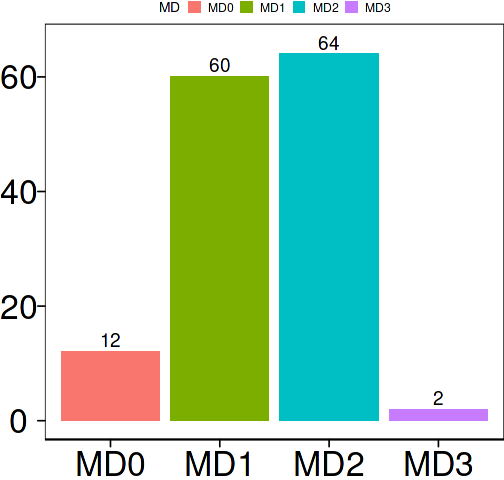

In [149]:
make.custom(4.2,4)
md_count_data = clin2 %>% group_by(MD) %>% 
    summarise(Patient_Num=n())
gg = md_count_data %>% 
    ggplot(aes(x=MD,y=Patient_Num, fill=MD)) +
        geom_bar(stat = 'identity') +
        geom_text(aes(label=Patient_Num),nudge_y = 2) + 
        theme_pc()
gg

In [218]:
gg %>% ysave('fig.S1D.MD_count_barplot',outputdir = OUTPUTROOT)
md_count_data %>% ysave('fig.S1D.MD_count_barplot',outputdir = OUTPUTROOT)

[1] "[ 2026-08-03 08:48:14 ]  write 1 pdf at report_c3/fig.S1D.MD_count_barplot.pdf"
[1] "[ 2026-08-03 08:48:14 ]  write 1 xlsx at report_c3/fig.S1D.MD_count_barplot.xlsx"


### fig S2D

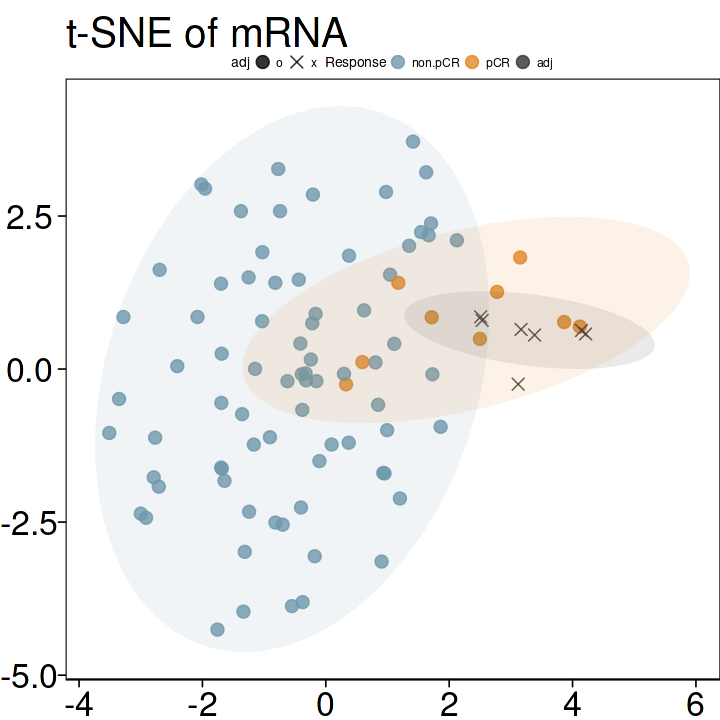

In [150]:
make.custom(6,6)
sel = 'Response'
COL_ANNO$Response = c(non.pCR='#6F99ADFF',pCR='#E18727FF',adj='gray20')
gg.pca.rna.rp = data.rna %>% 
    ggplot(aes(x=X1,y=X2,color=!!sym(sel), shape = adj)) +
    geom_point(alpha = 0.8,size=3) +
    stat_ellipse(aes(fill=!!sym(sel)), color=NA, geom = "polygon",alpha=0.1,lwd = 0.5,show.legend = FALSE) +
    theme_pc() +
#     ggrepel::geom_text_repel(aes(label=Custom_Label),size=2.5,show.legend = FALSE)+
    scale_color_manual(breaks=names(COL_ANNO[[sel]]),values = COL_ANNO[[sel]]) +
    scale_fill_manual(breaks=names(COL_ANNO[[sel]]),values = COL_ANNO[[sel]]) +
    scale_shape_manual(breaks = c('o','x'),values = c(19,4)) +
    ggtitle('t-SNE of mRNA')
gg.pca.rna.rp

In [151]:
gg.pca.rna.rp %>% ysave('fig.S2D.tSNE.RNA.response', outputdir = OUTPUTROOT)

[1] "[ 2026-08-08 08:22:31 ]  write 1 pdf at report_c3/fig.S2D.tSNE.RNA.response.pdf"


### fig S2E

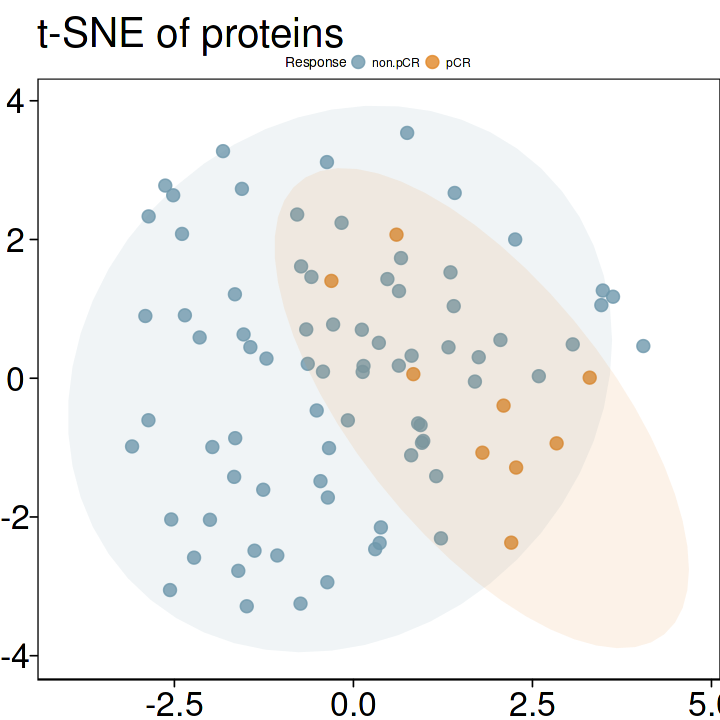

In [152]:
make.custom(6,6)
sel = 'Response'
COL_ANNO$Response = c(non.pCR='#6F99ADFF', pCR='#E18727FF')
gg.pca.prt.rp = data.prt %>% 
    ggplot(aes(x=X1,y=X2,color=!!sym(sel))) +
    geom_point(alpha = 0.8,size=3) +
    stat_ellipse(aes(fill=!!sym(sel)), color=NA, geom = "polygon",alpha=0.1,lwd = 0.5,show.legend = FALSE) +
    theme_pc() +
#     ggrepel::geom_text_repel(aes(label=Custom_Label),size=2.5,show.legend = FALSE)+
    scale_color_manual(breaks=names(COL_ANNO[[sel]]),values = COL_ANNO[[sel]]) +
    scale_fill_manual(breaks=names(COL_ANNO[[sel]]),values = COL_ANNO[[sel]]) +
    ggtitle('t-SNE of proteins')
gg.pca.prt.rp

In [153]:
gg.pca.prt.rp %>% ysave('fig.S2E.tSNE.prt.response', outputdir = OUTPUTROOT)

[1] "[ 2026-08-08 08:22:32 ]  write 1 pdf at report_c3/fig.S2E.tSNE.prt.response.pdf"


### fig S2F

Too few points to calculate an ellipse


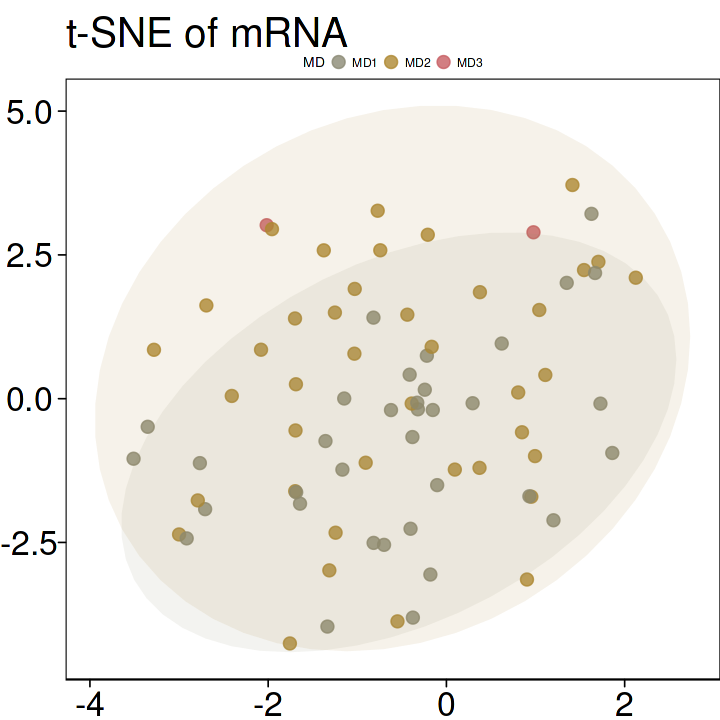

In [154]:
make.custom(6,6)
sel = 'MD'
COL_ANNO$MD = c(MD1='#8b8a75',MD2='#ae8833',MD3='#c75e63')
gg.pca.rna.md = data.rna %>% 
    filter(Group %in% c('C1','C2','C3')) %>%
    ggplot(aes(x=X1,y=X2,color=!!sym(sel))) +
    geom_point(alpha = 0.8,size=3) +
    stat_ellipse(aes(fill=!!sym(sel)), color=NA, geom = "polygon",alpha=0.1,lwd = 0.5,show.legend = FALSE) +
    theme_pc() +
#     ggrepel::geom_text_repel(aes(label=Custom_Label),size=2.5,show.legend = FALSE)+
#     geom_text(aes(label = tsb), nudge_x = 0.2, nudge_y = 0.4) + 
    scale_color_manual(breaks=names(COL_ANNO[[sel]]),values = COL_ANNO[[sel]]) +
    scale_fill_manual(breaks=names(COL_ANNO[[sel]]),values = COL_ANNO[[sel]]) +
    ggtitle('t-SNE of mRNA') 
gg.pca.rna.md

In [155]:
gg.pca.rna.md %>% ysave('fig.S2F.tSNE.RNA.MD', outputdir = OUTPUTROOT)

Too few points to calculate an ellipse


[1] "[ 2026-08-08 08:22:33 ]  write 1 pdf at report_c3/fig.S2F.tSNE.RNA.MD.pdf"


### fig S2G

Too few points to calculate an ellipse


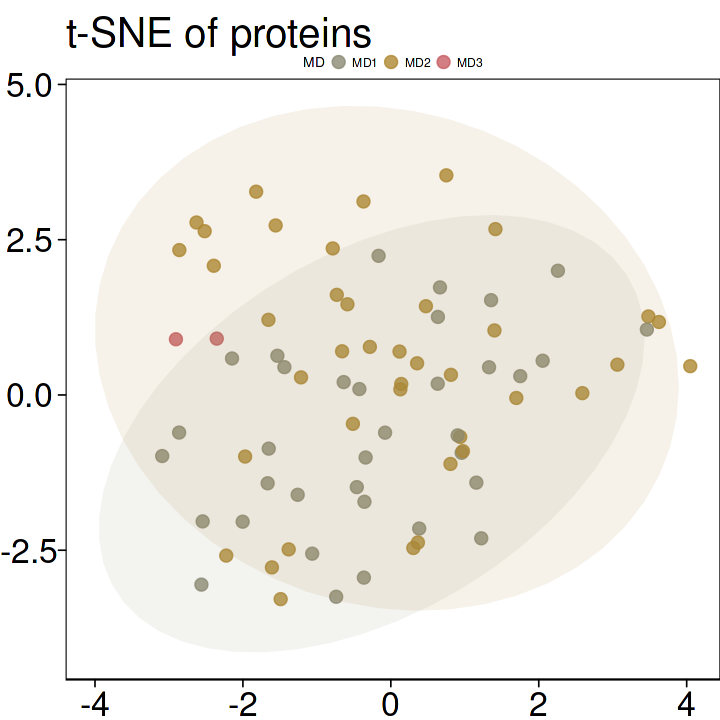

In [156]:
make.custom(6,6)
sel = 'MD'
COL_ANNO$MD = c(MD1='#8b8a75',MD2='#ae8833',MD3='#c75e63')

gg.pca.prt.md = data.prt %>% 
    filter(Group %in% c('C1','C2','C3')) %>%
    ggplot(aes(x=X1,y=X2,color=!!sym(sel))) +
    geom_point(alpha = 0.8,size=3) +
    stat_ellipse(aes(fill=!!sym(sel)), color=NA, geom = "polygon",alpha=0.1,lwd = 0.5,show.legend = FALSE) +
    theme_pc() +
#     ggrepel::geom_text_repel(aes(label=Custom_Label),size=2.5,show.legend = FALSE)+
#     geom_text(aes(label = tsb), nudge_x = 0.2, nudge_y = 0.4) + 
    scale_color_manual(breaks=names(COL_ANNO[[sel]]),values = COL_ANNO[[sel]]) +
    scale_fill_manual(breaks=names(COL_ANNO[[sel]]),values = COL_ANNO[[sel]]) +
    ggtitle('t-SNE of proteins') 
gg.pca.prt.md


In [157]:
gg.pca.prt.md %>% ysave('fig.S2G.tSNE.prt.MD', outputdir = OUTPUTROOT)

Too few points to calculate an ellipse


[1] "[ 2026-08-08 08:22:35 ]  write 1 pdf at report_c3/fig.S2G.tSNE.prt.MD.pdf"


## (not in article) RNA-protein correlation & GSEA-correlation heatmap; formerly fig S2H S2I S2J

In [224]:
plot_cor = function(matr,matp,method = 'spearman',bins=120,groupto=2, title=NULL){
#     lab.df = data.frame(line.pos = c(-0.2,0.2,0.4,1)
#                     ,lab.pos = c(-0.3,0,0.3,0.7)
#                     ,lab = c('Negative','No','WeakPositive','StrongPositive'))
    if (groupto==2){
        the.colors = c('#00ACE6', '#ED1C25')
        names(the.colors) = c('Negative','Positive')
        COL = sym("dir")
    }else if (groupto==4){
        the.colors = c(npg[1],'gray',npg[2],npg[4])
        names(the.colors)= c('Negative','No','WeakPositive','StrongPositive')
        COL = sym("bin")
    }else{
        stop("groupto must in c(2,4)")
    }
    
    r.all = c()
    i.all = c()
    p.all = c()
    npg = ggsci::pal_npg()(10)
    options(warn = -1)
    for (i in colnames(matr)){
        x = matp[,i]
        y = matr[,i]
        r = cor.test(x,y,method = method)
        r.all = c(r.all,r$estimate[[1]])
        i.all = c(i.all,i)
        p.all = c(p.all,r$p.value)
    }
    options(warn = 0)
    res = data.frame(list(symbol=i.all,cor=r.all,p=p.all)) %>% 
        mutate(cor.abs = abs(cor)
               , neg = cor<0
               , p.adj = p.adjust(p,method = 'BH')
               , bin = cut(cor,
                          ,breaks = c(-Inf,-0.2,0.2,0.4,Inf)  
                          ,labels=c("Negative",'No','WeakPositive','StrongPositive')),
               , dir = cut(cor
                           ,breaks = c(-Inf,0,Inf)
                           ,labels = c("Negative",'Positive')
                          )
               
              )
    
    me.pos = median(res$cor,na.rm = TRUE)
    ra.pos = 1 - mean(res$neg,na.rm=TRUE)
    res.sig = res %>% filter(p.adj<0.05)
    ra.pos.sig = (sum(res.sig$neg == FALSE,na.rm=TRUE) / nrow(res))
    
    l1 = paste0(ncol(matp),' mRNA-protein paires')
    l2 = paste0(round(ra.pos*100,2),'% positive correlation')
    l3 = paste0(round(ra.pos.sig*100,2),"% significant Positive correlation,\n(adjust pvalue < 0.05)")
    labelx = str_flatten(c(l1,l2,l3),collapse = "\n")
    
    gg = res %>% ggplot(aes(x=cor)) +
        geom_histogram(aes(fill=!!COL,color=!!COL),bins = bins,alpha=1,linewidth = 0.2) +
        scale_fill_manual(values = the.colors,breaks = names(the.colors)) +
        scale_color_manual(values = the.colors,breaks = names(the.colors)) +
        theme_minimal(base_size = 16) +
        geom_vline(xintercept = me.pos,color='black',linetype='longdash') +
        geom_text(x=me.pos,y=Inf,family='Helvetica',size=8,label=paste('Median r =',signif(me.pos,3)),vjust=1) +
#         geom_text(data=lab.df, aes(x = lab.pos,label=lab), y = Inf, family = "Helvetica", size = 6, hjust=0.5, vjust = 1)+ 
        geom_text(x=-Inf,y=Inf,family='Helvetica',size=4, label = labelx,hjust=0,vjust=1) +
        xlab(paste0(method %>% str_to_title,"'s Correlation"))+
        ylab('Probability Density')+
        ggtitle(title)
    #     scale_x_continuous(limits = c(0,1))
    print(labelx)
    make.custom(12,8)
    print(gg)
    return(list(tb=res,gg=gg,tb.sig=res.sig))
}


yplot_cor_heatmap = function(gsea.res.tb, cor.relation.df, cor.column = 'mp_cor', filter.p = 1, filter.padj = 0.05, bins= 400){
    
    x = gsea.res.tb %>% filter(p.adjust < filter.padj, pvalue < filter.p)
    if (nrow(x)<1){
        message("GSEA result left 0 rows after applying the [filter.p] and [filter.padj] filter.")
        return(list(mat.bins=NULL,mat.stat=NULL, cor.relation=NULL, heatmap=NULL))
    }
    li.all = x$core_enrichment %>% str_split('/')
    names(li.all) = x$ID

    cor.relation = cor.relation.df[order(cor.relation.df[[cor.column]]),] %>% na.omit()
    cor.relation$bin2 = cor.relation[[cor.column]] %>% cut(breaks = bins)
    
    
    if ('symbol' %in% colnames(cor.relation)){
        ns = cor.relation$symbol
        rownames(cor.relation) = ns
    }else{
        ns = rownames(cor.relation)
    }
    
    mat = cor.relation %>% distinct(bin2)
    rownames(mat) = mat[,'bin2']
    mat[,'bin2'] = 0
    
    cors = cor.relation[,cor.column]
    names(cors) = rownames(cor.relation)

    s = sign(cors)
    
    mat.stat.mean = c()
    mat.stat.median = c()
    mat.stat.p.adj = c()

    for (i in names(li.all)){
        li = li.all[[i]]
        id = intersect(li,ns)

        col = rep(0,nrow(cor.relation))
        names(col) = rownames(cor.relation)
        col[id] = 1
        col = col * s
        cor.relation$value = col

        col2 = cor.relation %>% group_by(bin2) %>% summarise(value = max(value)) %>% pull(value)
        mat = cbind(mat,col2)

        mat.stat.mean = c(mat.stat.mean,mean(cors[id]))
        mat.stat.median = c(mat.stat.median,median(cors[id]))
        mat.stat.p.adj = c(mat.stat.p.adj,x[i,'p.adjust'])

    }
    colnames(mat)[2:ncol(mat)] = names(li.all)
    mat.stat = data.frame(i= names(li.all)
                          ,mean= mat.stat.mean
                          ,median = mat.stat.median
                          ,p.adj = mat.stat.p.adj
                         )
    mat2 = mat[,2:ncol(mat)] %>% t
    ns = paste0(rownames(mat2)," (",round(mat.stat[,'mean'],3),'; p = ',signif(mat.stat[,'p.adj'],5),")")
    rownames(mat2) = ns

    res.hm = ComplexHeatmap::Heatmap(mat2,show_heatmap_legend = FALSE,
                    ,border_gp = grid::gpar(col = "black", lty = 1)
                    ,rect_gp = grid::gpar(col = "white", lwd = 0.5)
                    ,heatmap_legend_param = list(direction = "horizontal")
                    ,row_names_side = 'left'
                    ,row_names_max_width = unit(6.5,'inch')
                    ,col = structure(c(npg[2], "white", npg[1]),names=c(-1, 0, 1))
                    ,cluster_columns = FALSE
                    ,cluster_rows = FALSE
                    ,show_row_dend = FALSE
                    ,show_column_names = FALSE
                 )
    list(mat.bins=mat2,mat.stat=mat.stat, cor.relation=cor.relation, heatmap=res.hm)
}

In [225]:
matr = db.importing('export_86_7/x_matr_tpm_86_7436.dfx',row.names=1,header=TRUE) %>% as.matrix 
matp = db.importing('export_86_7/x_matp_86_7436.dfx',row.names=1,header=TRUE) %>% as.matrix 

[1] "[ 2026-08-03 08:48:15 ]  read [ x_matr_tpm_86_7436.dfx ] as ' x_matr_tpm_86_7436 ' from >  export_86_7"
[1] "[ 2026-08-03 08:48:18 ]  read [ x_matp_86_7436.dfx ] as ' x_matp_86_7436 ' from >  export_86_7"


[1] "7436 mRNA-protein paires\n81.54% positive correlation\n31.72% significant Positive correlation,\n(adjust pvalue < 0.05)"


Warning message:
“Removed 16 rows containing non-finite values (`stat_bin()`).”


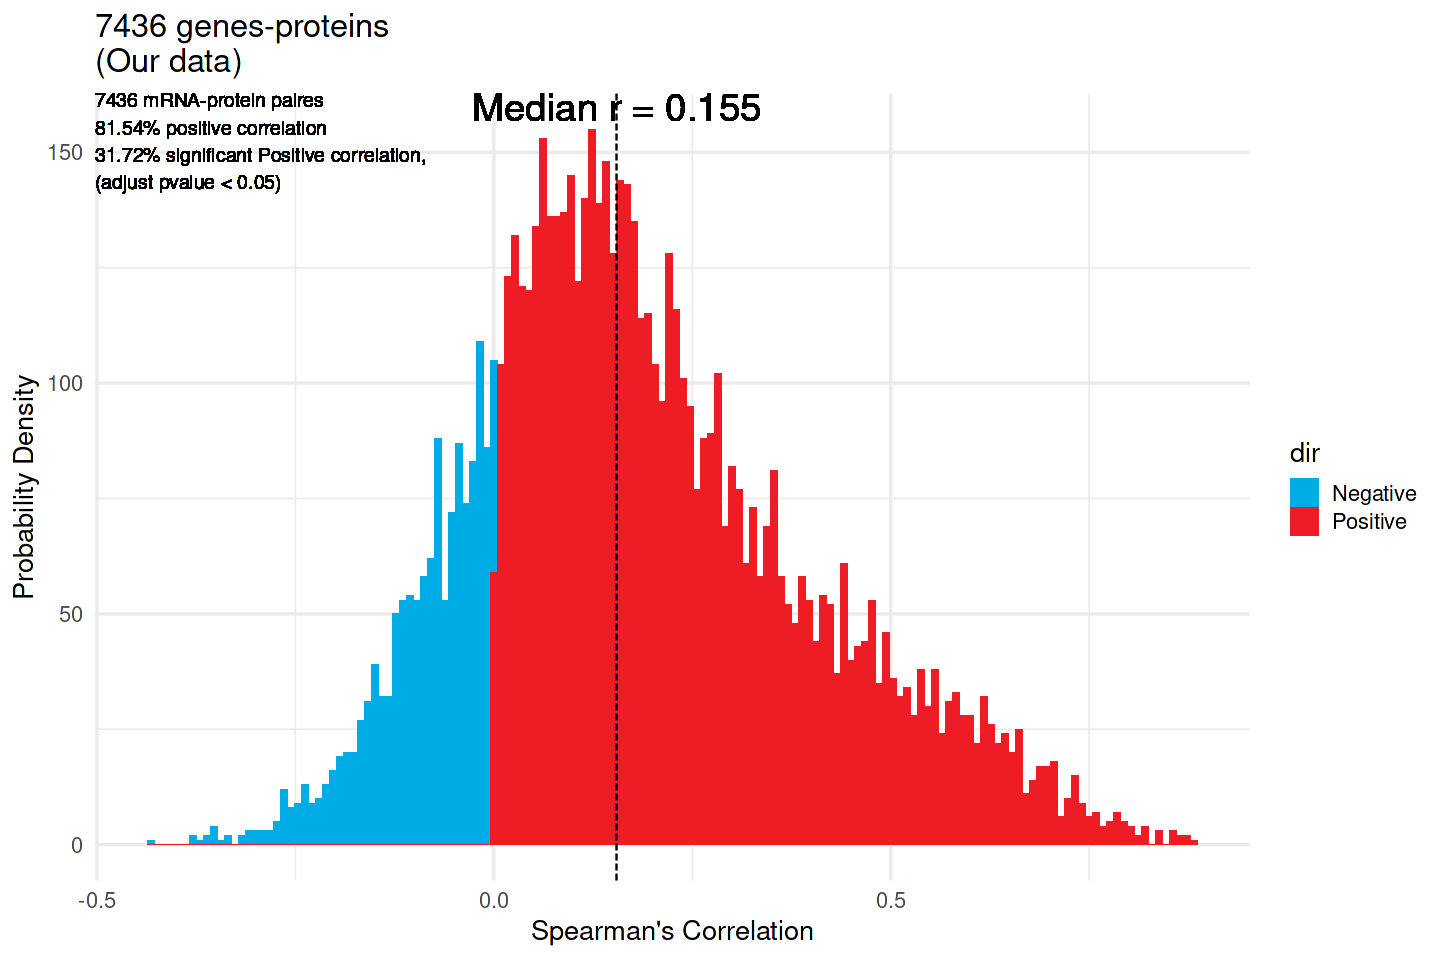

In [226]:
res.cor.all = plot_cor(matr, matp
                    , bins = 150
                    , title = paste("7436 genes-proteins\n(Our data)"))


### (not in article) GSEA-correlation heatmap, formerly fig S2J

* use `res.cor.all` generated by cell `plot_cor(matr, matp)` above

* add $heatmap.gsea to the `res.cor.all`


In [231]:
rna_sd = (matr+0.001) %>% log %>% apply(2,function(i){sd(i,na.rm = TRUE)})
protein_sd = matp %>% apply(2,function(i){sd(i,na.rm = TRUE)})
stopifnot(all(colnames(matr) == colnames(matp)))
data = data.frame(rna_sd=rna_sd,protein_sd=protein_sd)

stopifnot(all(res.cor.all$tb$symbol == colnames(matp)))

mp_cor = res.cor.all$tb$cor
cor_name = 'mp_cor'
log_corname = paste0('log.',cor_name)

data[[cor_name]] = mp_cor
data[[log_corname]] = log(mp_cor+1)
data[[paste0('bin.',cor_name)]] = cut(data[[cor_name]],breaks = c(-Inf,-0.2,0.2,0.4,Inf)
             ,labels=c("Negative",'No','WeakPositive','StrongPositive'))

data = data %>% rownames_to_column('symbol')
cor.data = data
cor.data

symbol,rna_sd,protein_sd,mp_cor,log.mp_cor,bin.mp_cor
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
A1BG,0.9619936,0.2303506,0.0767304,0.07392904,No
A2M,0.6193923,0.3662173,0.4677107,0.38370387,StrongPositive
NAT1,0.5160300,0.2690078,0.5404878,0.43209909,StrongPositive
⋮,⋮,⋮,⋮,⋮,⋮
MMP24OS,0.3533946,0.3125662,0.02718053,0.02681770,No
PIGBOS1,1.8506818,0.4018671,-0.08836938,-0.09252039,No
C11orf98,0.6446678,0.2869796,0.12889441,0.12123876,No


In [232]:
# gen $gsea.cor
cn = 'mp_cor'
sym_cn = sym(cn)

cor.list = data %>% arrange(desc(!!sym_cn)) %>% pull(sym_cn,name = 'symbol') %>% na.omit    

cor.list %>% length

gsea.cor = ydo_GSEA(gene_list = cor.list, set = 'gsea', 
                    p.t = 1, p.adjust.t = 0.1, 
                    pvalueCutoff = 0.5)

res.cor.all$gsea.cor = gsea.cor


[1] 7420

run 2 Enrichments hm, kegg

preparing geneSet collections...

GSEA analysis...

Warning message in preparePathwaysAndStats(pathways, stats, minSize, maxSize, gseaParam, :
“There are ties in the preranked stats (8.3% of the list).
The order of those tied genes will be arbitrary, which may produce unexpected results.”
Warning message in fgseaMultilevel(...):
“For some pathways, in reality P-values are less than 1e-10. You can set the `eps` argument to zero for better estimation.”
leading edge analysis...

done...



[1] "after filter, 32 significant results left"


preparing geneSet collections...

GSEA analysis...

Warning message in preparePathwaysAndStats(pathways, stats, minSize, maxSize, gseaParam, :
“There are ties in the preranked stats (8.3% of the list).
The order of those tied genes will be arbitrary, which may produce unexpected results.”
Warning message in fgseaMultilevel(...):
“There were 5 pathways for which P-values were not calculated properly due to unbalanced (positive and negative) gene-level statistic values. For such pathways pval, padj, NES, log2err are set to NA. You can try to increase the value of the argument nPermSimple (for example set it nPermSimple = 10000)”
Warning message in fgseaMultilevel(...):
“For some of the pathways the P-values were likely overestimated. For such pathways log2err is set to NA.”
Warning message in fgseaMultilevel(...):
“For some pathways, in reality P-values are less than 1e-10. You can set the `eps` argument to zero for better estimation.”
leading edge analysis...

done...



[1] "after filter, 54 significant results left"


GSEA analysis done, now you can use yplot_



In [233]:
cn ="mp_cor"
sym_cn = sym(cn)
j = 'hm'
hm.cor = yplot_cor_heatmap(res.cor.all$gsea.cor[[j]]$res.tb.gsea, cor.data, cor.column = cn)

res.cor.all$heatmap.gsea = hm.cor


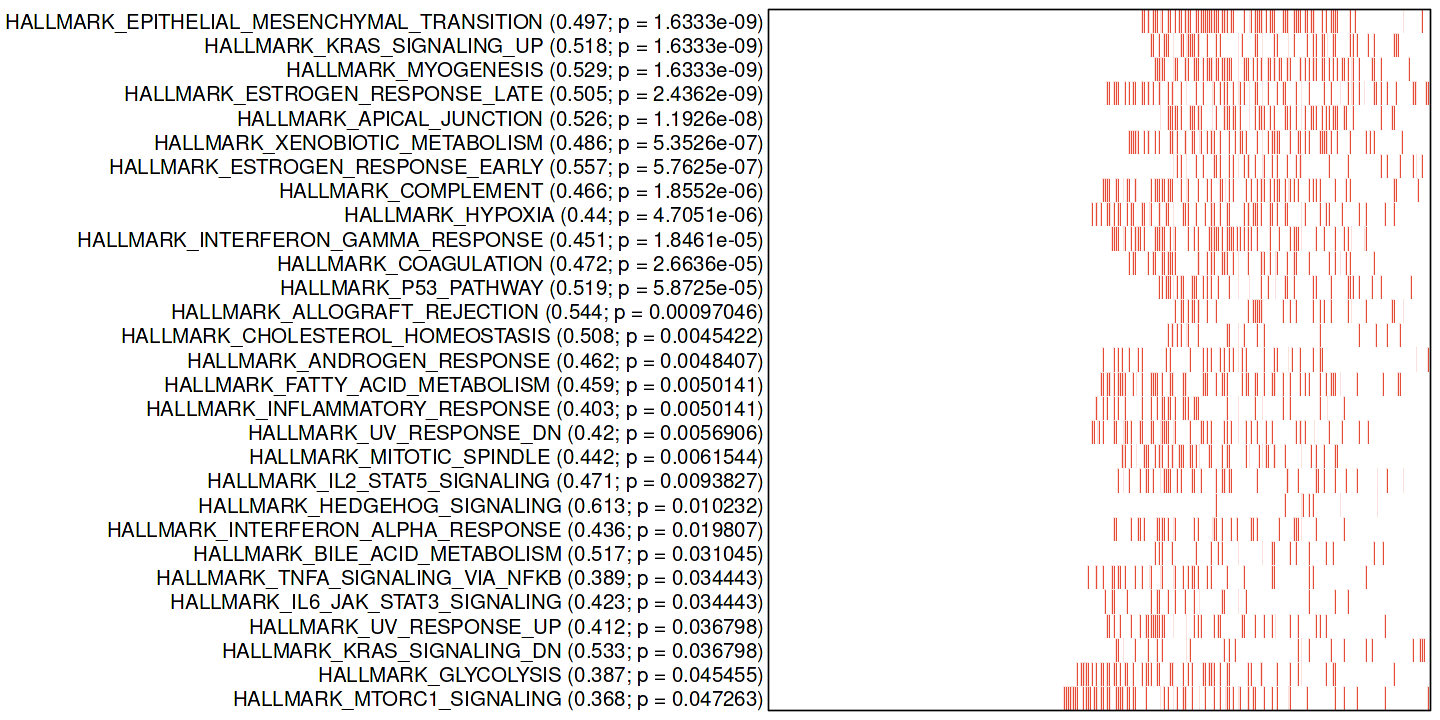

In [234]:
make.custom(12,6)
res.cor.all$heatmap.gsea$heatmap

In [235]:
res.cor.all$heatmap.gsea$heatmap %>% ysave('fig.unused','hm_gsea_correlation',outputdir = OUTPUTROOT)
res.cor.all$heatmap.gsea$mat.bins %>% as.data.frame %>% ysave('fig.unused','hm_gsea_correlation',outputdir = OUTPUTROOT)

[1] "[ 2026-08-03 08:48:55 ]  write 1 pdf at report_c3/fig.unused_hm_gsea_correlation.pdf"
[1] "[ 2026-08-03 08:48:55 ]  write 1 xlsx at report_c3/fig.unused_hm_gsea_correlation.xlsx"


In [241]:
cat(format(Sys.time(), "%Y-%m-%d %H:%M:%S"), "Job Done")


2026-08-03 08:52:08 Job Done